# Dự báo Nhu cầu Tiêu thụ Nước bằng Mô hình Chuỗi Thời gian ARIMA

Nghiên cứu dự báo nhu cầu tiêu thụ nước (Water Consumption Demand Forecasting) dựa trên dữ liệu lịch sử theo giờ sử dụng mô hình ARIMA cổ điển. Notebook được thiết kế chi tiết, rõ ràng và khoa học phục vụ cho mục đích nghiên cứu và báo cáo.

## PHẦN 1. IMPORT THƯ VIỆN

Chúng ta sẽ cài đặt và nhập các thư viện cần thiết cho việc xử lý dữ liệu, kiểm định thống kê, xây dựng mô hình ARIMA và trực quan hóa kết quả.

In [1]:
import os
import shutil
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Statsmodels cho phân tích chuỗi thời gian
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

# Scikit-learn để đánh giá mô hình
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Thiết lập hiển thị biểu đồ và bỏ qua cảnh báo không cần thiết
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
warnings.filterwarnings('ignore')
print("Đã import thành công tất cả các thư viện cần thiết.")

Đã import thành công tất cả các thư viện cần thiết.


## PHẦN 2. THU THẬP VÀ ĐỌC DỮ LIỆU

Phần này cho phép người dùng trực tiếp tải lên tệp CSV chứa dữ liệu lượng nước tiêu thụ thực tế.

In [2]:
from google.colab import files

print("Vui lòng chọn và tải lên file dữ liệu CSV (Ví dụ: Hourly Water Demand...):")
uploaded = files.upload()

# Lấy tên file vừa upload
for filename in uploaded.keys():
    csv_file_path = filename
    print(f"Đã tải lên file: {csv_file_path}")

Vui lòng chọn và tải lên file dữ liệu CSV (Ví dụ: Hourly Water Demand...):


Saving waterconsumption_rawdata.csv to waterconsumption_rawdata.csv
Đã tải lên file: waterconsumption_rawdata.csv


In [3]:
# Đọc dữ liệu bằng Pandas
df = pd.read_csv(csv_file_path)

print("--- 10 dòng đầu tiên của dataset ---")
display(df.head(10))

--- 10 dòng đầu tiên của dataset ---


,Date,Time,Consumption,Temperature,Rain,Sun
0,1/1/2016,00:00-01:00,1480.0,0.6,0.0,0
1,1/1/2016,01:00-02:00,1362.0,0.6,0.0,0
2,1/1/2016,02:00-03:00,1296.0,0.5,0.0,0
3,1/1/2016,03:00-04:00,1096.0,0.0,0.0,0
4,1/1/2016,04:00-05:00,810.0,0.3,0.0,0
5,1/1/2016,05:00-06:00,474.0,1.0,1.0,0
6,1/1/2016,06:00-07:00,586.0,1.9,0.0,0
7,1/1/2016,07:00-08:00,437.0,2.7,0.0,0
8,1/1/2016,08:00-09:00,1004.0,2.9,0.0,0
9,1/1/2016,09:00-10:00,1652.0,3.4,0.0,0


In [4]:
print("\n--- 10 dòng cuối cùng của dataset ---")
display(df.tail(10))


--- 10 dòng cuối cùng của dataset ---


,Date,Time,Consumption,Temperature,Rain,Sun
46021,4/1/2021,14:00-15:00,3321.0,20.0,0.0,9
46022,4/1/2021,15:00-16:00,3244.0,18.6,0.0,8
46023,4/1/2021,16:00-17:00,3056.0,18.0,0.0,7
46024,4/1/2021,17:00-18:00,3090.0,15.9,0.0,4
46025,4/1/2021,18:00-19:00,3066.0,15.1,0.0,1
46026,4/1/2021,19:00-20:00,3181.0,12.8,0.0,0
46027,4/1/2021,20:00-21:00,3367.0,10.2,0.0,0
46028,4/1/2021,21:00-22:00,2676.0,8.5,0.0,0
46029,4/1/2021,22:00-23:00,2096.0,6.8,0.0,0
46030,4/1/2021,23:00-00:00,1748.0,6.0,0.0,0


In [5]:
print(f"\nKích thước dataset: {df.shape[0]} hàng, {df.shape[1]} cột")
print("\nThông tin kiểu dữ liệu và các cột:")
df.info()


Kích thước dataset: 46031 hàng, 6 cột

Thông tin kiểu dữ liệu và các cột:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46031 entries, 0 to 46030
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         46031 non-null  object 
 1   Time         46031 non-null  object 
 2   Consumption  45522 non-null  float64
 3   Temperature  46031 non-null  float64
 4   Rain         46006 non-null  float64
 5   Sun          46031 non-null  int64  
dtypes: float64(3), int64(1), object(2)
memory usage: 2.1+ MB


Thiết lập cấu hình tên cột thời gian và cột tiêu thụ nước (`Consumption`). Vui lòng điều chỉnh chính xác tên cột theo thông tin hiển thị ở trên.

In [6]:
# Trích xuất giờ bắt đầu từ cột khoảng thời gian 'Time' (Ví dụ: '00:00-01:00' -> '00:00')
start_time = df['Time'].str.split('-').str[0].str.strip()

# Ghép cột 'Date' và giờ bắt đầu để tạo cột 'DateTime'
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + start_time, format='%d/%m/%Y %H:%M', errors='coerce')

# Loại bỏ các dòng không thể chuyển đổi thành DateTime nếu có
df = df.dropna(subset=['DateTime'])

# Thiết lập cấu hình tên cột
datetime_col = 'DateTime'
consumption_col = 'Consumption'

# Sắp xếp tăng dần theo thời gian
df = df.sort_values(by=datetime_col)

# Thiết lập DateTime làm Index
df.set_index(datetime_col, inplace=True)

# Chỉ giữ lại chuỗi thời gian đơn biến cho ARIMA
y = df[consumption_col].copy()
print("Đã thiết lập thành công DatetimeIndex bằng cách gộp cột 'Date' và 'Time'.")
print("Chuỗi dữ liệu mục tiêu:")
print(y.head())

Đã thiết lập thành công DatetimeIndex bằng cách gộp cột 'Date' và 'Time'.
Chuỗi dữ liệu mục tiêu:
DateTime
2016-01-01 00:00:00    1480.0
2016-01-01 01:00:00    1362.0
2016-01-01 02:00:00    1296.0
2016-01-01 03:00:00    1096.0
2016-01-01 04:00:00     810.0
Name: Consumption, dtype: float64


## PHẦN 3. KHÁM PHÁ DỮ LIỆU (EDA)

Chúng ta tiến hành phân tích thống kê mô tả, kiểm tra khoảng thời gian, tính toàn vẹn và trực quan hóa các đặc trưng mùa vụ của chuỗi nhu cầu tiêu thụ nước.

In [7]:
# 1. Thống kê mô tả
print("Thống kê mô tả dữ liệu tiêu thụ:")
display(y.describe())

# 2. Kiểm tra giá trị thiếu
missing_vals = y.isnull().sum()
print(f"Số lượng giá trị thiếu: {missing_vals} ({missing_vals/len(y)*100:.2f}%)")

# 3. Kiểm tra dữ liệu trùng lặp index
duplicated_indices = y.index.duplicated().sum()
print(f"Số lượng timestamp bị trùng lặp: {duplicated_indices}")

# 4. Kiểm tra khoảng thời gian
print(f"Khoảng thời gian: từ {y.index.min()} đến {y.index.max()}")

Thống kê mô tả dữ liệu tiêu thụ:


,Consumption
count,17878.000000
mean,2301.040385
std,1027.358437
min,5.000000
25%,1456.000000
50%,2543.000000
75%,3054.000000
max,6138.000000


Số lượng giá trị thiếu: 290 (1.60%)
Số lượng timestamp bị trùng lặp: 0
Khoảng thời gian: từ 2016-01-01 00:00:00 đến 2021-12-03 23:00:00


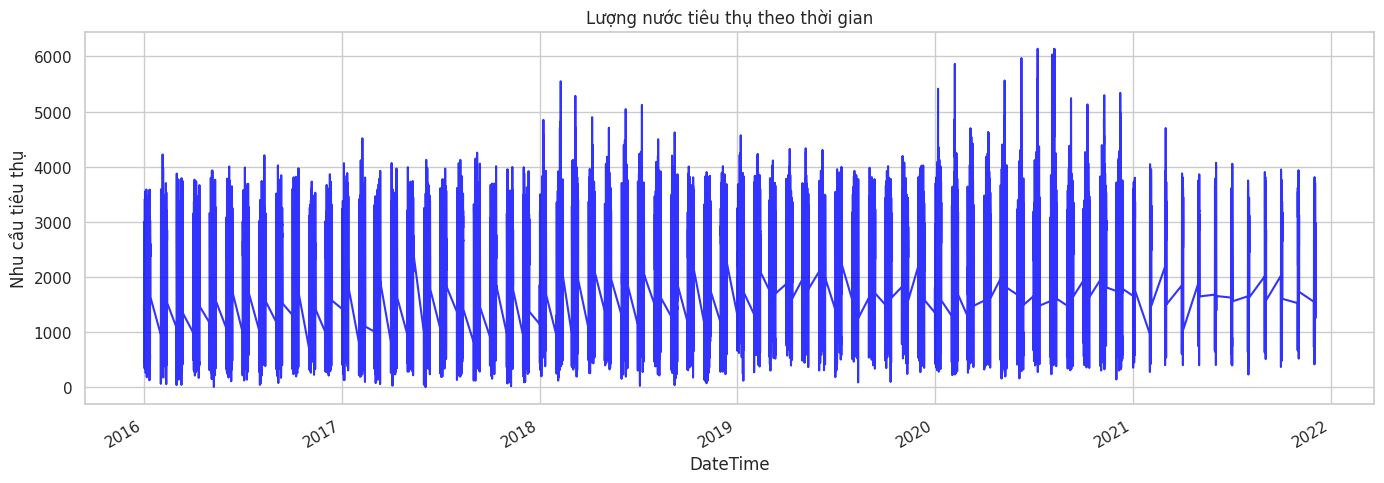

In [8]:
# 1. Biểu đồ dòng thời gian
fig1, ax1 = plt.subplots(figsize=(14, 5))
y.plot(ax=ax1, color='blue', alpha=0.8)
ax1.set_title("Lượng nước tiêu thụ theo thời gian")
ax1.set_ylabel("Nhu cầu tiêu thụ")
plt.tight_layout()
plt.show()
plt.close(fig1)

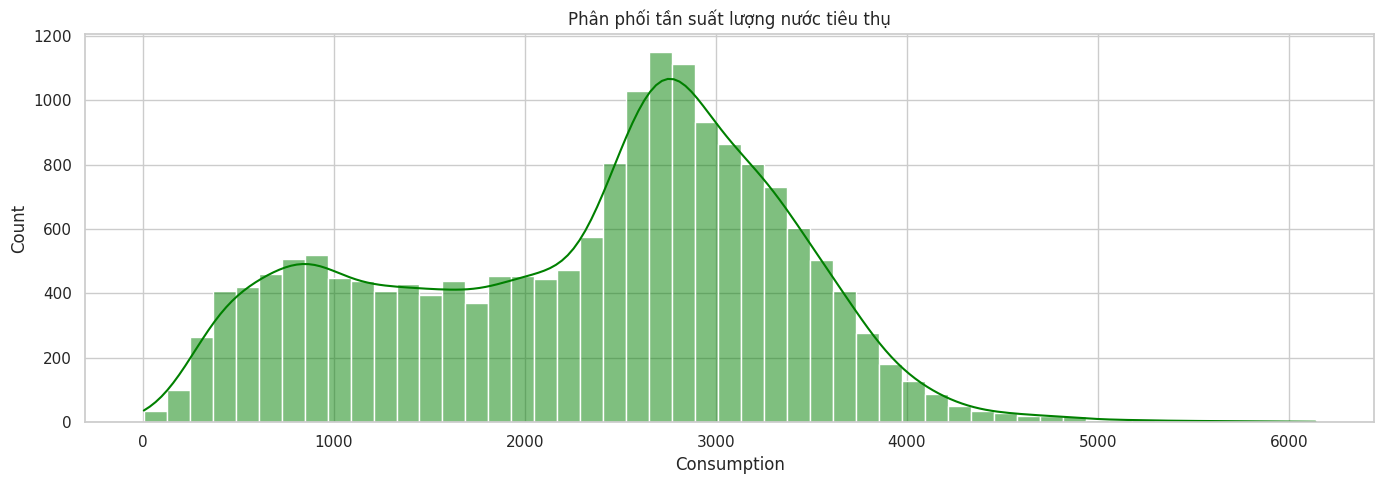

In [9]:
# 2. Histogram phân phối
fig2, ax2 = plt.subplots(figsize=(14, 5))
sns.histplot(y, kde=True, ax=ax2, color='green')
ax2.set_title("Phân phối tần suất lượng nước tiêu thụ")
plt.tight_layout()
plt.show()
plt.close(fig2)

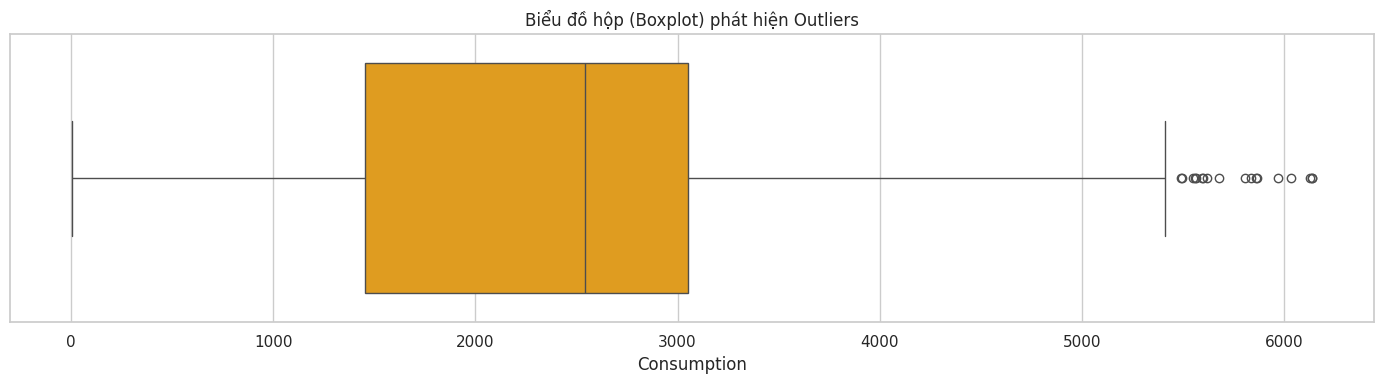

In [10]:
# 3. Boxplot phát hiện outliers
fig3, ax3 = plt.subplots(figsize=(14, 4))
sns.boxplot(x=y, ax=ax3, color='orange')
ax3.set_title("Biểu đồ hộp (Boxplot) phát hiện Outliers")
plt.tight_layout()
plt.show()
plt.close(fig3)

In [11]:
# Chuẩn bị dữ liệu phân tích hành vi tiêu thụ theo chu kỳ thời gian ngắn
_df_temp = pd.DataFrame({'Consumption': y})
_df_temp['Hour'] = _df_temp.index.hour
_df_temp['DayOfWeek'] = _df_temp.index.dayofweek

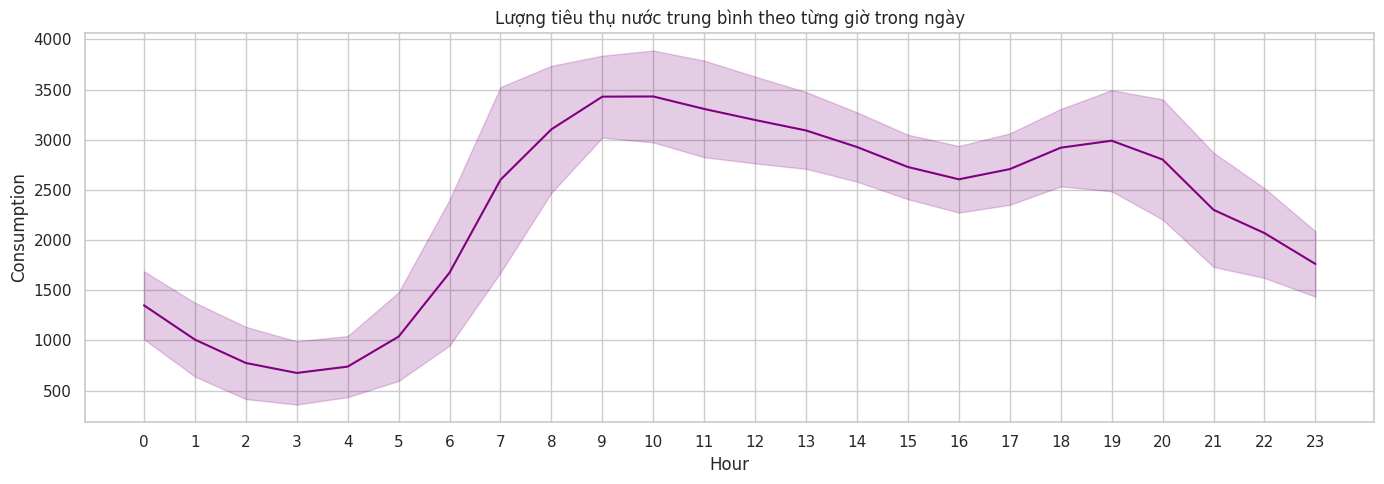

In [12]:
# 1. Lượng tiêu thụ trung bình theo từng giờ trong ngày
fig1, ax1 = plt.subplots(figsize=(14, 5))
sns.lineplot(data=_df_temp, x='Hour', y='Consumption', ax=ax1, errorbar='sd', color='purple')
ax1.set_title("Lượng tiêu thụ nước trung bình theo từng giờ trong ngày")
ax1.set_xticks(range(24))
plt.tight_layout()
plt.show()
plt.close(fig1)

### Nhận xét EDA:
- Biểu đồ thời gian giúp sơ bộ đánh giá tính xu hướng và tính mùa vụ (ví dụ: chu kỳ ngày đêm, chu kỳ tuần).
- Biểu đồ phân phối hỗ trợ đánh giá giả định chuẩn hóa và tìm kiếm các hành vi bất thường của chỉ số tiêu thụ.
- Phân tích theo giờ và thứ cho thấy rõ rệt lượng nước tiêu thụ thường đạt đỉnh vào các khung giờ sinh hoạt cố định và có sự dịch chuyển giữa ngày làm việc so với cuối tuần.

## PHẦN 4. TIỀN XỬ LÝ DỮ LIỆU

Bước này đảm bảo tính liên tục của chuỗi thời gian (tần suất theo giờ `'H'`), xử lý dữ liệu khuyết thiếu bằng phép nội suy tuyến tính tránh rò rỉ thông tin.

In [13]:
# Loại bỏ index trùng lặp nếu có
if y.index.duplicated().any():
    y = y[~y.index.duplicated(keep='first')]

# Thiết lập tần suất rõ ràng theo giờ (Hourly)
y = y.asfreq('H')

# Điền các giá trị thiếu bằng phương pháp nội suy tuyến tính (Linear Interpolation)
missing_after_freq = y.isnull().sum()
if missing_after_freq > 0:
    print(f"Phát hiện {missing_after_freq} khoảng trống thời gian. Đang thực hiện nội suy...")
    y = y.interpolate(method='linear')
else:
    print("Chuỗi thời gian hoàn toàn liên tục và không chứa giá trị thiếu.")

# Đảm bảo không còn giá trị NaN
assert y.isnull().sum() == 0, "Vẫn còn giá trị thiếu!"

Phát hiện 34058 khoảng trống thời gian. Đang thực hiện nội suy...


## PHẦN 5. KIỂM TRA TÍNH DỪNG (STATIONARITY)

Chúng ta dùng hai kiểm định phổ biến: Augmented Dickey-Fuller (ADF) và KPSS để xác định bậc sai phân $d$ cần thiết.

In [14]:
def check_stationarity(timeseries):
    # ADF Test
    adf_result = adfuller(timeseries.dropna())
    print('--- Kiểm định ADF ---')
    print(f'Giá trị thống kê ADF: {adf_result[0]:.4f}')
    print(f'p-value: {adf_result[1]:.4e}')
    print('Kết luận ADF:', 'Chuỗi dừng' if adf_result[1] < 0.05 else 'Chuỗi không dừng (Có gốc đơn vị)')

    # KPSS Test
    kpss_result = kpss(timeseries.dropna(), regression='c')
    print('\n--- Kiểm định KPSS ---')
    print(f'Giá trị thống kê KPSS: {kpss_result[0]:.4f}')
    print(f'p-value: {kpss_result[1]:.4f}')
    print('Kết luận KPSS:', 'Chuỗi dừng' if kpss_result[1] > 0.05 else 'Chuỗi không dừng')

print("Kiểm tra tính dừng của chuỗi dữ liệu gốc (d = 0):")
check_stationarity(y)

Kiểm tra tính dừng của chuỗi dữ liệu gốc (d = 0):
--- Kiểm định ADF ---
Giá trị thống kê ADF: -11.3176
p-value: 1.1958e-20
Kết luận ADF: Chuỗi dừng

--- Kiểm định KPSS ---
Giá trị thống kê KPSS: 3.3998
p-value: 0.0100
Kết luận KPSS: Chuỗi không dừng


Nếu chuỗi chưa dừng, chúng ta tiến hành lấy sai phân bậc 1 ($d=1$) và kiểm tra lại.

Kiểm tra tính dừng sau khi lấy sai phân bậc 1 (d = 1):
--- Kiểm định ADF ---
Giá trị thống kê ADF: -39.3293
p-value: 0.0000e+00
Kết luận ADF: Chuỗi dừng

--- Kiểm định KPSS ---
Giá trị thống kê KPSS: 0.0363
p-value: 0.1000
Kết luận KPSS: Chuỗi dừng


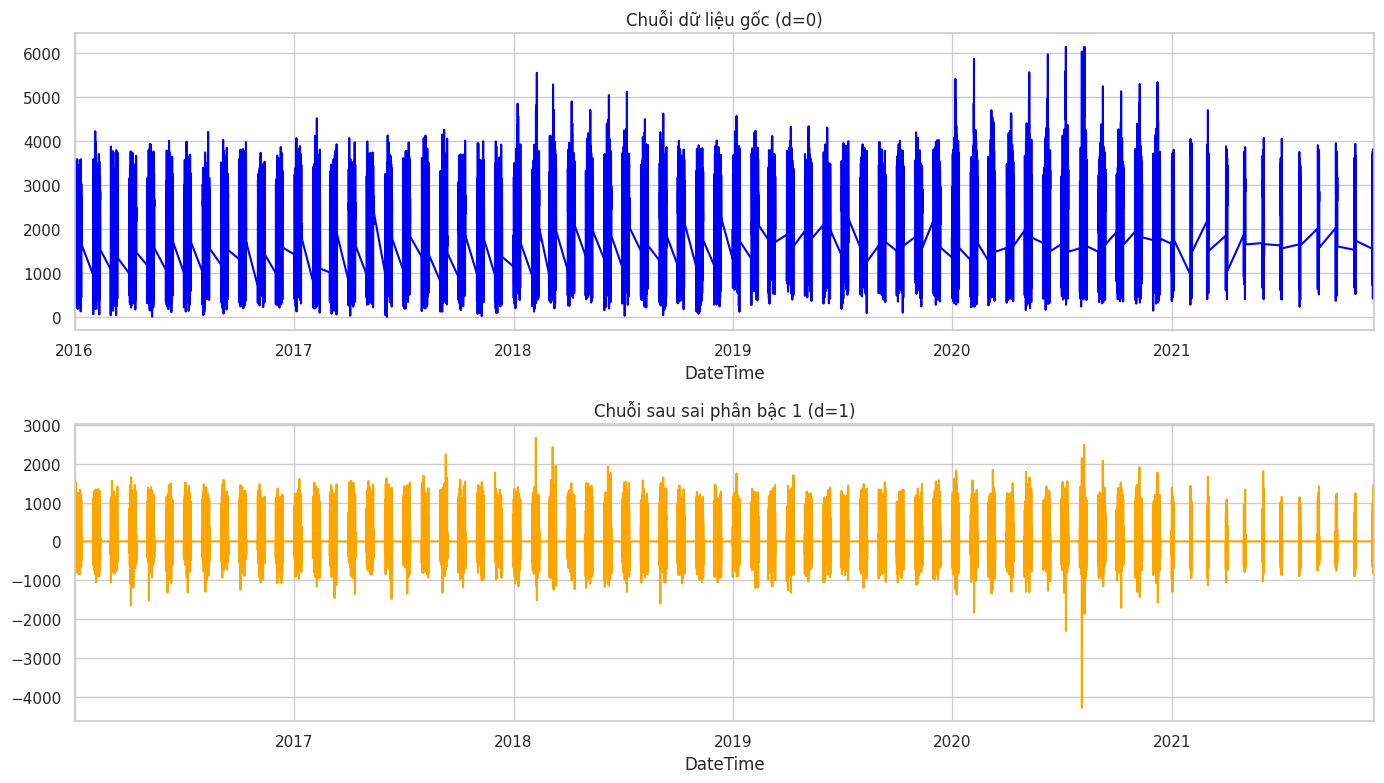

In [15]:
y_diff1 = y.diff().dropna()

print("Kiểm tra tính dừng sau khi lấy sai phân bậc 1 (d = 1):")
check_stationarity(y_diff1)

# Trực quan hóa so sánh
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
y.plot(ax=axes[0], title="Chuỗi dữ liệu gốc (d=0)", color='blue')
y_diff1.plot(ax=axes[1], title="Chuỗi sau sai phân bậc 1 (d=1)", color='orange')
plt.tight_layout()
plt.show()

## PHẦN 6. PHÂN TÍCH ACF VÀ PACF

Biểu đồ tự tương quan (ACF) và tự tương quan riêng phần (PACF) sẽ gợi ý cho ta các hệ số bậc tự hồi quy $p$ và trung bình trượt $q$ thích hợp.

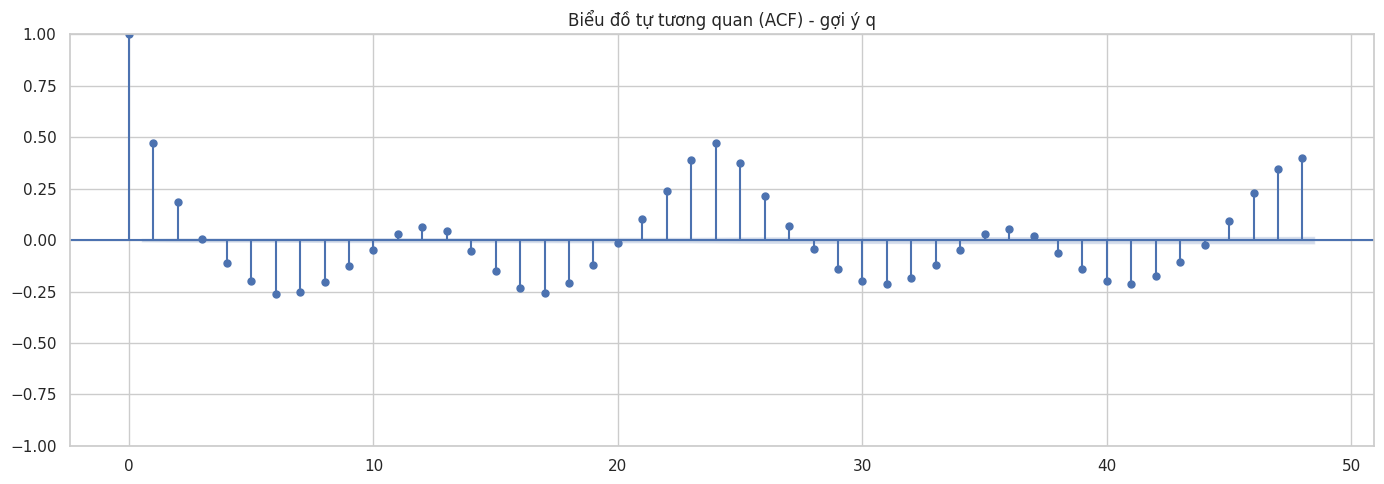

In [16]:
# 1. Biểu đồ tự tương quan (ACF) - gợi ý q
fig1, ax1 = plt.subplots(figsize=(14, 5))
plot_acf(y_diff1, lags=48, ax=ax1, title="Biểu đồ tự tương quan (ACF) - gợi ý q")
plt.tight_layout()
plt.show()
plt.close(fig1)

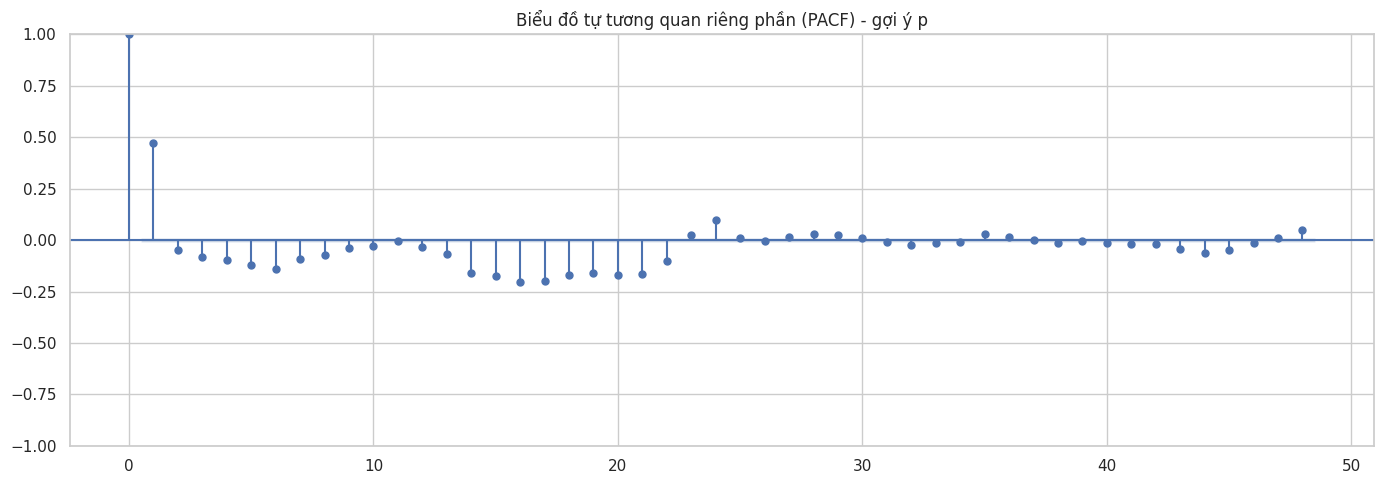

In [17]:
# 2. Biểu đồ tự tương quan riêng phần (PACF) - gợi ý p
fig2, ax2 = plt.subplots(figsize=(14, 5))
plot_pacf(y_diff1, lags=48, ax=ax2, method='yw', title="Biểu đồ tự tương quan riêng phần (PACF) - gợi ý p")
plt.tight_layout()
plt.show()
plt.close(fig2)

### Giải thích việc chọn tham số $p$, $d$, $q$ từ ACF và PACF

**Chọn $d = 1$.** Sau khi lấy sai phân bậc 1, ACF không còn suy giảm chậm kiểu gốc đơn vị. Hệ số tại lag 1 vẫn dương (~0.47), nên chuỗi không bị sai phân quá mức (sai phân quá mức thường cho lag 1 gần -0.5).

**Chọn $p$ dựa vào PACF.** PACF có một cột nổi bật duy nhất tại lag 1 (~0.47), rồi giảm đột ngột về gần 0 từ lag 2 (~-0.05). Đây là dấu hiệu "cắt cụt" sau lag 1, gợi ý thành phần tự hồi quy bậc thấp, $p = 1$. Ta thử thêm $p = 2$ để kiểm tra mô hình có cải thiện hay không.

**Chọn $q$ dựa vào ACF.** ACF giảm nhanh từ lag 1 (~0.47) xuống lag 2 (~0.19) rồi gần 0 tại lag 3 (~0.01). Do đó phần trung bình trượt chỉ cần bậc thấp, $q \in \{1, 2\}$. ACF không cắt cụt hoàn toàn mà suy giảm dần (0.47 → 0.19 → 0.01), nên đây là dạng ARMA hỗn hợp chứ không phải AR hoặc MA thuần.

**Vì sao không chọn $p$, $q$ lớn hơn?** Dải tin cậy 95% rất hẹp (do chuỗi dài), nên gần như lag nào cũng "vượt ngưỡng". Vì vậy ta ưu tiên độ lớn của hệ số và dạng cắt cụt/suy giảm, rồi để Grid Search với $p, q \in \{1, 2\}$ quyết định dựa trên AIC/BIC và sai số trên tập Validation.

Dựa trên các vệt vượt ngưỡng giới hạn tin cậy (vùng màu xanh), ta có thể khoanh vùng cấu hình thử nghiệm tiềm năng cho $p$ và $q$ (ví dụ: $p \in [1, 3]$ và $q \in [1, 3]$).

## PHẦN 7. CHIA TẬP DỮ LIỆU

Chúng ta tiến hành phân chia tập dữ liệu tuần tự theo thời gian nhằm tránh rò rỉ dữ liệu từ tương lai: 70% Train, 15% Validation, 15% Test.

In [18]:
n = len(y)
train_size = int(n * 0.70)
val_size = int(n * 0.15)
test_size = n - train_size - val_size

train_data = y.iloc[:train_size]
val_data = y.iloc[train_size:train_size + val_size]
test_data = y.iloc[train_size + val_size:]

print(f"Tổng số mẫu: {n}")
print(f"Tập Huấn luyện (Train): {len(train_data)} mẫu (từ {train_data.index.min()} đến {train_data.index.max()})")
print(f"Tập Đánh giá (Val): {len(val_data)} mẫu (từ {val_data.index.min()} đến {val_data.index.max()})")
print(f"Tập Kiểm thử (Test): {len(test_data)} mẫu (từ {test_data.index.min()} đến {test_data.index.max()})")

Tổng số mẫu: 51936
Tập Huấn luyện (Train): 36355 mẫu (từ 2016-01-01 00:00:00 đến 2020-02-23 18:00:00)
Tập Đánh giá (Val): 7790 mẫu (từ 2020-02-23 19:00:00 đến 2021-01-13 08:00:00)
Tập Kiểm thử (Test): 7791 mẫu (từ 2021-01-13 09:00:00 đến 2021-12-03 23:00:00)


## PHẦN 8. LỰA CHỌN THAM SỐ ARIMA (GRID SEARCH)

Chúng ta sẽ thử nghiệm các tổ hợp tham số $(p, d, q)$ khác nhau để tìm cấu hình có hiệu suất tối ưu trên cả chỉ số thông tin AIC/BIC và sai số dự báo thực tế trên tập Validation.

In [19]:
# Định nghĩa không gian tìm kiếm gọn nhẹ tránh quá tải bộ nhớ
p_values = [1, 2]
d_values = [1]
q_values = [1, 2]

grid_results = []

print("Bắt đầu Grid Search tìm kiếm tham số tối ưu...")
for p in p_values:
    for d in d_values:
        for q in q_values:
            try:
                # Huấn luyện trên tập Train
                model = ARIMA(train_data, order=(p, d, q))
                model_fit = model.fit()

                # Dự báo trên tập Validation (N-bước tĩnh để đánh giá nhanh)
                forecast_val = model_fit.forecast(steps=len(val_data))

                # Tính toán các chỉ số
                mae = mean_absolute_error(val_data, forecast_val)
                rmse = np.sqrt(mean_squared_error(val_data, forecast_val))

                grid_results.append({
                    'Model': f'ARIMA({p},{d},{q})',
                    'p': p, 'd': d, 'q': q,
                    'AIC': model_fit.aic,
                    'BIC': model_fit.bic,
                    'MAE_Val': mae,
                    'RMSE_Val': rmse
                })
                print(f"Thử nghiệm thành công: ARIMA({p},{d},{q}) -> Val MAE: {mae:.2f}")
            except Exception as e:
                continue

# Đưa kết quả vào DataFrame để so sánh
df_results = pd.DataFrame(grid_results)
display(df_results.sort_values(by='MAE_Val'))

Bắt đầu Grid Search tìm kiếm tham số tối ưu...
Thử nghiệm thành công: ARIMA(1,1,1) -> Val MAE: 643.33
Thử nghiệm thành công: ARIMA(1,1,2) -> Val MAE: 643.24
Thử nghiệm thành công: ARIMA(2,1,1) -> Val MAE: 609.42
Thử nghiệm thành công: ARIMA(2,1,2) -> Val MAE: 616.58


,Model,p,d,q,AIC,BIC,MAE_Val,RMSE_Val
2,"ARIMA(2,1,1)",2,1,1,498131.266471,498165.270709,609.418271,962.297114
3,"ARIMA(2,1,2)",2,1,2,497642.048531,497684.553828,616.579049,967.182704
1,"ARIMA(1,1,2)",1,1,2,502837.952702,502871.956940,643.241376,985.832498
0,"ARIMA(1,1,1)",1,1,1,502968.103606,502993.606784,643.325408,985.892296


In [20]:
# Tự động chọn cấu hình có MAE tốt nhất trên tập Validation
best_config = df_results.sort_values(by='MAE_Val').iloc[0]
best_p, best_d, best_q = int(best_config['p']), int(best_config['d']), int(best_config['q'])
print(f"Cấu hình ARIMA tối ưu được chọn: ({best_p}, {best_d}, {best_q})")

Cấu hình ARIMA tối ưu được chọn: (2, 1, 1)


## PHẦN 9. HUẤN LUYỆN MÔ HÌNH ARIMA

Huấn luyện mô hình tối ưu được tìm thấy từ bước trước trên tập dữ liệu Train.

In [21]:
best_model = ARIMA(train_data, order=(best_p, best_d, best_q))
best_model_fit = best_model.fit()

print(best_model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:            Consumption   No. Observations:                36355
Model:                 ARIMA(2, 1, 1)   Log Likelihood             -249061.633
Date:                Fri, 13 Nov 2026   AIC                         498131.266
Time:                        00:32:13   BIC                         498165.271
Sample:                    01-01-2016   HQIC                        498142.078
                         - 02-23-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.4157      0.002    607.861      0.000       1.411       1.420
ar.L2         -0.5639      0.002   -256.658      0.000      -0.568      -0.560
ma.L1         -0.9780      0.001  -1039.776      0.0

## PHẦN 10. KIỂM TRẠ PHẦN DƯ (RESIDUAL DIAGNOSTICS)

Chúng ta tiến hành phân tích tính ngẫu nhiên của sai số để đảm bảo mô hình đã khai thác hết thông tin hữu ích trong chuỗi (tiệm cận nhiễu trắng).

In [22]:
# Lấy phần dư của mô hình tốt nhất
residuals = best_model_fit.resid

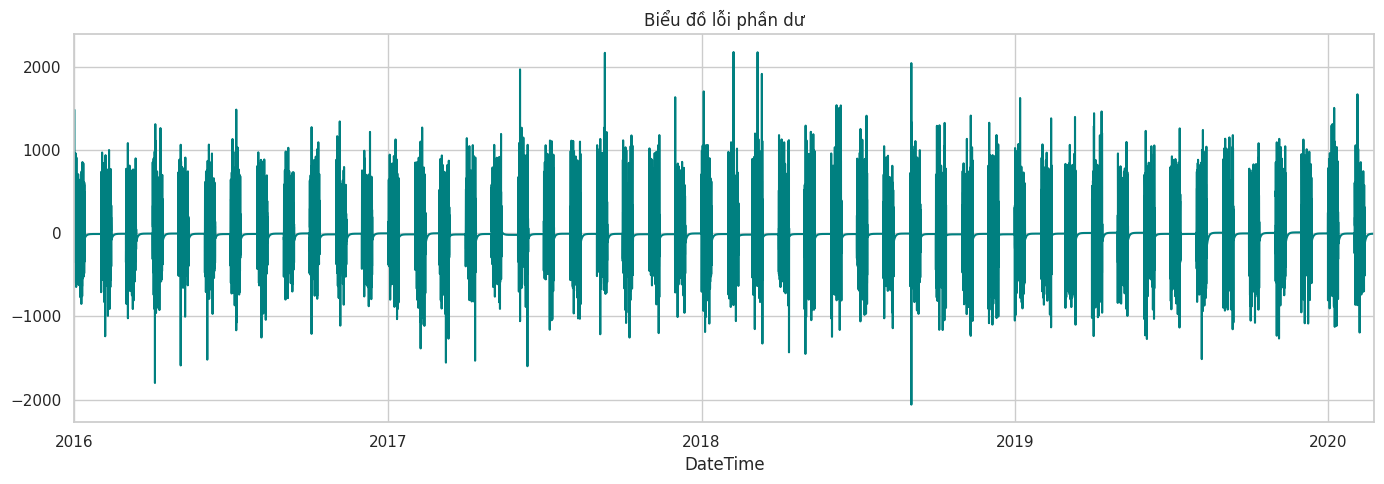

In [23]:
# 1. Biểu đồ lỗi phần dư
fig1, ax1 = plt.subplots(figsize=(14, 5))
residuals.plot(ax=ax1, color='teal')
ax1.set_title("Biểu đồ lỗi phần dư")
plt.tight_layout()
plt.show()
plt.close(fig1)

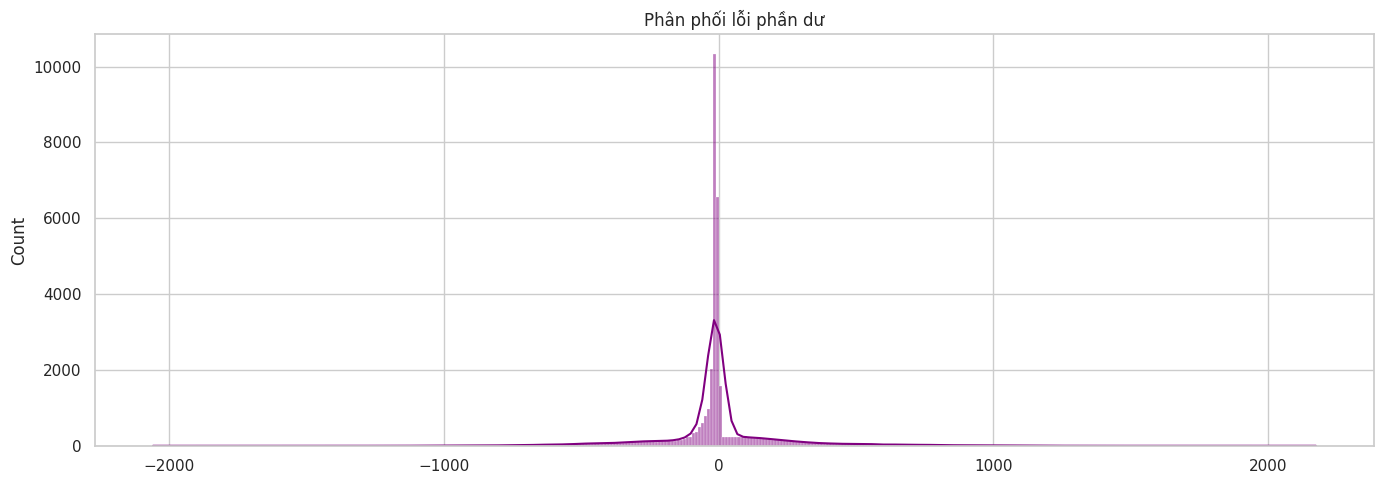

In [24]:
# 2. Histogram mật độ phần dư
fig2, ax2 = plt.subplots(figsize=(14, 5))
sns.histplot(residuals, kde=True, ax=ax2, color='purple')
ax2.set_title("Phân phối lỗi phần dư")
plt.tight_layout()
plt.show()
plt.close(fig2)

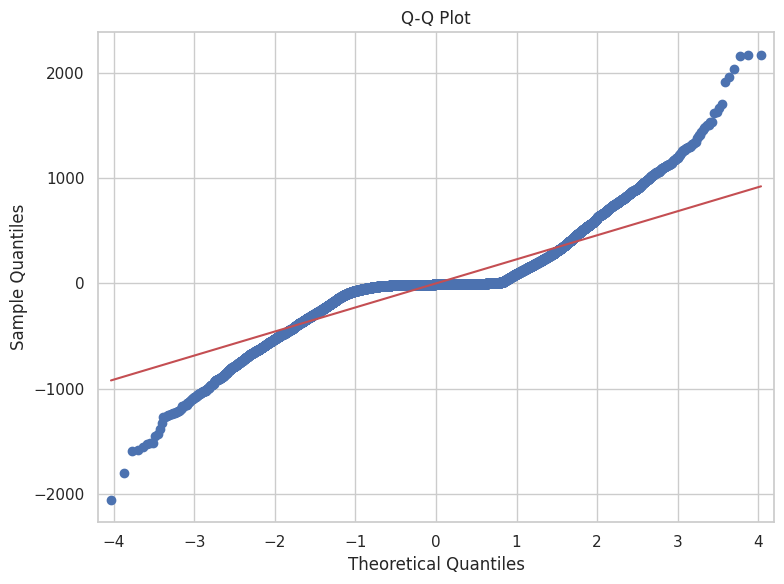

In [25]:
# 3. Q-Q Plot
fig3, ax3 = plt.subplots(figsize=(8, 6))
sm.qqplot(residuals, line='s', ax=ax3)
ax3.set_title("Q-Q Plot")
plt.tight_layout()
plt.show()
plt.close(fig3)

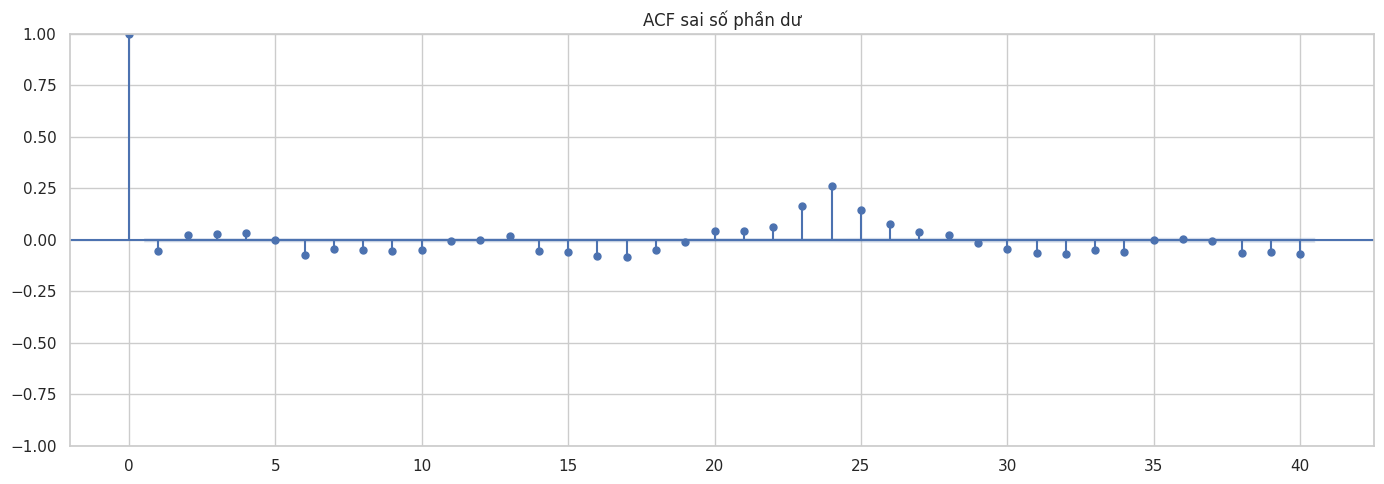

In [26]:
# 4. ACF phần dư
fig4, ax4 = plt.subplots(figsize=(14, 5))
plot_acf(residuals, lags=40, ax=ax4)
ax4.set_title("ACF sai số phần dư")
plt.tight_layout()
plt.show()
plt.close(fig4)

In [27]:
# Kiểm định Ljung-Box kiểm tra tự tương quan
ljung_box_results = acorr_ljungbox(residuals, lags=[10], return_df=True)
print("Kết quả kiểm định Ljung-Box trên phần dư:")
display(ljung_box_results)

Kết quả kiểm định Ljung-Box trên phần dư:


,lb_stat,lb_pvalue
10,759.385074,1.105937e-156


## PHẦN 11. DỰ BÁO CUỐN CHIẾU (ROLLING FORECAST)

Để đảm bảo tính thực tiễn cao, ta áp dụng phương pháp rolling one-step-ahead dự báo cuốn chiếu 1 bước trước trên toàn bộ tập Kiểm thử (Test).

In [28]:
import gc
import numpy as np

def _slice(obj, a, b):
    """Cắt [a:b] nhưng giữ nguyên kiểu dữ liệu (pandas giữ index/freq, numpy giữ mảng)."""
    return obj.iloc[a:b] if hasattr(obj, "iloc") else obj[a:b]

def rolling_one_step_forecast(fit_res, endog_new, exog_new=None, chunk_size=500, alpha=0.05):
    """
    Dự báo cuốn chiếu 1 bước (tham số cố định, không fit lại) theo từng KHỐI thay vì từng điểm.

    Với mỗi khối `chunk_size` điểm: extend() một lần, rồi lấy dự báo 1-bước (dynamic=False)
    của cả khối. Kết quả giống hệt vòng lặp extend từng điểm, nhưng:
      - chỉ gọi extend ~ n/chunk_size lần (thay vì n lần),
      - mỗi lần chỉ giữ state-space của đúng 1 khối nên RAM bị chặn trên (~ chunk_size x k_states^2),
      - gc.collect() sau mỗi khối để dọn các kết quả cũ (statsmodels có nhiều tham chiếu vòng).
    Trả về (predictions, lower_ci, upper_ci) dạng numpy.
    """
    n = len(endog_new)
    preds = np.empty(n); lower = np.empty(n); upper = np.empty(n)
    res = fit_res
    for s in range(0, n, chunk_size):
        e = min(s + chunk_size, n)
        kw = {} if exog_new is None else {"exog": _slice(exog_new, s, e)}
        new_res = res.extend(_slice(endog_new, s, e), **kw)
        pred = new_res.get_prediction(dynamic=False)          # dự báo 1-bước cho cả khối
        preds[s:e] = np.asarray(pred.predicted_mean)
        ci = np.asarray(pred.conf_int(alpha=alpha))
        lower[s:e], upper[s:e] = ci[:, 0], ci[:, 1]
        res = new_res                                         # trạng thái cuối khối -> khối kế tiếp
        del pred, ci, new_res
        gc.collect()
    del res
    gc.collect()
    return preds, lower, upper

print("Đã định nghĩa rolling_one_step_forecast (dự báo cuốn chiếu theo khối, tiết kiệm RAM).")


Đã định nghĩa rolling_one_step_forecast (dự báo cuốn chiếu theo khối, tiết kiệm RAM).


In [29]:
import gc
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

# Lịch sử ban đầu = Train + Val (dạng numpy, nhẹ hơn list Python)
initial_history = np.concatenate([train_data.values, val_data.values])
test_values = test_data.values

print("Đang dự báo cuốn chiếu (theo khối) trên tập Test cho ARIMA...")

# Huấn luyện mô hình cơ sở một lần duy nhất
base_fit = ARIMA(initial_history, order=(best_p, best_d, best_q)).fit()

predictions, ci_low, ci_up = rolling_one_step_forecast(base_fit, test_values, chunk_size=500)

# (Tuỳ chọn) kiểm tra: kết quả theo khối phải trùng với chạy từng điểm (chunk_size=1) trên 48 điểm đầu
VERIFY = False
if VERIFY:
    p_ref, _, _ = rolling_one_step_forecast(base_fit, test_values[:48], chunk_size=1)
    print("Khớp với chạy từng điểm:", np.allclose(p_ref, predictions[:48], rtol=1e-6, atol=1e-6))

predictions_series = pd.Series(predictions, index=test_data.index)
ci_df = pd.DataFrame({'lower_bound': ci_low, 'upper_bound': ci_up}, index=test_data.index)

del base_fit, initial_history
gc.collect()
print("Đã hoàn thành dự báo cuốn chiếu cho toàn bộ tập Test!")


Đang dự báo cuốn chiếu (theo khối) trên tập Test cho ARIMA...
Đã hoàn thành dự báo cuốn chiếu cho toàn bộ tập Test!


## PHẦN 12. ĐÁNH GIÁ MÔ HÌNH

Đánh giá chất lượng mô hình dự báo thông qua các chỉ số MAE, MSE, RMSE, MAPE.

In [30]:
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Tránh chia cho 0 hoặc giá trị cực nhỏ
    safe_mask = y_true != 0
    return np.mean(np.abs((y_true[safe_mask] - y_pred[safe_mask]) / y_true[safe_mask])) * 100

mae = mean_absolute_error(test_data, predictions_series)
mse = mean_squared_error(test_data, predictions_series)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(test_data, predictions_series)

metrics_df = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'MAPE (%)'],
    'Value': [mae, mse, rmse, mape]
})

print("Bảng kết quả đánh giá mô hình ARIMA trên tập Test:")
display(metrics_df)

Bảng kết quả đánh giá mô hình ARIMA trên tập Test:


,Metric,Value
0,MAE,40.398975
1,MSE,18294.450428
2,RMSE,135.256979
3,MAPE (%),2.472729


## PHẦN 13. TRỰC QUAN HÓA KẾT QUẢ DỰ BÁO

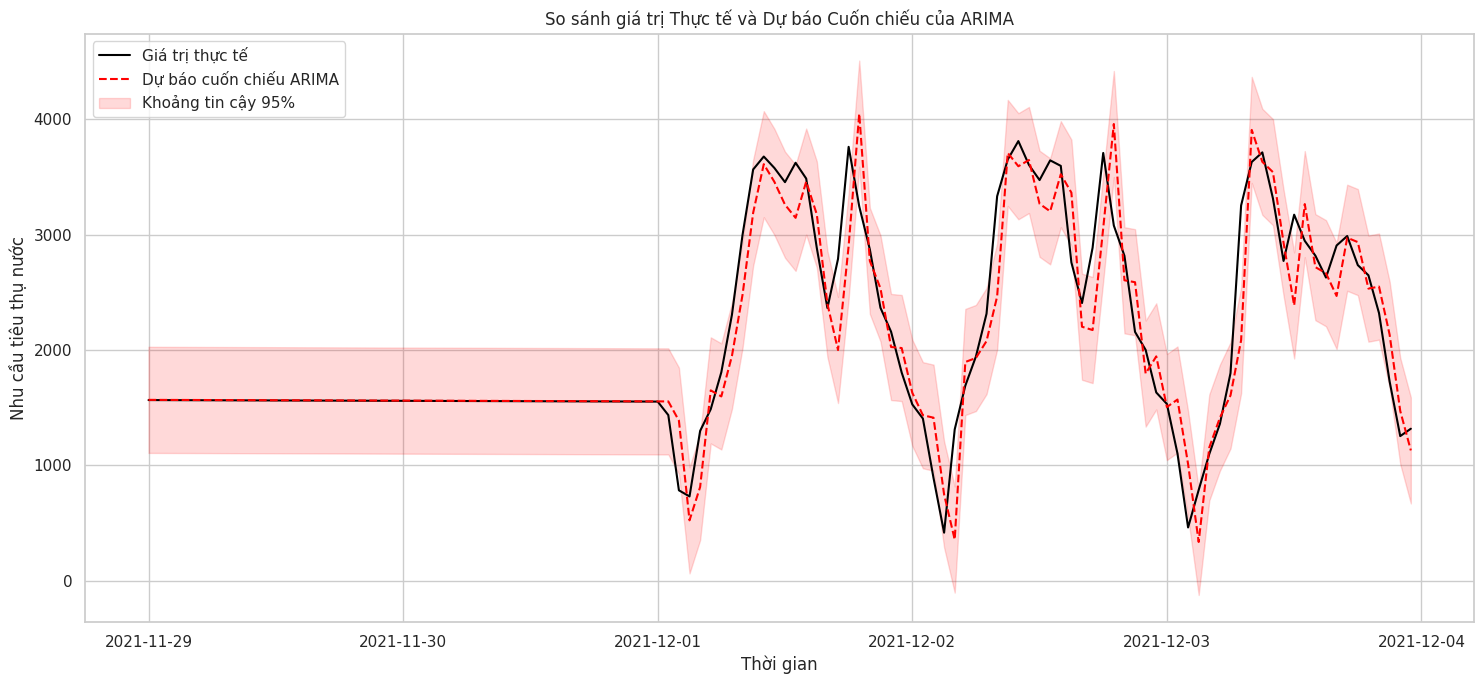

In [31]:
fig, ax = plt.subplots(figsize=(15, 7))

# Chỉ vẽ một phần đuôi của tập Test để biểu đồ trực quan, dễ theo dõi chi tiết
plot_range = test_data.index[-120:] # Vẽ 120 giờ cuối cùng

ax.plot(test_data.loc[plot_range], label='Giá trị thực tế', color='black', linewidth=1.5)
ax.plot(predictions_series.loc[plot_range], label='Dự báo cuốn chiếu ARIMA', color='red', linestyle='--')
ax.fill_between(plot_range,
                ci_df.loc[plot_range, 'lower_bound'],
                ci_df.loc[plot_range, 'upper_bound'],
                color='red', alpha=0.15, label='Khoảng tin cậy 95%')

ax.set_title("So sánh giá trị Thực tế và Dự báo Cuốn chiếu của ARIMA")
ax.set_xlabel("Thời gian")
ax.set_ylabel("Nhu cầu tiêu thụ nước")
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## PHẦN 14. LƯU KẾT QUẢ VÀ TẢI VỀ

Chúng ta thiết lập cây thư mục kết quả nghiên cứu, xuất các file CSV thống kê cùng đồ thị và nén tệp zip để tải về.

In [32]:
output_dir = 'ARIMA_Water_Forecasting'
os.makedirs(output_dir, exist_ok=True)

# 1. Lưu các file csv
y.to_csv(f"{output_dir}/cleaned_data.csv")
train_data.to_csv(f"{output_dir}/training_data.csv")
val_data.to_csv(f"{output_dir}/validation_data.csv")
test_data.to_csv(f"{output_dir}/testing_data.csv")

forecast_results = pd.DataFrame({
    'Actual': test_data,
    'Predicted': predictions_series,
    'Lower_CI': ci_df['lower_bound'],
    'Upper_CI': ci_df['upper_bound']
})
forecast_results.to_csv(f"{output_dir}/forecast_results.csv")
metrics_df.to_csv(f"{output_dir}/evaluation_metrics.csv", index=False)

# 2. Lưu thông tin tóm tắt mô hình
with open(f"{output_dir}/model_summary.txt", "w", encoding="utf-8") as f:
    f.write(best_model_fit.summary().as_text())

# 3. Lưu mô hình bằng pickle
with open(f"{output_dir}/best_model.pkl", "wb") as f:
    pickle.dump({
        'p': best_p, 'd': best_d, 'q': best_q,
        'params': best_model_fit.params,
        'model_class': 'statsmodels.tsa.arima.model.ARIMA'
    }, f)

# 4. Lưu biểu đồ
fig.savefig(f"{output_dir}/forecast_vs_actual.png", dpi=300)

# Nén thư mục
shutil.make_archive(output_dir, 'zip', output_dir)
print(f"Đã tạo thành công tệp nén: {output_dir}.zip")

Đã tạo thành công tệp nén: ARIMA_Water_Forecasting.zip


In [33]:
# Hỗ trợ tải trực tiếp tệp ZIP về máy khách
files.download(f"{output_dir}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# GIAI ĐOẠN 2: MỞ RỘNG NGHIÊN CỨU VỚI CÁC MÔ HÌNH NÂNG CAO (SARIMA, ARIMAX, SARIMAX)

Trong giai đoạn này, chúng ta sẽ mở rộng mô hình nền tảng ARIMA cổ điển bằng cách tích hợp thêm hai yếu tố cực kỳ quan trọng đối với chuỗi thời gian tiêu thụ nước:
1. **Yếu tố mùa vụ (Seasonal Component)** thông qua mô hình **SARIMA**.
2. **Các biến ngoại sinh thời tiết (Exogenous Variables)** bao gồm Nhiệt độ (`Temperature`), Lượng mưa (`Rain`), và Cường độ ánh nắng (`Sun`) thông qua mô hình **ARIMAX**.
3. **Sự kết hợp đồng thời cả hai yếu tố trên** thông qua mô hình toàn diện **SARIMAX**.

Sau cùng, chúng ta sẽ thực hiện một thực nghiệm đối sánh công bằng để đánh giá hiệu suất dự báo của cả 4 mô hình trên tập Kiểm thử (Test).

## PHẦN 15. TỔNG QUAN BA MÔ HÌNH MỚI VÀ CẤU TRÚC BIẾN NGOẠI SINH

Chúng ta định nghĩa rõ vai trò của các biến số trong tập dữ liệu:
*   **Biến mục tiêu (Target - $y$):** `Consumption` (Lượng nước tiêu thụ thực tế theo giờ).
*   **Các biến ngoại sinh (Exogenous - $X$):** `Temperature` (Nhiệt độ), `Rain` (Lượng mưa), `Sun` (Cường độ ánh nắng).

Phân biệt kiến trúc đầu vào của các mô hình:
1.  **ARIMA(p, d, q):** Chỉ sử dụng $y$ quá khứ, không có mùa vụ, không có biến ngoại sinh.
2.  **SARIMA(p, d, q)(P, D, Q, m):** Chỉ sử dụng $y$ quá khứ bổ sung thêm các thành phần tự hồi quy và trung bình trượt có tính chu kỳ mùa vụ $m$.
3.  **ARIMAX(p, d, q):** Sử dụng $y$ quá khứ và các biến ngoại sinh thời tiết hiện tại/tương lai gần $X$, không chứa thành phần mùa vụ.
4.  **SARIMAX(p, d, q)(P, D, Q, m):** Mô hình tối tân nhất tích hợp đồng thời cả biến ngoại sinh $X$ và chu kỳ mùa vụ $m$.

In [34]:
# Kiểm tra cấu trúc các biến ngoại sinh có sẵn trong DataFrame gốc
exog_cols = ['Temperature', 'Rain', 'Sun']
print("Kiểm tra các biến ngoại sinh thời tiết:")
display(df[exog_cols].head())

# Kiểm tra giá trị khuyết thiếu của các biến ngoại sinh
print("\nSố lượng giá trị khuyết thiếu trong các biến ngoại sinh:")
print(df[exog_cols].isnull().sum())

Kiểm tra các biến ngoại sinh thời tiết:


,Temperature,Rain,Sun
DateTime,,,
2016-01-01 00:00:00,0.6,0.0,0
2016-01-01 01:00:00,0.6,0.0,0
2016-01-01 02:00:00,0.5,0.0,0
2016-01-01 03:00:00,0.0,0.0,0
2016-01-01 04:00:00,0.3,0.0,0



Số lượng giá trị khuyết thiếu trong các biến ngoại sinh:
Temperature    0
Rain           1
Sun            0
dtype: int64


## PHẦN 16. TIỀN XỬ LÝ VÀ PHÂN CHIA BIẾN NGOẠI SINH (EXOGENOUS VARIABLES)

Chúng ta tiến hành nội suy giá trị khuyết thiếu của các biến thời tiết và thực hiện phân tách tập dữ liệu ngoại sinh đồng bộ hoàn toàn với các mốc thời gian của tập Train, Val, và Test đã chia.

In [35]:
# 1. Tạo DataFrame chứa các biến ngoại sinh đầy đủ từ df gốc theo tần suất giờ
X = df[exog_cols].copy()
X = X.asfreq('H')

# 2. Xử lý giá trị khuyết thiếu bằng nội suy tuyến tính (giống như đã làm với y)
if X.isnull().sum().sum() > 0:
    print("Phát hiện giá trị khuyết thiếu trong biến ngoại sinh. Đang tiến hành nội suy...")
    X = X.interpolate(method='linear')
    # Điền các giá trị khuyết thiếu ở biên (nếu có) bằng ffill và bfill
    X = X.ffill().bfill()

# Kiểm tra lại đảm bảo không còn giá trị NaN
assert X.isnull().sum().sum() == 0, "Vẫn còn giá trị thiếu trong các biến ngoại sinh!"

# 3. Phân chia các biến ngoại sinh đồng nhất với chỉ mục thời gian của y
X_train = X.loc[train_data.index]
X_val = X.loc[val_data.index]
X_test = X.loc[test_data.index]

print(f"X_train shape: {X_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"X_test shape: {X_test.shape}")
print("Đã xử lý khuyết thiếu và phân chia các biến ngoại sinh thành công!")

Phát hiện giá trị khuyết thiếu trong biến ngoại sinh. Đang tiến hành nội suy...
X_train shape: (36355, 3)
X_val shape: (7790, 3)
X_test shape: (7791, 3)
Đã xử lý khuyết thiếu và phân chia các biến ngoại sinh thành công!


## PHẦN 17. PHÂN TÍCH CHU KỲ MÙA VỤ ĐỂ XÁC ĐỊNH THAM SỐ $m$

Chúng ta vẽ biểu đồ ACF của chuỗi dữ liệu sai phân bậc 1 với số lượng bước trễ (lags) lớn lên tới 168 giờ (tương đương 1 tuần) để quan sát rõ nét chu kỳ lặp lại thống kê.

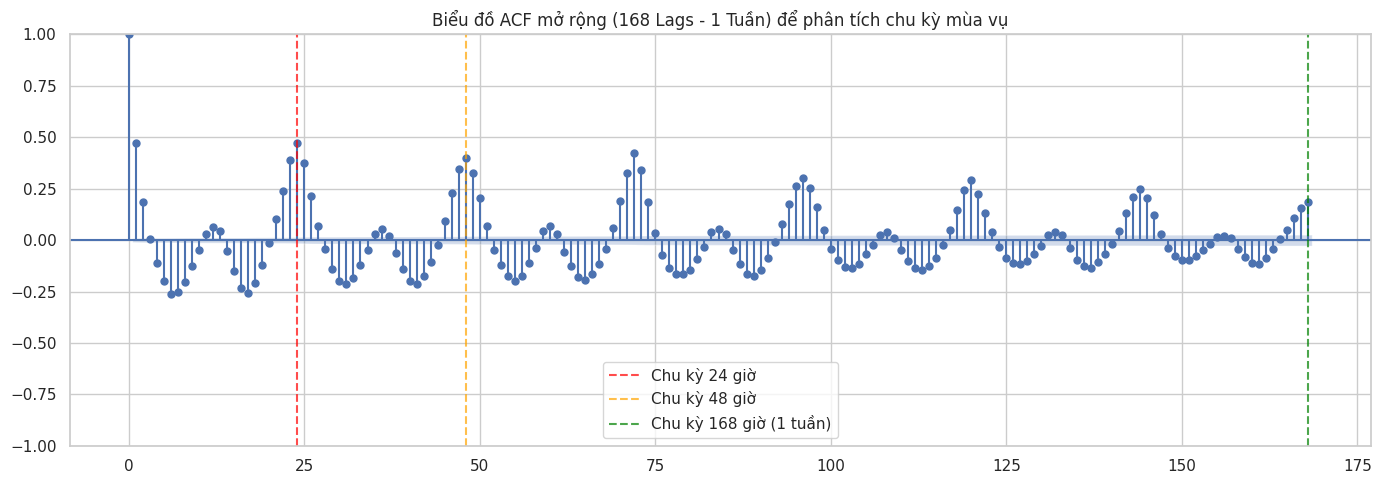

In [36]:
# Vẽ biểu đồ tự tương quan ACF với lags=168 để phân tích tính mùa vụ chu kỳ ngày (24h) và tuần (168h)
fig, ax = plt.subplots(figsize=(14, 5))
plot_acf(y_diff1, lags=168, ax=ax, title="Biểu đồ ACF mở rộng (168 Lags - 1 Tuần) để phân tích chu kỳ mùa vụ")
plt.axvline(x=24, color='red', linestyle='--', alpha=0.7, label='Chu kỳ 24 giờ')
plt.axvline(x=48, color='orange', linestyle='--', alpha=0.7, label='Chu kỳ 48 giờ')
plt.axvline(x=168, color='green', linestyle='--', alpha=0.7, label='Chu kỳ 168 giờ (1 tuần)')
plt.legend()
plt.tight_layout()
plt.show()


**Dấu hiệu mùa vụ ($m = 24$).** ACF có đỉnh rõ tại lag 24 (~0.47) và lag 48 (~0.40), kèm các vùng âm quanh lag 6-7 và 16-17. Đây là chu kỳ ngày-đêm, mà ARIMA bậc thấp không mô tả được. Đây là lý do ở Giai đoạn 2 ta thêm thành phần mùa vụ $(P, D, Q, m) = (1, 0, 1, 24)$ cho SARIMA/SARIMAX. PACF chỉ có một gai nhỏ tại lag 24, ACF có đỉnh lớn và rộng, nên kết hợp cả AR mùa vụ và MA mùa vụ bậc 1 là hợp lý.

## PHẦN 18. XÂY DỰNG VÀ HUẤN LUYỆN MÔ HÌNH SARIMA

Chúng ta thiết lập mô hình SARIMA tích hợp thành phần mùa vụ với chu kỳ ngày $m=24$. Để tránh thời gian huấn luyện quá lâu, chúng ta sẽ huấn luyện cấu hình tối ưu trực tiếp dựa trên cấu hình cơ sở ARIMA kết hợp với tham số mùa vụ thực nghiệm.

In [37]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

print("Đang huấn luyện mô hình SARIMA(2, 1, 1) x (1, 0, 1, 24) trên tập Train...")
# Sử dụng SARIMAX với cấu hình mùa vụ nhưng chưa có ngoại sinh (chính là SARIMA)
sarima_model = SARIMAX(train_data,
                       order=(best_p, best_d, best_q),
                       seasonal_order=(1, 0, 1, 24),
                       enforce_stationarity=False,
                       enforce_invertibility=False)

sarima_fit = sarima_model.fit(disp=False)
print(sarima_fit.summary())

Đang huấn luyện mô hình SARIMA(2, 1, 1) x (1, 0, 1, 24) trên tập Train...
                                     SARIMAX Results                                      
Dep. Variable:                        Consumption   No. Observations:                36355
Model:             SARIMAX(2, 1, 1)x(1, 0, 1, 24)   Log Likelihood             -245839.143
Date:                            Fri, 13 Nov 2026   AIC                         491690.287
Time:                                    00:33:14   BIC                         491741.289
Sample:                                01-01-2016   HQIC                        491706.504
                                     - 02-23-2020                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.2117      0.003    469.

## PHẦN 19. DỰ BÁO CUỐN CHIẾU SIÊU TỐC VỚI MÔ HÌNH SARIMA

Chúng ta thực hiện chiến lược dự báo cuốn chiếu từng bước (rolling forecast) trên tập Kiểm thử (Test) đối với mô hình SARIMA bằng công cụ tối ưu hóa `extend` tích hợp sẵn trong statsmodels.

In [38]:
# 1. Dự báo cuốn chiếu cho SARIMA (theo khối)
import gc
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_initial_history = pd.concat([train_data, val_data])
sarima_initial_history.index.freq = 'h'
test_data.index.freq = 'h'

print("Đang tiến hành dự báo cuốn chiếu (theo khối) cho SARIMA...")
sarima_base_fit = SARIMAX(sarima_initial_history,
                          order=(best_p, best_d, best_q),
                          seasonal_order=(1, 0, 1, 24),
                          enforce_stationarity=False,
                          enforce_invertibility=False).fit(disp=False)

sarima_predictions, _, _ = rolling_one_step_forecast(sarima_base_fit, test_data, chunk_size=500)
sarima_predictions_series = pd.Series(sarima_predictions, index=test_data.index)

del sarima_base_fit
gc.collect()
print("Hoàn thành dự báo cuốn chiếu cho SARIMA!")


Đang tiến hành dự báo cuốn chiếu (theo khối) cho SARIMA...
Hoàn thành dự báo cuốn chiếu cho SARIMA!


## PHẦN 20. XÂY DỰNG VÀ DỰ BÁO CUỐN CHIẾU VỚI MÔ HÌNH ARIMAX

Mô hình ARIMAX kết hợp cấu hình ARIMA cơ sở (2,1,1) với 3 biến ngoại sinh thời tiết thực tế: `Temperature`, `Rain`, và `Sun`.

In [39]:
# 1. Huấn luyện mô hình ARIMAX(2, 1, 1) trên tập Train với X_train
print("Đang huấn luyện mô hình ARIMAX(2, 1, 1) trên tập Train...")
arimax_model = ARIMA(train_data, order=(best_p, best_d, best_q), exog=X_train)
arimax_fit = arimax_model.fit()
print(arimax_fit.summary())



Đang huấn luyện mô hình ARIMAX(2, 1, 1) trên tập Train...
                               SARIMAX Results                                
Dep. Variable:            Consumption   No. Observations:                36355
Model:                 ARIMA(2, 1, 1)   Log Likelihood             -248799.335
Date:                Fri, 13 Nov 2026   AIC                         497612.670
Time:                        00:35:03   BIC                         497672.177
Sample:                    01-01-2016   HQIC                        497631.590
                         - 02-23-2020                                         
Covariance Type:                  opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Temperature    23.5307      0.597     39.390      0.000      22.360      24.702
Rain            0.6623      2.390      0.277      0.782      -4.023   

In [40]:
# 2. Dự báo cuốn chiếu cho ARIMAX
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

# Khôi phục dữ liệu nếu chưa tồn tại trong bộ nhớ
if 'train_data' not in globals() or 'val_data' not in globals() or 'test_data' not in globals():
    print("Đang tái thiết lập dữ liệu và các biến ngoại sinh...")
    cleaned_df = pd.read_csv('ARIMA_Water_Forecasting/cleaned_data.csv', parse_dates=True, index_col='DateTime')
    y_series = cleaned_df['Consumption']
    df_raw = pd.read_csv('waterconsumption_rawdata.csv')
    start_time_raw = df_raw['Time'].str.split('-').str[0].str.strip()
    df_raw['DateTime'] = pd.to_datetime(df_raw['Date'] + ' ' + start_time_raw, format='%d/%m/%Y %H:%M', errors='coerce')
    df_raw = df_raw.dropna(subset=['DateTime']).sort_values(by='DateTime').set_index('DateTime')

    n_samples = len(y_series)
    tr_size = int(n_samples * 0.70)
    v_size = int(n_samples * 0.15)
    train_data = y_series.iloc[:tr_size]
    val_data = y_series.iloc[tr_size:tr_size + v_size]
    test_data = y_series.iloc[tr_size + v_size:]
    test_values = test_data.values

    exog_cols = ['Temperature', 'Rain', 'Sun']
    X_all = df_raw[exog_cols].copy().asfreq('h').interpolate(method='linear').ffill().bfill()
    X_train = X_all.loc[train_data.index]
    X_val = X_all.loc[val_data.index]
    X_test = X_all.loc[test_data.index]
    X_initial_history = pd.concat([X_train, X_val])
    best_p, best_d, best_q = 2, 1, 1

arimax_initial_history = pd.concat([train_data, val_data])
arimax_initial_history.index.freq = 'h'

X_initial_history = pd.concat([X_train, X_val])
X_initial_history.index.freq = 'h'

# Thiết lập tần suất cho test data
test_data.index.freq = 'h'
X_test.index.freq = 'h'

print("Đang tiến hành dự báo cuốn chiếu (theo khối) cho ARIMAX...")
arimax_base_fit = ARIMA(arimax_initial_history, order=(best_p, best_d, best_q), exog=X_initial_history).fit()

arimax_predictions, _, _ = rolling_one_step_forecast(arimax_base_fit, test_data, exog_new=X_test, chunk_size=500)
arimax_predictions_series = pd.Series(arimax_predictions, index=test_data.index)

import gc
del arimax_base_fit
gc.collect()
print("Hoàn thành dự báo cuốn chiếu cho ARIMAX!")


Đang tiến hành dự báo cuốn chiếu (theo khối) cho ARIMAX...
Hoàn thành dự báo cuốn chiếu cho ARIMAX!


## PHẦN 21. XÂY DỰNG VÀ DỰ BÁO CUỐN CHIẾU VỚI MÔ HÌNH TOÀN DIỆN SARIMAX

Mô hình SARIMAX kết hợp cấu hình ARIMA cơ sở (2,1,1), chu kỳ mùa vụ giờ thực tế $m=24$ và 3 biến ngoại sinh thời tiết: `Temperature`, `Rain`, và `Sun`.

In [41]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
import numpy as np

# Đảm bảo các biến cốt lõi được định nghĩa đầy đủ từ dữ liệu đã lưu trữ để tránh lỗi mất trạng thái
if 'y' not in globals() or 'df' not in globals():
    print("Đang khôi phục chuỗi thời gian y và DataFrame gốc...")
    cleaned_df = pd.read_csv('ARIMA_Water_Forecasting/cleaned_data.csv', parse_dates=True, index_col='DateTime')
    y = cleaned_df['Consumption']
    df = pd.read_csv('waterconsumption_rawdata.csv')
    start_time = df['Time'].str.split('-').str[0].str.strip()
    df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + start_time, format='%d/%m/%Y %H:%M', errors='coerce')
    df = df.dropna(subset=['DateTime']).sort_values(by='DateTime').set_index('DateTime')

n = len(y)
train_size = int(n * 0.70)
tval_size = int(n * 0.15)
train_data = y.iloc[:train_size]
val_data = y.iloc[train_size:train_size + tval_size]
test_data = y.iloc[train_size + tval_size:]
test_values = test_data.values
best_p, best_d, best_q = 2, 1, 1

# Định nghĩa và phân chia lại các biến ngoại sinh
exog_cols = ['Temperature', 'Rain', 'Sun']
X = df[exog_cols].copy().asfreq('H').interpolate(method='linear').ffill().bfill()
X_train = X.loc[train_data.index]
X_val = X.loc[val_data.index]
X_test = X.loc[test_data.index]
X_initial_history = pd.concat([X_train, X_val])

# 1. Huấn luyện mô hình toàn diện SARIMAX(2,1,1)x(1,0,1)_24 trên tập Train với X_train
print("Đang huấn luyện mô hình toàn diện SARIMAX(2, 1, 1) x (1, 0, 1, 24) trên tập Train...")
sarimax_model = SARIMAX(train_data,
                        order=(best_p, best_d, best_q),
                        seasonal_order=(1, 0, 1, 24),
                        exog=X_train,
                        enforce_stationarity=False,
                        enforce_invertibility=False)
sarimax_fit = sarimax_model.fit(disp=False)
print(sarimax_fit.summary())

Đang huấn luyện mô hình toàn diện SARIMAX(2, 1, 1) x (1, 0, 1, 24) trên tập Train...
                                     SARIMAX Results                                      
Dep. Variable:                        Consumption   No. Observations:                36355
Model:             SARIMAX(2, 1, 1)x(1, 0, 1, 24)   Log Likelihood             -245702.879
Date:                            Fri, 13 Nov 2026   AIC                         491423.757
Time:                                    00:39:09   BIC                         491500.260
Sample:                                01-01-2016   HQIC                        491448.083
                                     - 02-23-2020                                         
Covariance Type:                              opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Temperature    15.3796     

In [42]:
# 3. Dự báo cuốn chiếu cho SARIMAX
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Khôi phục dữ liệu nếu chưa tồn tại trong bộ nhớ
if 'train_data' not in globals() or 'val_data' not in globals() or 'test_data' not in globals():
    print("Đang tái thiết lập dữ liệu và các biến ngoại sinh...")
    cleaned_df = pd.read_csv('ARIMA_Water_Forecasting/cleaned_data.csv', parse_dates=True, index_col='DateTime')
    y_series = cleaned_df['Consumption']
    df_raw = pd.read_csv('waterconsumption_rawdata.csv')
    start_time_raw = df_raw['Time'].str.split('-').str[0].str.strip()
    df_raw['DateTime'] = pd.to_datetime(df_raw['Date'] + ' ' + start_time_raw, format='%d/%m/%Y %H:%M', errors='coerce')
    df_raw = df_raw.dropna(subset=['DateTime']).sort_values(by='DateTime').set_index('DateTime')

    n_samples = len(y_series)
    tr_size = int(n_samples * 0.70)
    v_size = int(n_samples * 0.15)
    train_data = y_series.iloc[:tr_size]
    val_data = y_series.iloc[tr_size:tr_size + v_size]
    test_data = y_series.iloc[tr_size + v_size:]
    test_values = test_data.values

    exog_cols = ['Temperature', 'Rain', 'Sun']
    X_all = df_raw[exog_cols].copy().asfreq('h').interpolate(method='linear').ffill().bfill()
    X_train = X_all.loc[train_data.index]
    X_val = X_all.loc[val_data.index]
    X_test = X_all.loc[test_data.index]
    X_initial_history = pd.concat([X_train, X_val])
    best_p, best_d, best_q = 2, 1, 1

sarimax_initial_history = pd.concat([train_data, val_data])
sarimax_initial_history.index.freq = 'h'

X_initial_history = pd.concat([X_train, X_val])
X_initial_history.index.freq = 'h'

# Thiết lập tần suất cho test data
test_data.index.freq = 'h'
X_test.index.freq = 'h'

print("Đang tiến hành dự báo cuốn chiếu (theo khối) cho SARIMAX...")
sarimax_base_fit = SARIMAX(sarimax_initial_history,
                           order=(best_p, best_d, best_q),
                           seasonal_order=(1, 0, 1, 24),
                           exog=X_initial_history,
                           enforce_stationarity=False,
                           enforce_invertibility=False).fit(disp=False)

sarimax_predictions, _, _ = rolling_one_step_forecast(sarimax_base_fit, test_data, exog_new=X_test, chunk_size=500)
sarimax_predictions_series = pd.Series(sarimax_predictions, index=test_data.index)

import gc
del sarimax_base_fit
gc.collect()
print("Hoàn thành dự báo cuốn chiếu cho SARIMAX!")


Đang tiến hành dự báo cuốn chiếu (theo khối) cho SARIMAX...
Hoàn thành dự báo cuốn chiếu cho SARIMAX!


### PHẦN 21B. GHI CHÚ TỐI ƯU HÓA BỘ NHỚ RAM KHI DỰ BÁO CUỐN CHIẾU

**Nguyên nhân tốn RAM:** vòng lặp cũ gọi `extend()` + `get_forecast()` cho *từng giờ* của tập Test. Mỗi lần tạo một đối tượng kết quả state-space mới (kèm bộ lọc/làm trơn Kalman, ma trận hiệp phương sai...), các đối tượng cũ lại có tham chiếu vòng nên không được thu hồi kịp → RAM tăng dần. Với mô hình mùa vụ `m=24` (SARIMA/SARIMAX) số trạng thái lớn nên càng nặng.

**Cách khắc phục:** hàm `rolling_one_step_forecast` chạy theo **khối** (`chunk_size=500`): mỗi khối chỉ `extend()` một lần rồi lấy dự báo 1-bước của cả khối, sau đó `gc.collect()`. Tham số mô hình vẫn cố định (không fit lại) nên kết quả tương đương cách cũ, nhưng số lần `extend()` giảm ~500 lần và RAM bị chặn trên theo kích thước khối. Nếu vẫn thiếu RAM, giảm `chunk_size` (ví dụ 168 hoặc 72).


## PHẦN 22. ĐÁNH GIÁ ĐỐI SÁNH HIỆU SUẤT CỦA 4 MÔ HÌNH

Chúng ta tiến hành tổng hợp các chỉ số sai số ($MAE$, $MSE$, $RMSE$, $MAPE$) của 4 cấu hình mô hình khác nhau trên cùng một tập Kiểm thử (Test) để tìm ra giải pháp tối ưu nhất cho bài toán dự báo nhu cầu nước.

In [43]:
# 4. Tạo lại bảng so sánh đối sánh hiệu năng chuẩn xác không còn bị lỗi kích thước và giá trị NaN
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA

def mean_absolute_percentage_error(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    safe_mask = np.isfinite(y_true) & np.isfinite(y_pred) & (y_true != 0)
    if not np.any(safe_mask):
        return np.nan
    return np.mean(np.abs((y_true[safe_mask] - y_pred[safe_mask]) / y_true[safe_mask])) * 100

def evaluate_predictions(y_true, y_pred, model_name):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    if len(y_pred) == 0 or len(y_true) != len(y_pred) or np.all(np.isnan(y_pred)):
        return {
            'Model': model_name,
            'MAE': np.nan, 'MSE': np.nan, 'RMSE': np.nan, 'MAPE (%)': np.nan,
            'Valid samples': 0
        }

    valid_mask = np.isfinite(y_true) & np.isfinite(y_pred)
    yt = y_true[valid_mask]
    yp = y_pred[valid_mask]

    if len(yt) == 0:
        return {
            'Model': model_name,
            'MAE': np.nan, 'MSE': np.nan, 'RMSE': np.nan, 'MAPE (%)': np.nan,
            'Valid samples': 0
        }

    mae_val = mean_absolute_error(yt, yp)
    mse_val = mean_squared_error(yt, yp)
    rmse_val = np.sqrt(mse_val)
    mape_val = mean_absolute_percentage_error(yt, yp)
    return {
        'Model': model_name,
        'MAE': mae_val,
        'MSE': mse_val,
        'RMSE': rmse_val,
        'MAPE (%)': mape_val,
        'Valid samples': int(valid_mask.sum())
    }

# Khôi phục ARIMA
if 'predictions_series' not in globals() or predictions_series is None or len(predictions_series) == 0:
    arima_saved = pd.read_csv('ARIMA_Water_Forecasting/forecast_results.csv', parse_dates=True, index_col='DateTime')
    predictions_series = arima_saved['Predicted']

# Khôi phục / Tạo lại SARIMA nếu biến rỗng
sarima_preds = globals().get('sarima_predictions', [])
if len(sarima_preds) != len(test_data):
    print("Đang tái tạo nhanh dự báo cuốn chiếu cho SARIMA...")
    sarima_initial_history = pd.concat([train_data, val_data])
    sarima_base_model = SARIMAX(sarima_initial_history,
                                order=(best_p, best_d, best_q),
                                seasonal_order=(1, 0, 1, 24),
                                enforce_stationarity=False,
                                enforce_invertibility=False)
    sarima_current_res = sarima_base_model.fit(disp=False)

    sarima_preds, _, _ = rolling_one_step_forecast(sarima_current_res, test_data, chunk_size=500)
    sarima_preds = list(sarima_preds)
    del sarima_current_res
    globals()['sarima_predictions'] = sarima_preds

sarima_predictions_series = pd.Series(sarima_preds, index=test_data.index)

# Khôi phục / Tạo lại ARIMAX nếu biến rỗng
arimax_preds = globals().get('arimax_predictions', [])
if len(arimax_preds) != len(test_data):
    print("Đang tái tạo nhanh dự báo cuốn chiếu cho ARIMAX...")
    arimax_initial_history = pd.concat([train_data, val_data])
    X_initial_history = pd.concat([X_train, X_val])

    arimax_base_model = ARIMA(arimax_initial_history, order=(best_p, best_d, best_q), exog=X_initial_history)
    arimax_current_res = arimax_base_model.fit()

    arimax_preds, _, _ = rolling_one_step_forecast(arimax_current_res, test_data, exog_new=X_test, chunk_size=500)
    arimax_preds = list(arimax_preds)
    del arimax_current_res
    globals()['arimax_predictions'] = arimax_preds

arimax_predictions_series = pd.Series(arimax_preds, index=test_data.index)

# Khôi phục SARIMAX
sarimax_preds = globals().get('sarimax_predictions', [])
if len(sarimax_preds) != len(test_data):
    sarimax_predictions_series = pd.Series(sarimax_preds, index=test_data.index)
else:
    sarimax_predictions_series = globals().get('sarimax_predictions_series', pd.Series(np.nan, index=test_data.index))

results_comparison = []
results_comparison.append(evaluate_predictions(test_data, predictions_series, "ARIMA (2,1,1)"))
results_comparison.append(evaluate_predictions(test_data, sarima_predictions_series, "SARIMA (2,1,1)x(1,0,1)24"))
results_comparison.append(evaluate_predictions(test_data, arimax_predictions_series, "ARIMAX (2,1,1)"))
results_comparison.append(evaluate_predictions(test_data, sarimax_predictions_series, "SARIMAX (2,1,1)x(1,0,1)24"))

df_comparison_updated = pd.DataFrame(results_comparison)
print("Bảng so sánh hiệu năng mới (Đã sửa lỗi kích thước & Đồng bộ dữ liệu)")
display(df_comparison_updated.round(4))

# Lưu lại biến toàn cục để các ô vẽ đồ thị phía sau sử dụng
globals()['df_comparison_updated'] = df_comparison_updated
globals()['sarima_predictions_series'] = sarima_predictions_series
globals()['arimax_predictions_series'] = arimax_predictions_series
globals()['sarimax_predictions_series'] = sarimax_predictions_series

Bảng so sánh hiệu năng mới (Đã sửa lỗi kích thước & Đồng bộ dữ liệu)


,Model,MAE,MSE,RMSE,MAPE (%),Valid samples
0,"ARIMA (2,1,1)",40.3990,18294.4504,135.2570,2.4727,7791
1,"SARIMA (2,1,1)x(1,0,1)24",43.9047,17715.6763,133.1002,2.7276,7791
2,"ARIMAX (2,1,1)",42.7921,18629.0220,136.4882,2.6106,7791
3,"SARIMAX (2,1,1)x(1,0,1)24",44.9321,18047.5039,134.3410,2.7743,7791


## PHẦN 23. TRỰC QUAN HÓA SO SÁNH BIỂU ĐỒ 4 MÔ HÌNH

Chúng ta trực quan hóa một chu kỳ ngắn (120 giờ cuối tập Test) để so sánh chi tiết khả năng bám đuổi dữ liệu thực tế của cả 4 cấu hình mô hình.

In [44]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Thiết lập thư mục lưu trữ kết quả trực quan hóa
vis_dir = 'visualization_results'
os.makedirs(vis_dir, exist_ok=True)

# Khởi tạo theme seaborn chuyên nghiệp
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.unicode_minus'] = False

# Định nghĩa bảng màu cố định cho các mô hình để đảm bảo tính thống nhất
colors = {
    'Actual': '#000000',      # Đen đậm nổi bật
    'ARIMA': '#D95F02',       # Cam đất
    'SARIMA': '#1F77B4',      # Xanh lam
    'ARIMAX': '#E7298A',      # Hồng đậm
    'SARIMAX': '#2CA02C'      # Xanh lá cây chuyên nghiệp
}

# Trích xuất chuỗi dữ liệu thực tế và dự báo
plot_range = test_data.index[-120:]
actual_val = test_data.loc[plot_range]
arima_val = predictions_series.loc[plot_range]
sarima_val = sarima_predictions_series.loc[plot_range]
arimax_val = arimax_predictions_series.loc[plot_range]
sarimax_val = sarimax_predictions_series.loc[plot_range]

print("Đã thiết lập cấu hình đồ họa và trích xuất dữ liệu 120 giờ cuối thành công!")

Đã thiết lập cấu hình đồ họa và trích xuất dữ liệu 120 giờ cuối thành công!


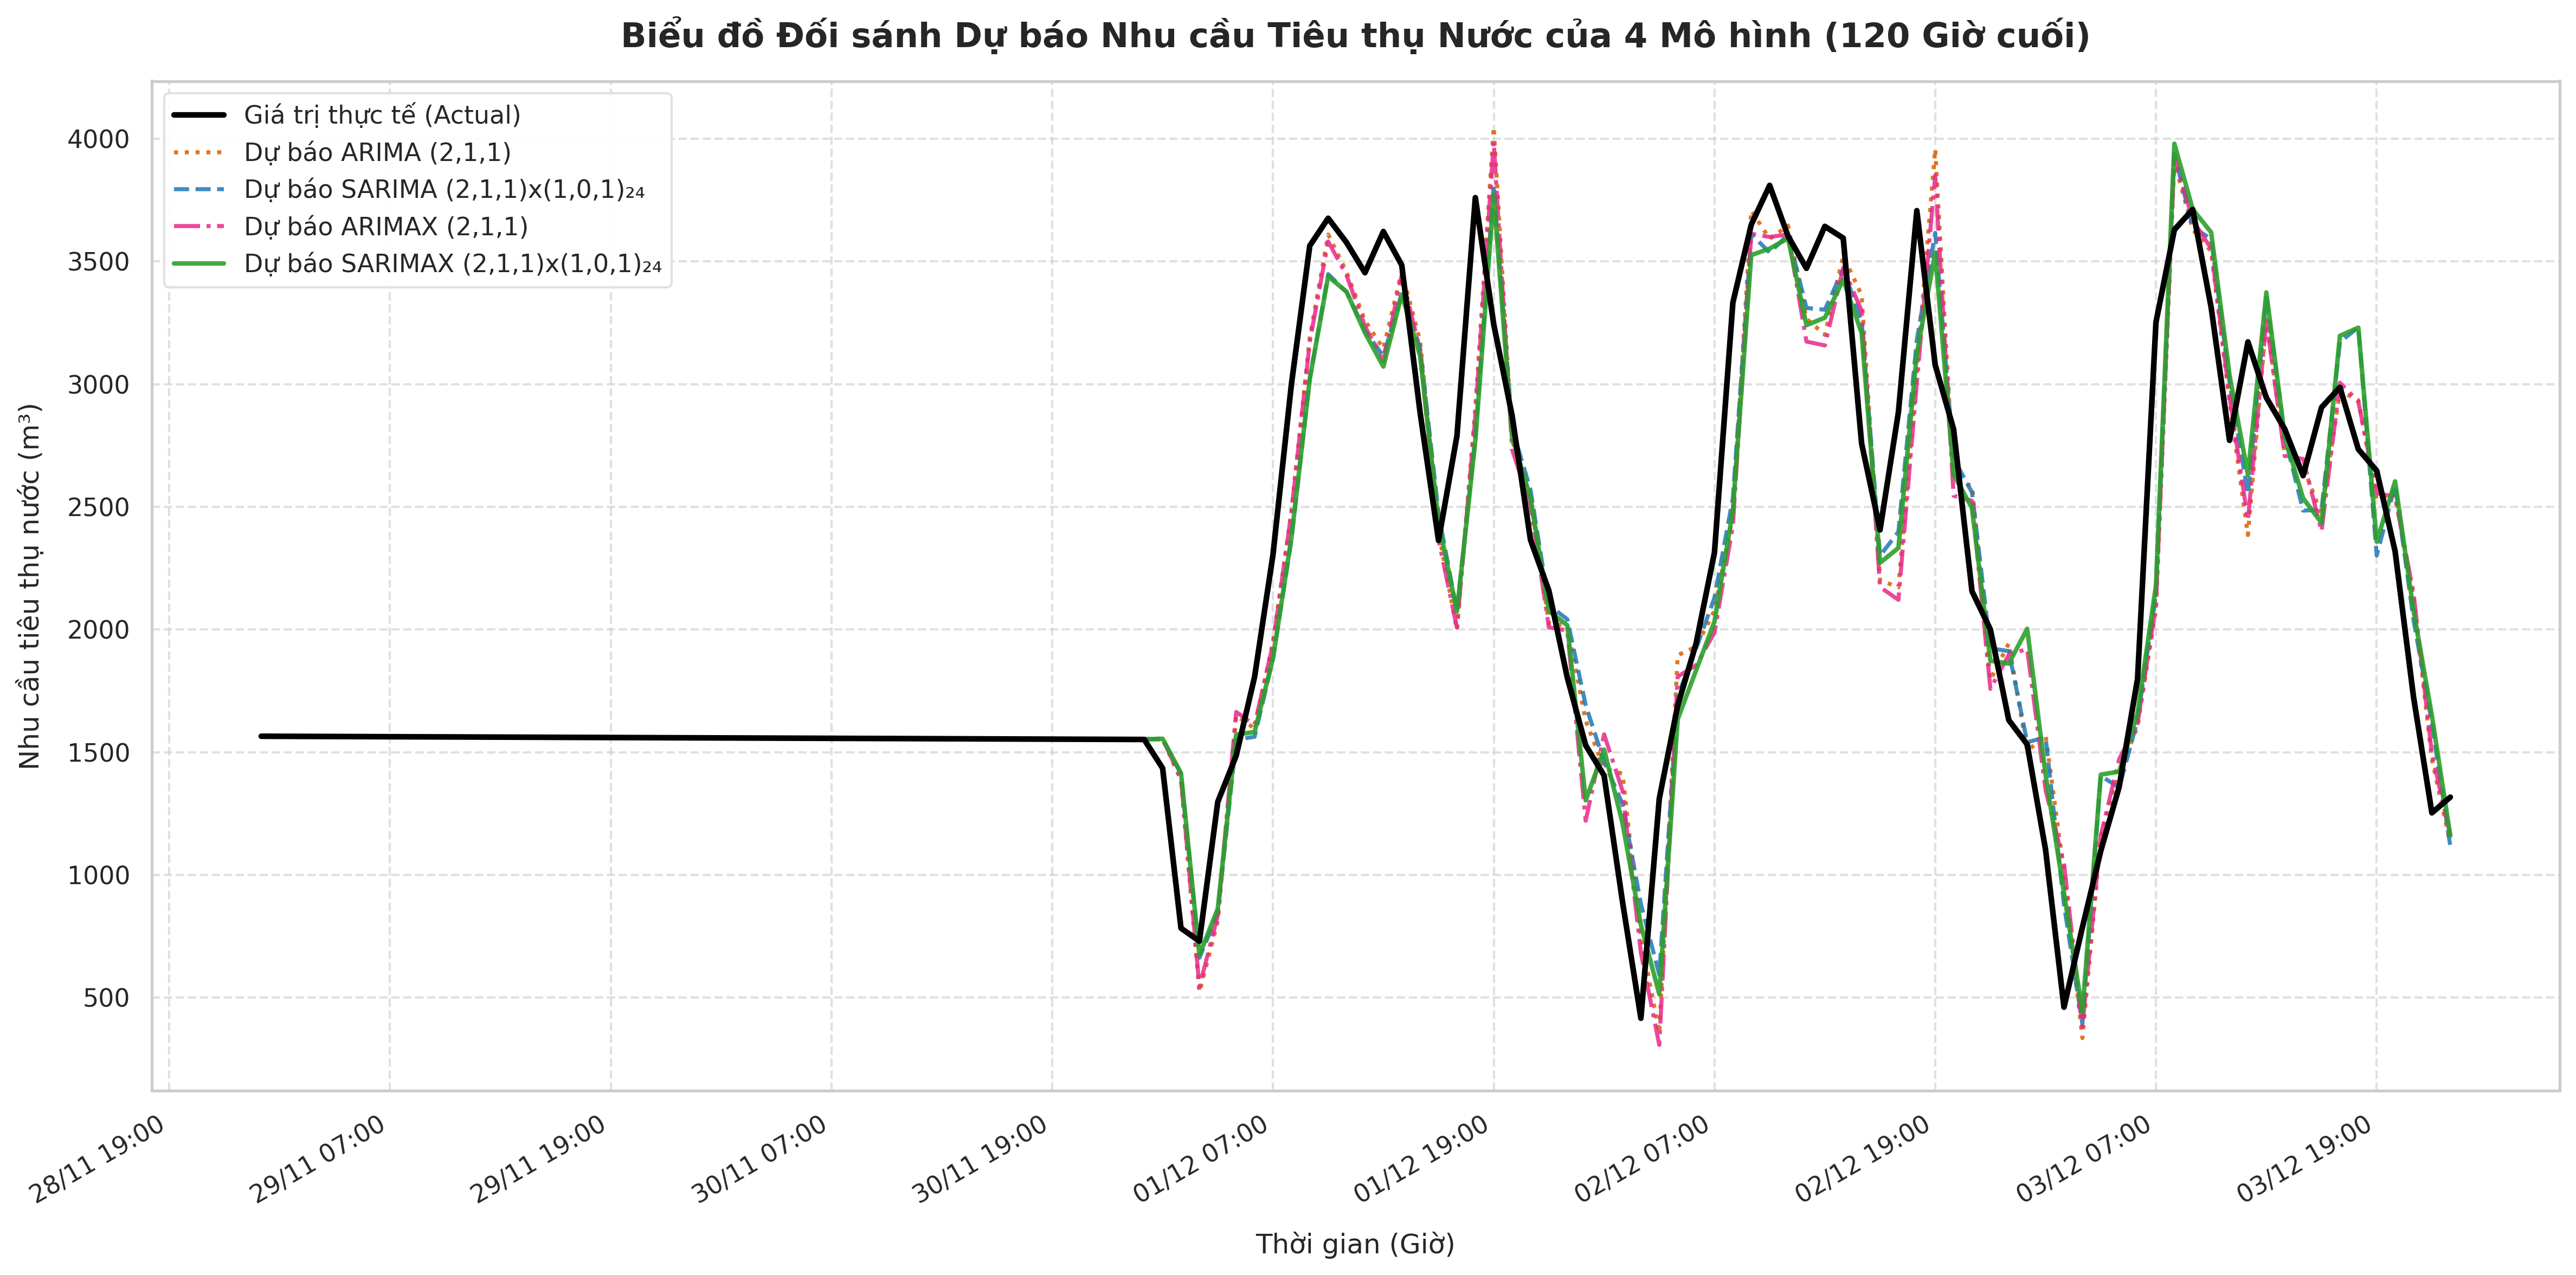

In [45]:
# =========================================================================
# 1. BIỂU ĐỒ TỔNG QUAN SO SÁNH 4 MÔ HÌNH (120 GIỜ CUỐI)
# =========================================================================
fig1, ax1 = plt.subplots(figsize=(16, 8), dpi=300)

# Vẽ đường thực tế
ax1.plot(actual_val, label='Giá trị thực tế (Actual)', color=colors['Actual'], linewidth=2.5, zorder=10)

# Vẽ các đường dự báo với các kiểu nét khác nhau và độ trong suốt hài hòa
ax1.plot(arima_val, label='Dự báo ARIMA (2,1,1)', color=colors['ARIMA'], linestyle=':', linewidth=1.8, alpha=0.85)
ax1.plot(sarima_val, label='Dự báo SARIMA (2,1,1)x(1,0,1)₂₄', color=colors['SARIMA'], linestyle='--', linewidth=1.8, alpha=0.85)
ax1.plot(arimax_val, label='Dự báo ARIMAX (2,1,1)', color=colors['ARIMAX'], linestyle='-.', linewidth=1.8, alpha=0.85)
ax1.plot(sarimax_val, label='Dự báo SARIMAX (2,1,1)x(1,0,1)₂₄', color=colors['SARIMAX'], linestyle='-', linewidth=2.0, alpha=0.9)

# Thiết lập chi tiết đồ họa chuyên nghiệp
ax1.set_title("Biểu đồ Đối sánh Dự báo Nhu cầu Tiêu thụ Nước của 4 Mô hình (120 Giờ cuối)", fontsize=15, fontweight='bold', pad=15)
ax1.set_xlabel("Thời gian (Giờ)", fontsize=12, labelpad=10)
ax1.set_ylabel("Nhu cầu tiêu thụ nước (m³)", fontsize=12, labelpad=10)

# Định dạng trục thời gian
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:00'))
ax1.xaxis.set_major_locator(mdates.HourLocator(interval=12))
plt.xticks(rotation=30, ha='right')

# Grid và Legend
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.95, edgecolor='#E0E0E0', fontsize=11)

plt.tight_layout()
fig1.savefig(f"{vis_dir}/01_model_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

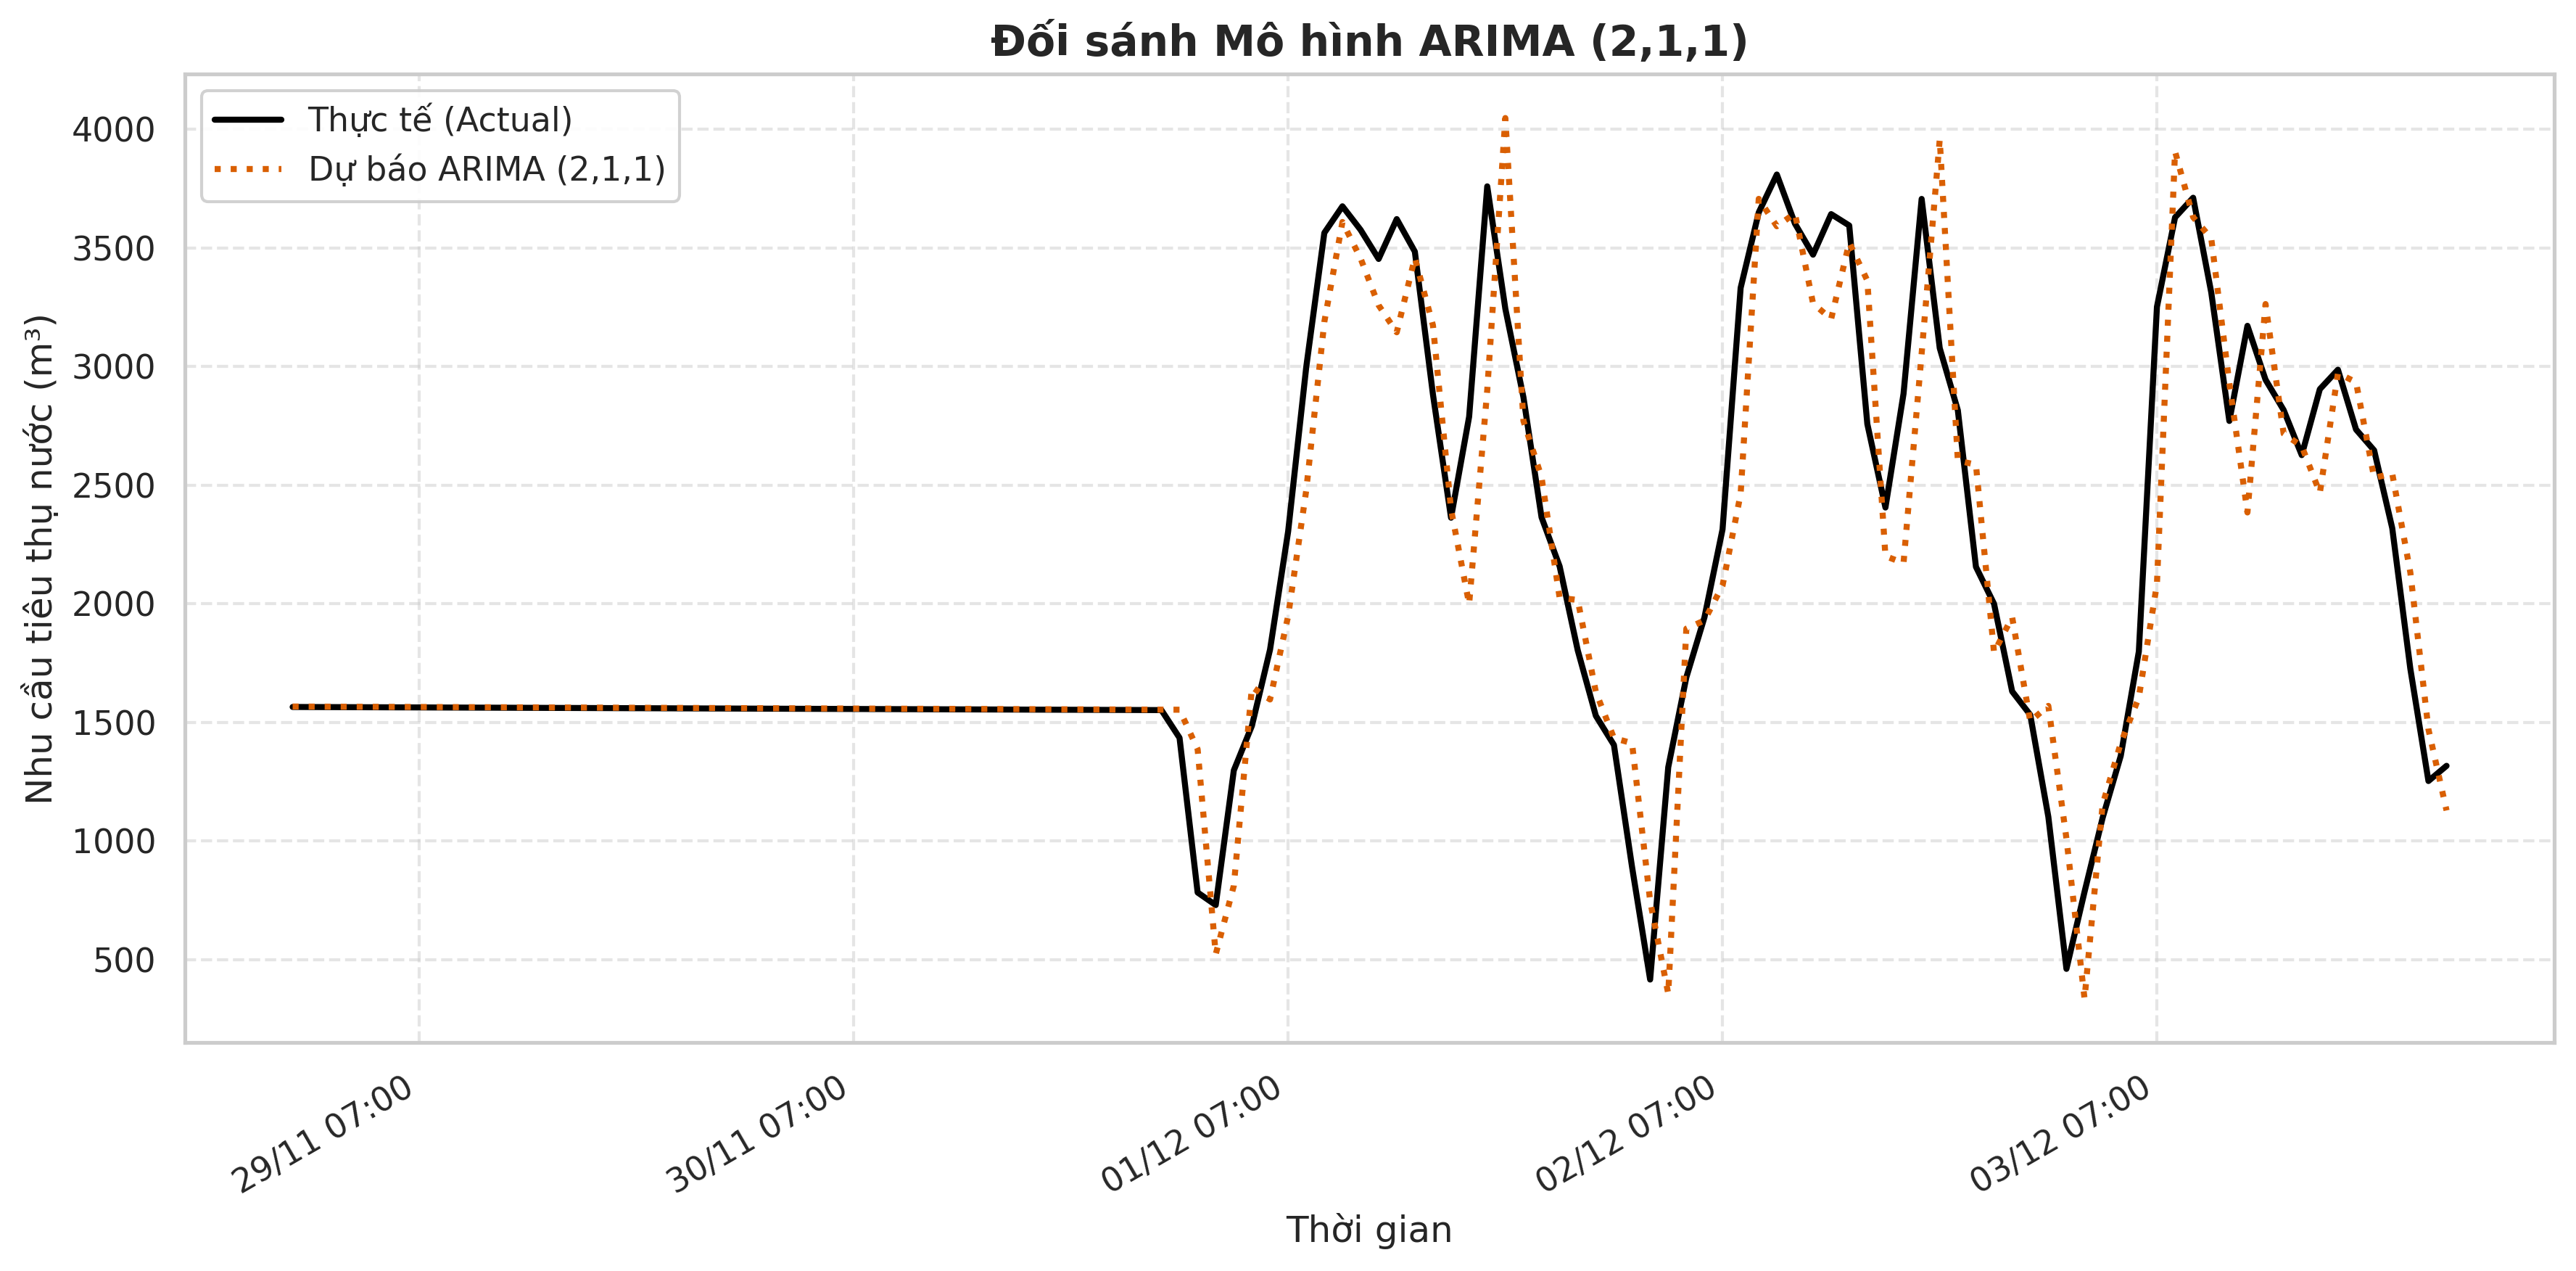

In [46]:
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

ax.plot(actual_val, label='Thực tế (Actual)', color=colors['Actual'], linewidth=2.0)
ax.plot(arima_val, label='Dự báo ARIMA (2,1,1)', color=colors['ARIMA'], linestyle=':', linewidth=2.0)

ax.set_title("Đối sánh Mô hình ARIMA (2,1,1)", fontsize=14, fontweight='bold')
ax.set_ylabel("Nhu cầu tiêu thụ nước (m³)", fontsize=12)
ax.set_xlabel("Thời gian", fontsize=12)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:00'))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=24))
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
fig.savefig(f"{vis_dir}/02_ARIMA_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

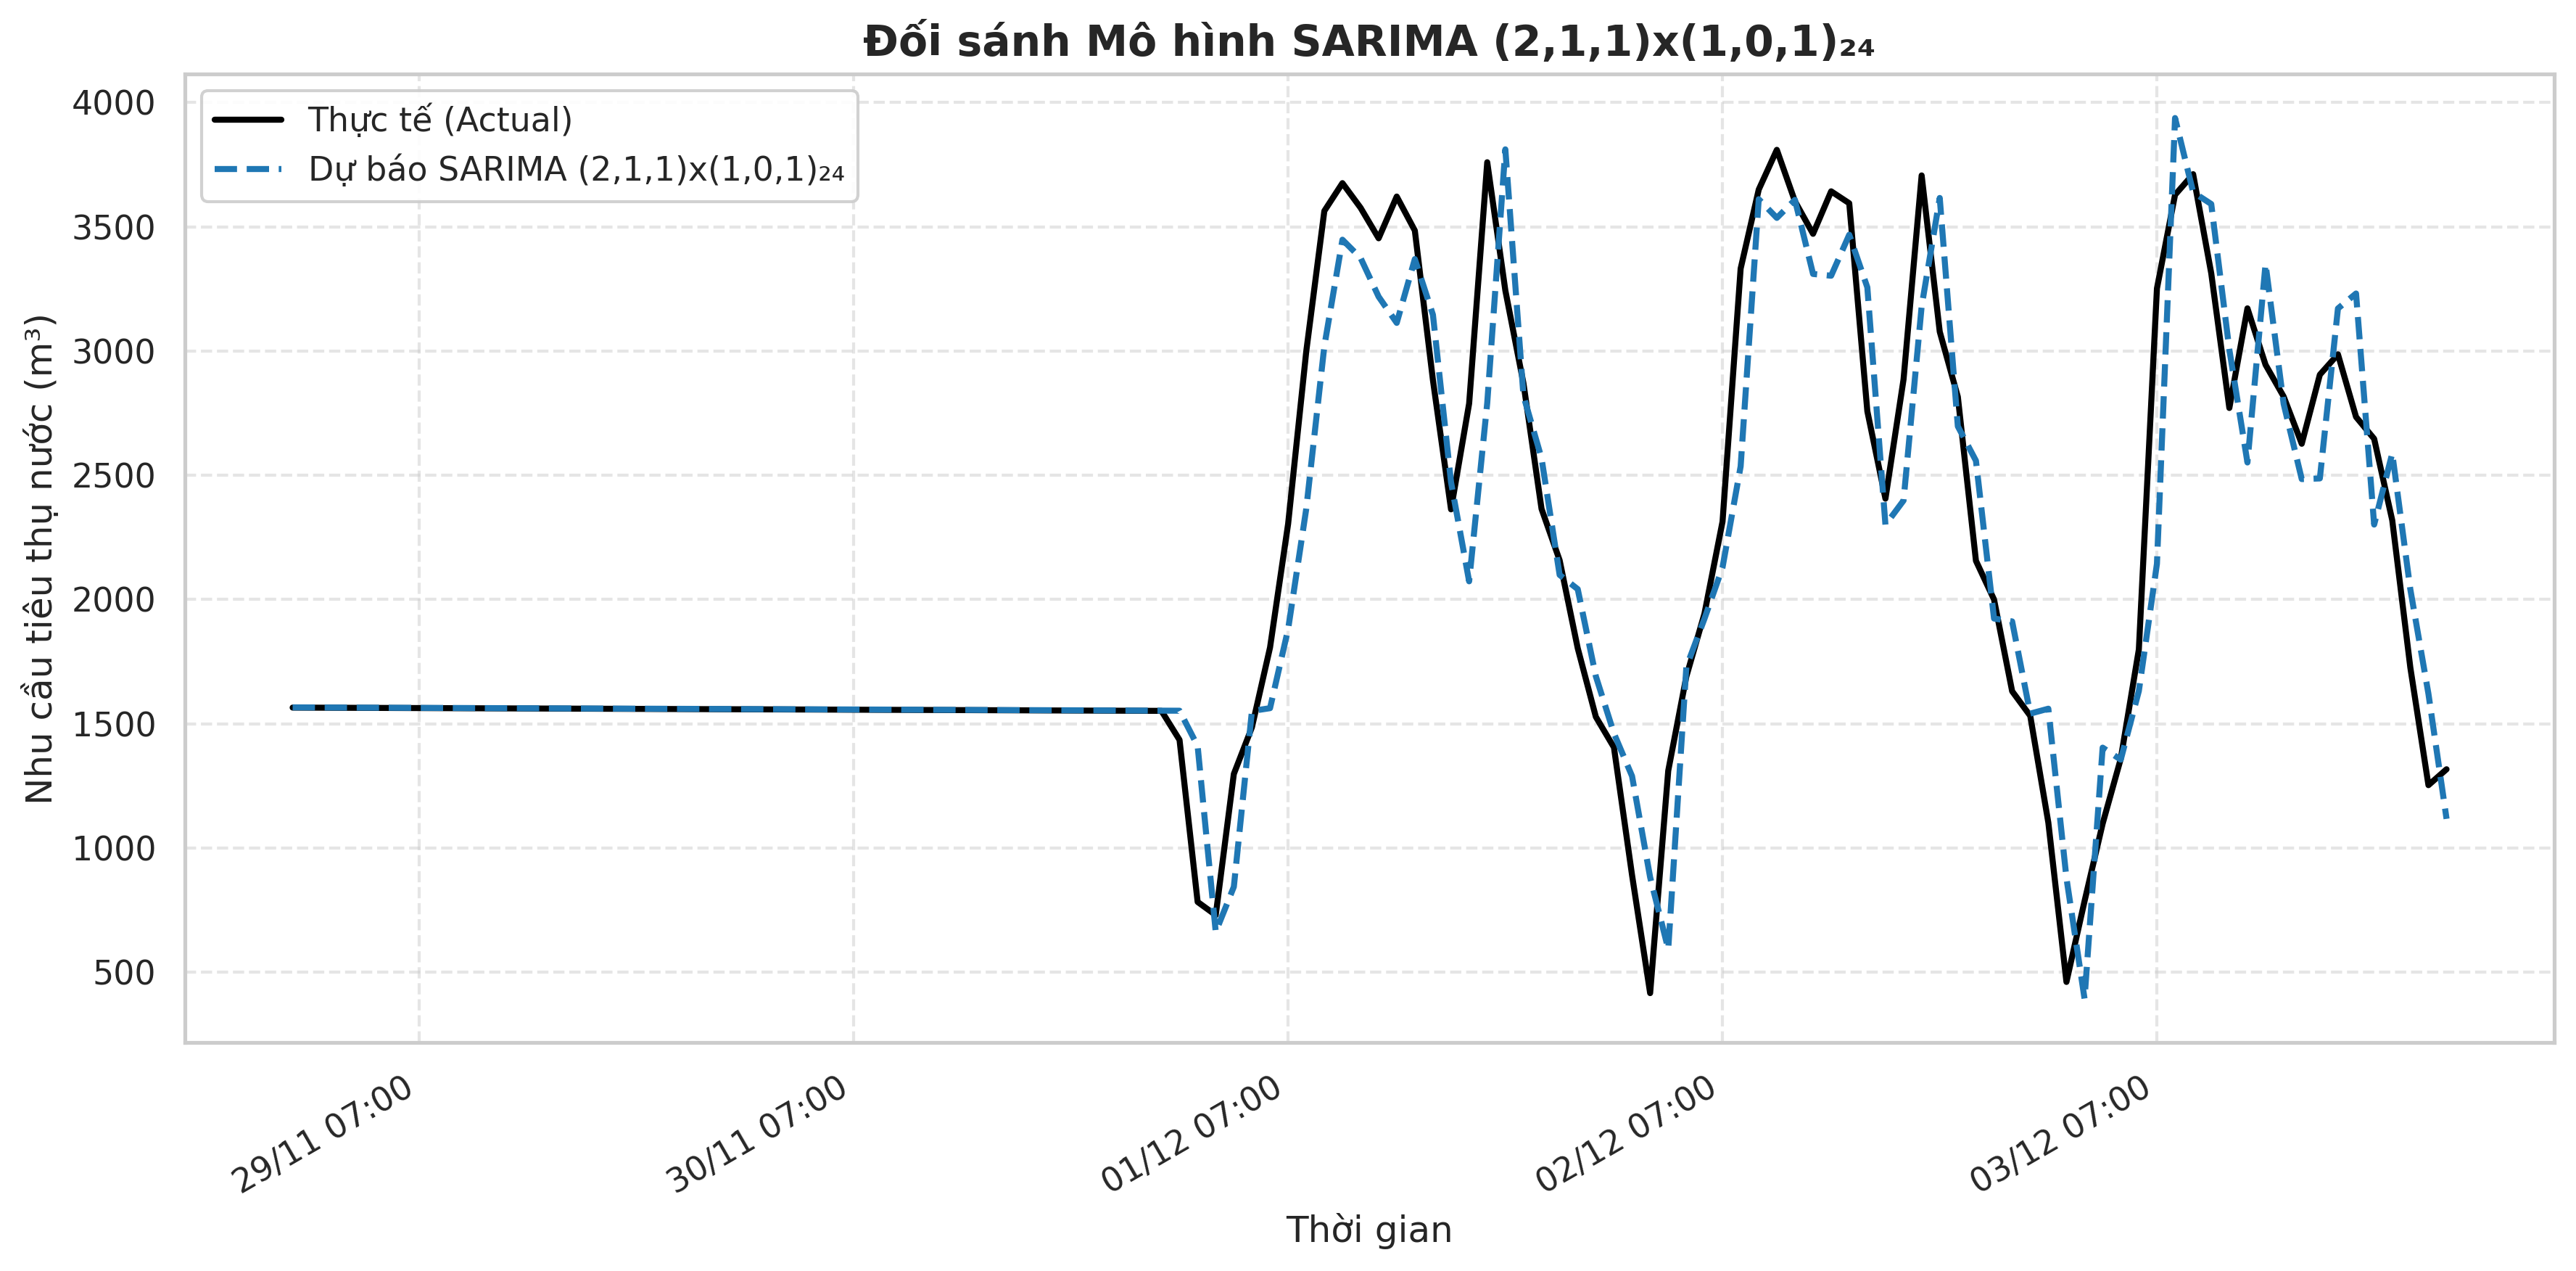

In [47]:
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

ax.plot(actual_val, label='Thực tế (Actual)', color=colors['Actual'], linewidth=2.0)
ax.plot(sarima_val, label='Dự báo SARIMA (2,1,1)x(1,0,1)₂₄', color=colors['SARIMA'], linestyle='--', linewidth=2.0)

ax.set_title("Đối sánh Mô hình SARIMA (2,1,1)x(1,0,1)₂₄", fontsize=14, fontweight='bold')
ax.set_ylabel("Nhu cầu tiêu thụ nước (m³)", fontsize=12)
ax.set_xlabel("Thời gian", fontsize=12)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:00'))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=24))
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
fig.savefig(f"{vis_dir}/03_SARIMA_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

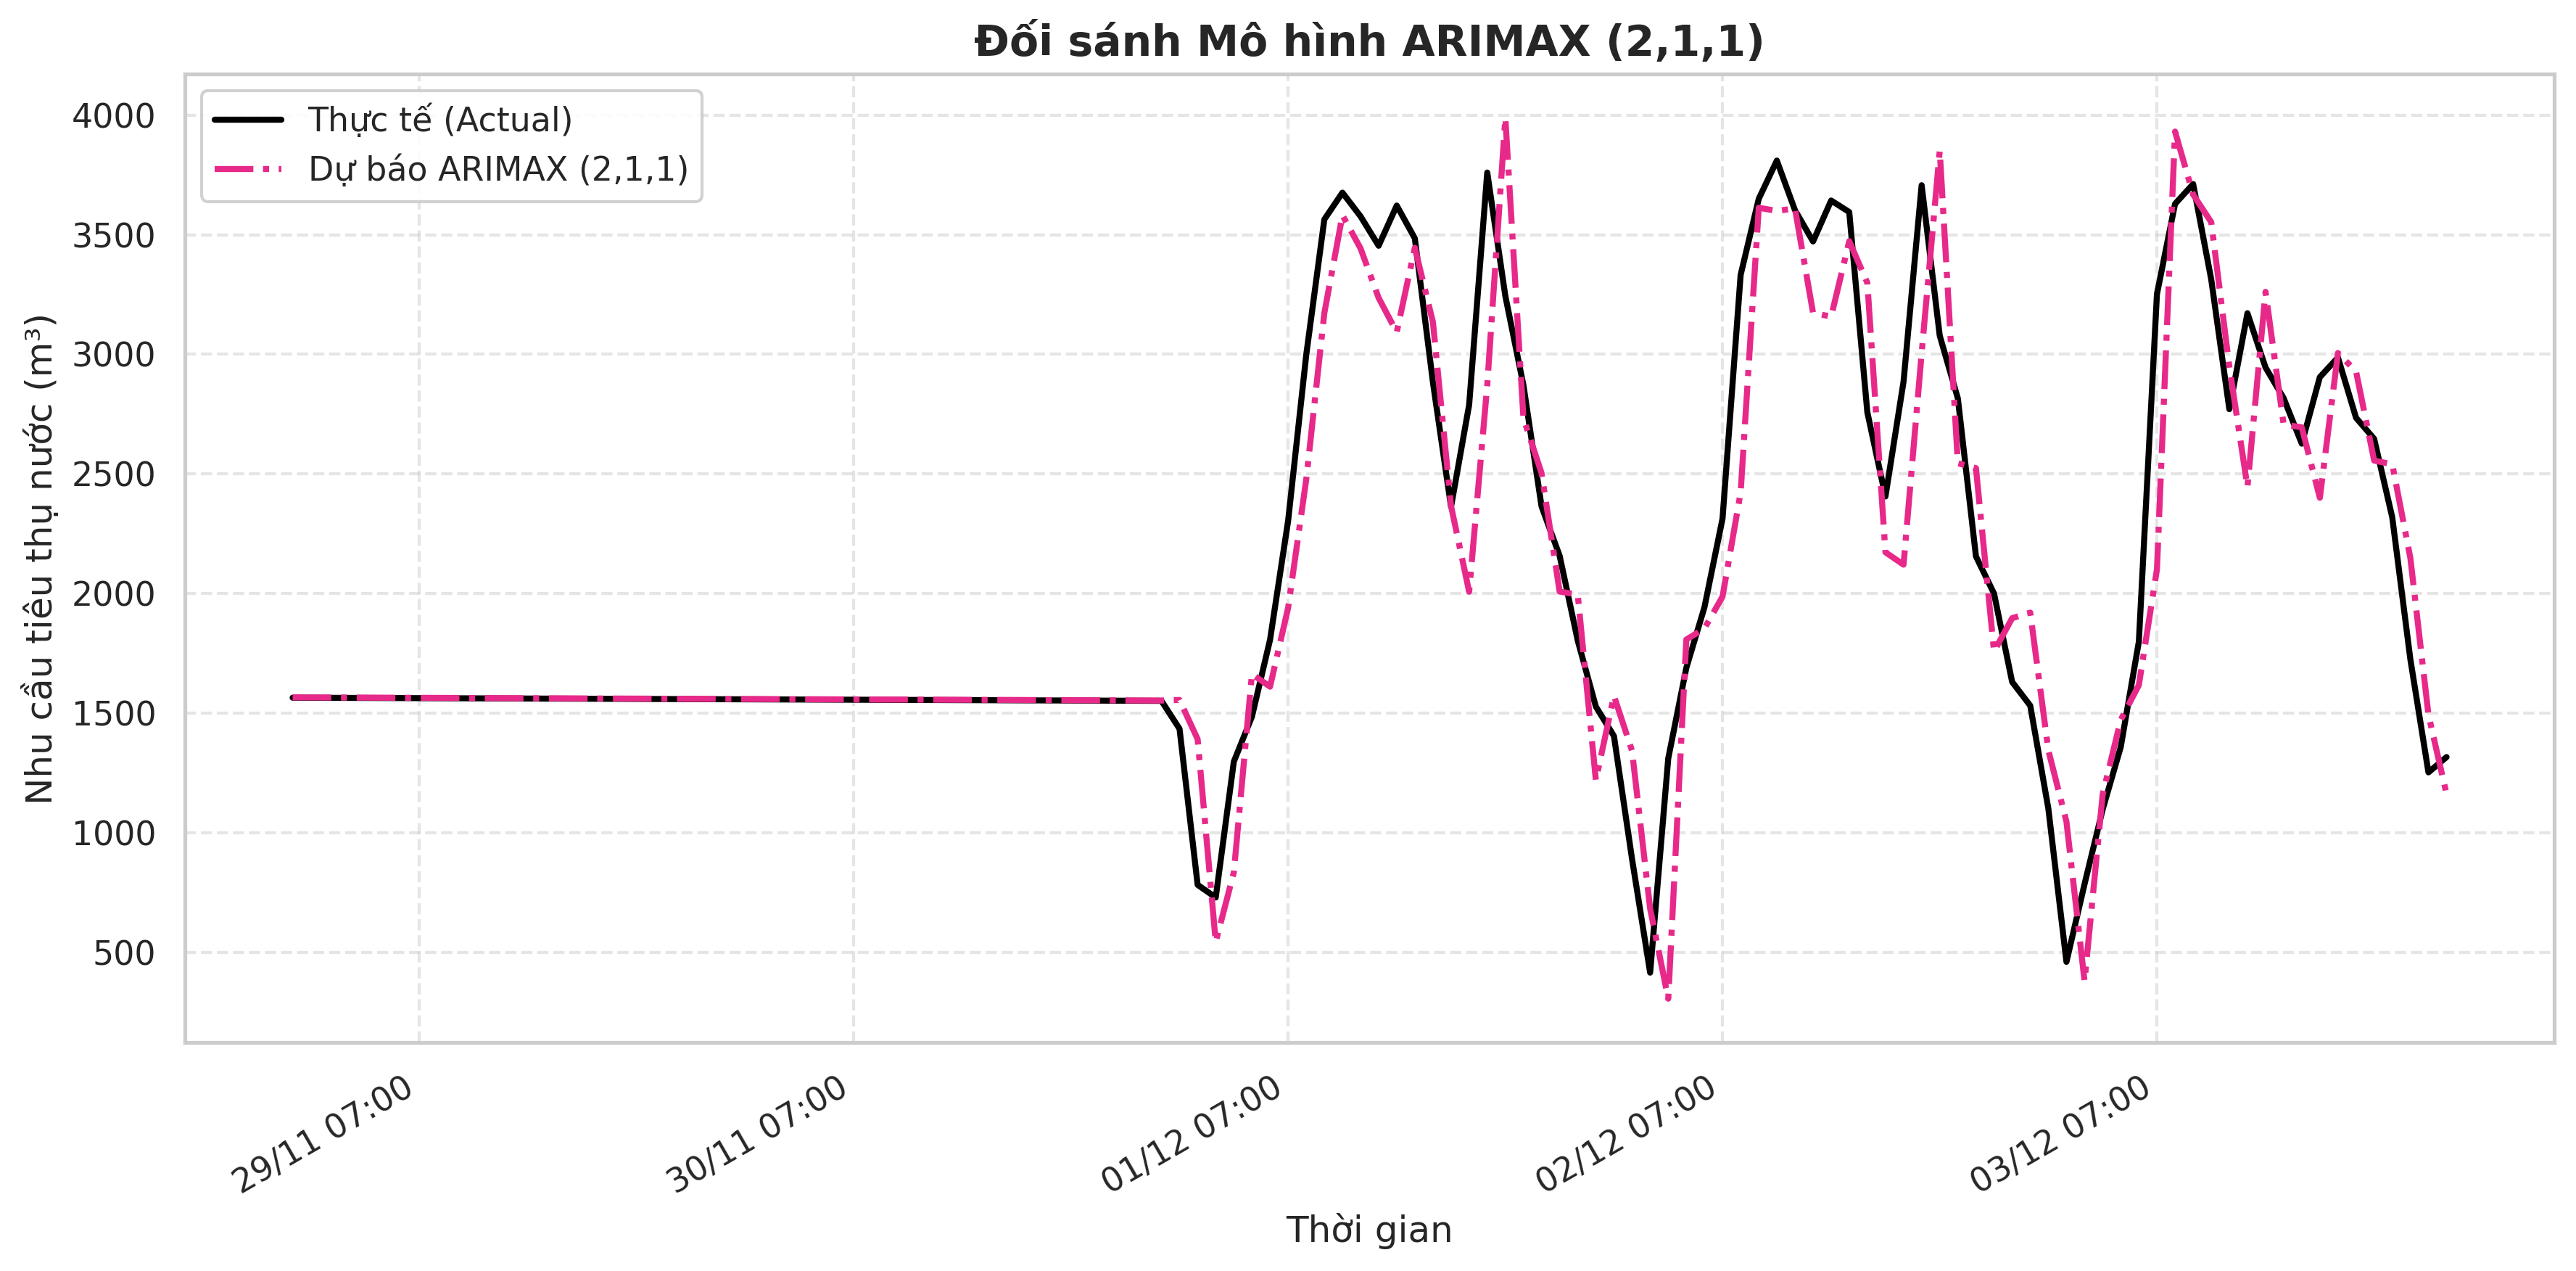

In [48]:
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

ax.plot(actual_val, label='Thực tế (Actual)', color=colors['Actual'], linewidth=2.0)
ax.plot(arimax_val, label='Dự báo ARIMAX (2,1,1)', color=colors['ARIMAX'], linestyle='-.', linewidth=2.0)

ax.set_title("Đối sánh Mô hình ARIMAX (2,1,1)", fontsize=14, fontweight='bold')
ax.set_ylabel("Nhu cầu tiêu thụ nước (m³)", fontsize=12)
ax.set_xlabel("Thời gian", fontsize=12)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:00'))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=24))
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
fig.savefig(f"{vis_dir}/04_ARIMAX_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

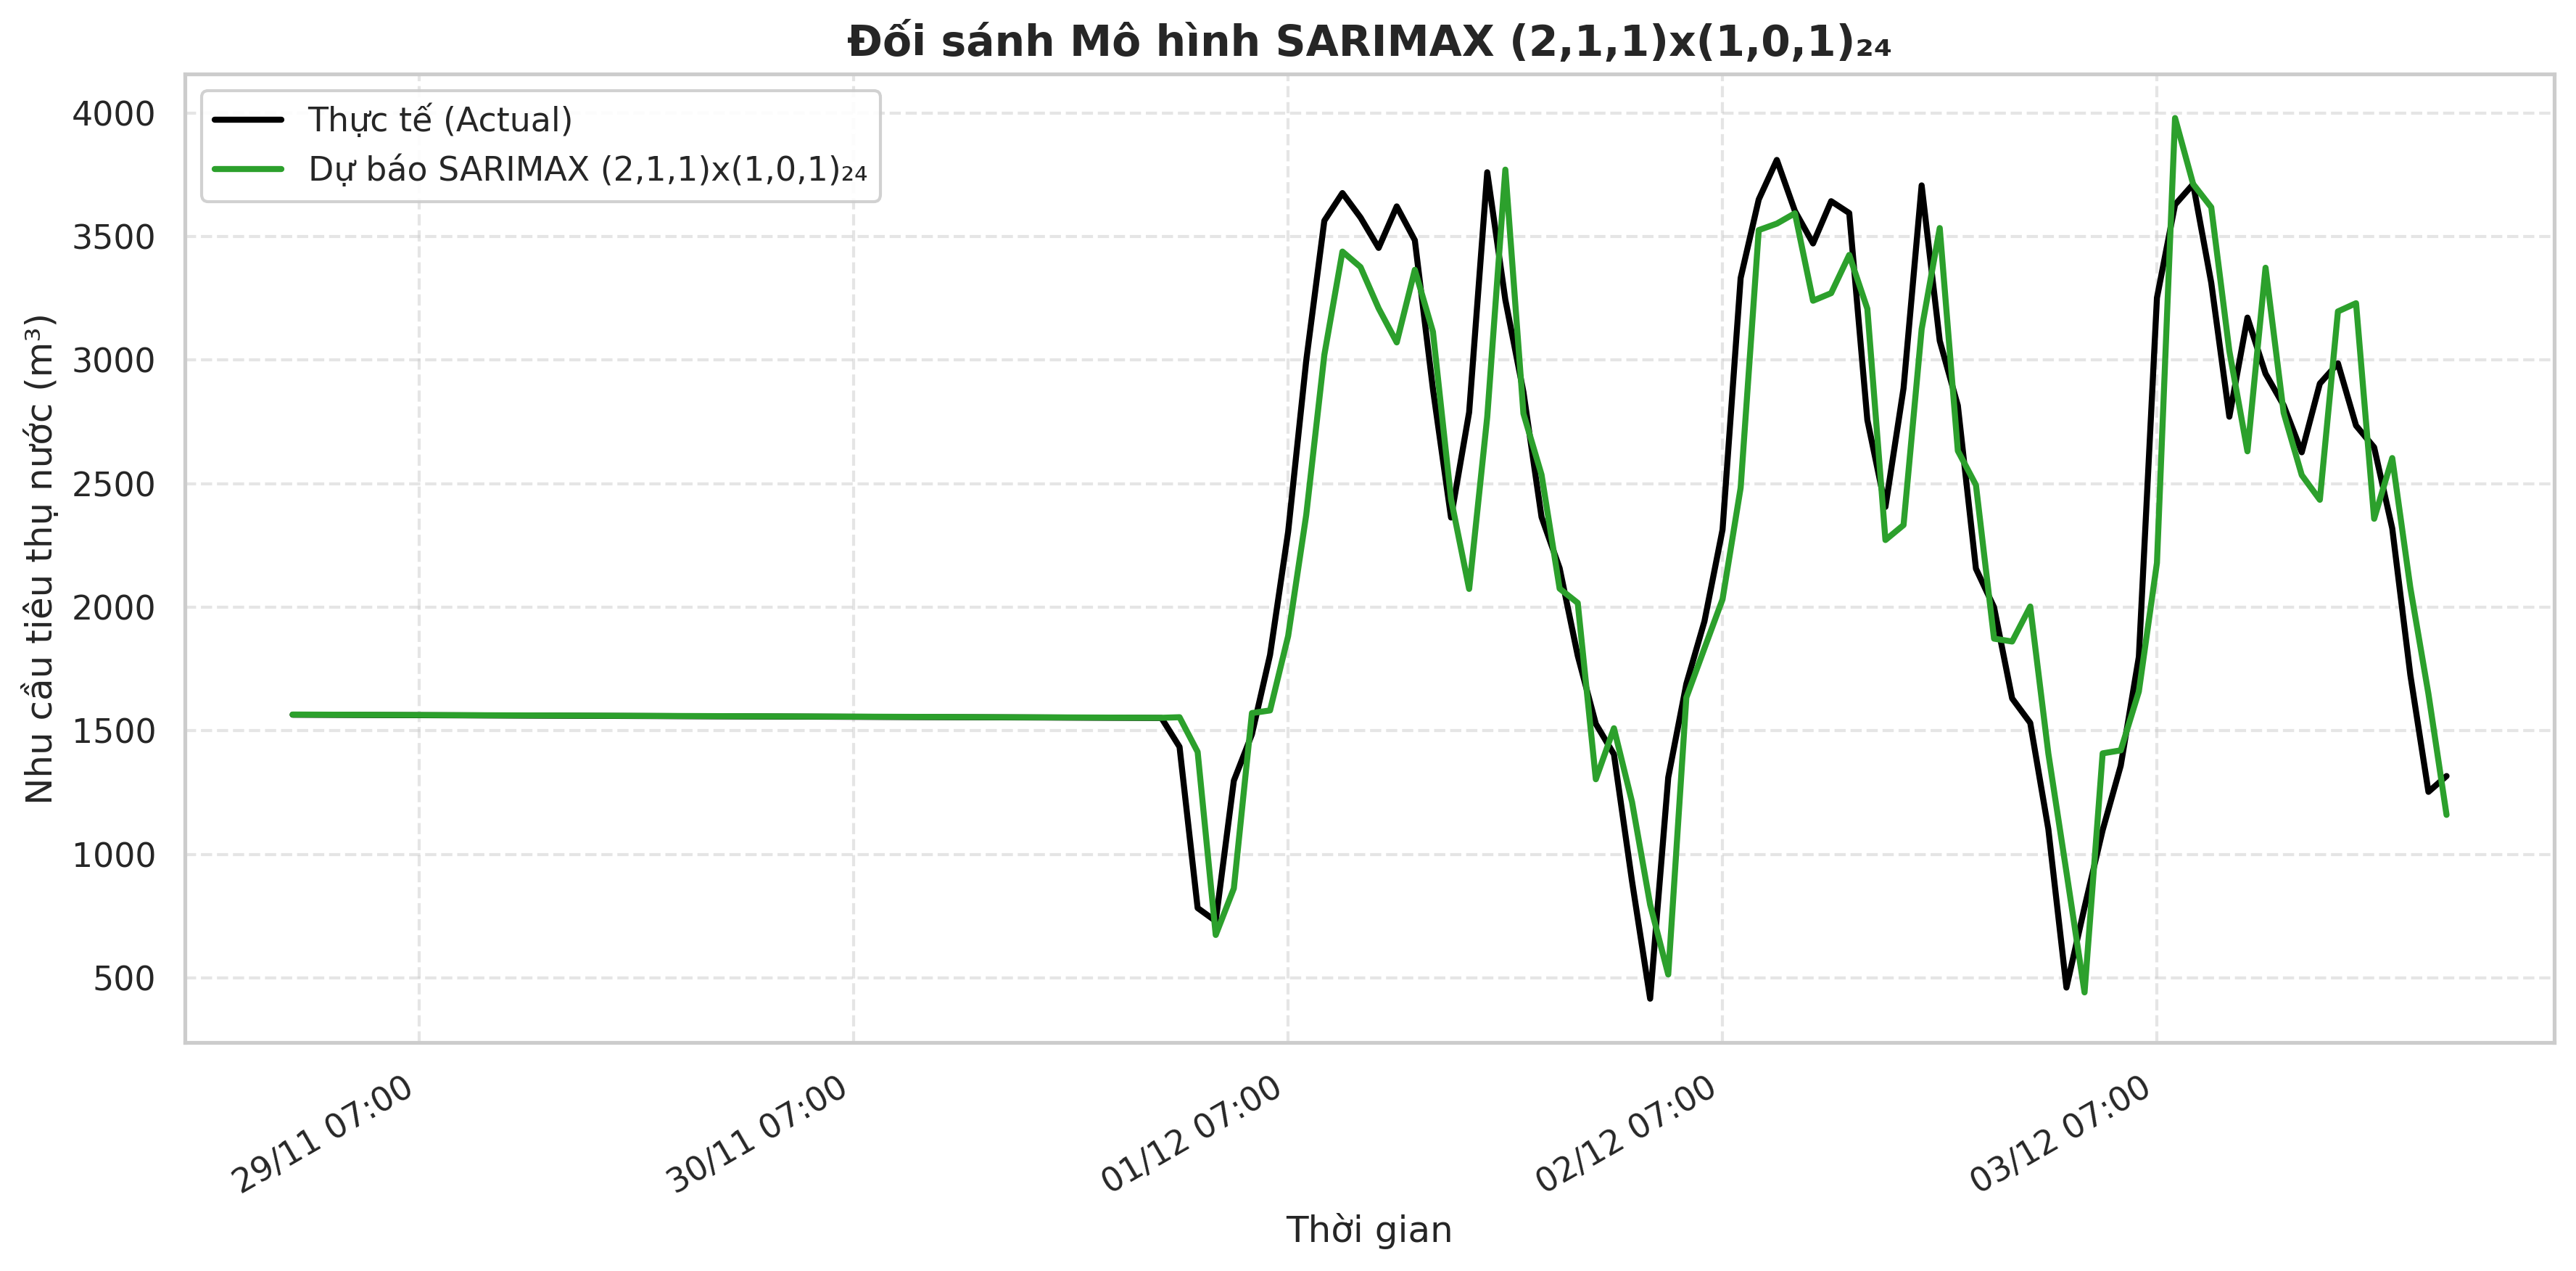

In [49]:
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

ax.plot(actual_val, label='Thực tế (Actual)', color=colors['Actual'], linewidth=2.0)
ax.plot(sarimax_val, label='Dự báo SARIMAX (2,1,1)x(1,0,1)₂₄', color=colors['SARIMAX'], linestyle='-', linewidth=2.0)

ax.set_title("Đối sánh Mô hình SARIMAX (2,1,1)x(1,0,1)₂₄", fontsize=14, fontweight='bold')
ax.set_ylabel("Nhu cầu tiêu thụ nước (m³)", fontsize=12)
ax.set_xlabel("Thời gian", fontsize=12)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:00'))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=24))
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
fig.savefig(f"{vis_dir}/05_SARIMAX_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

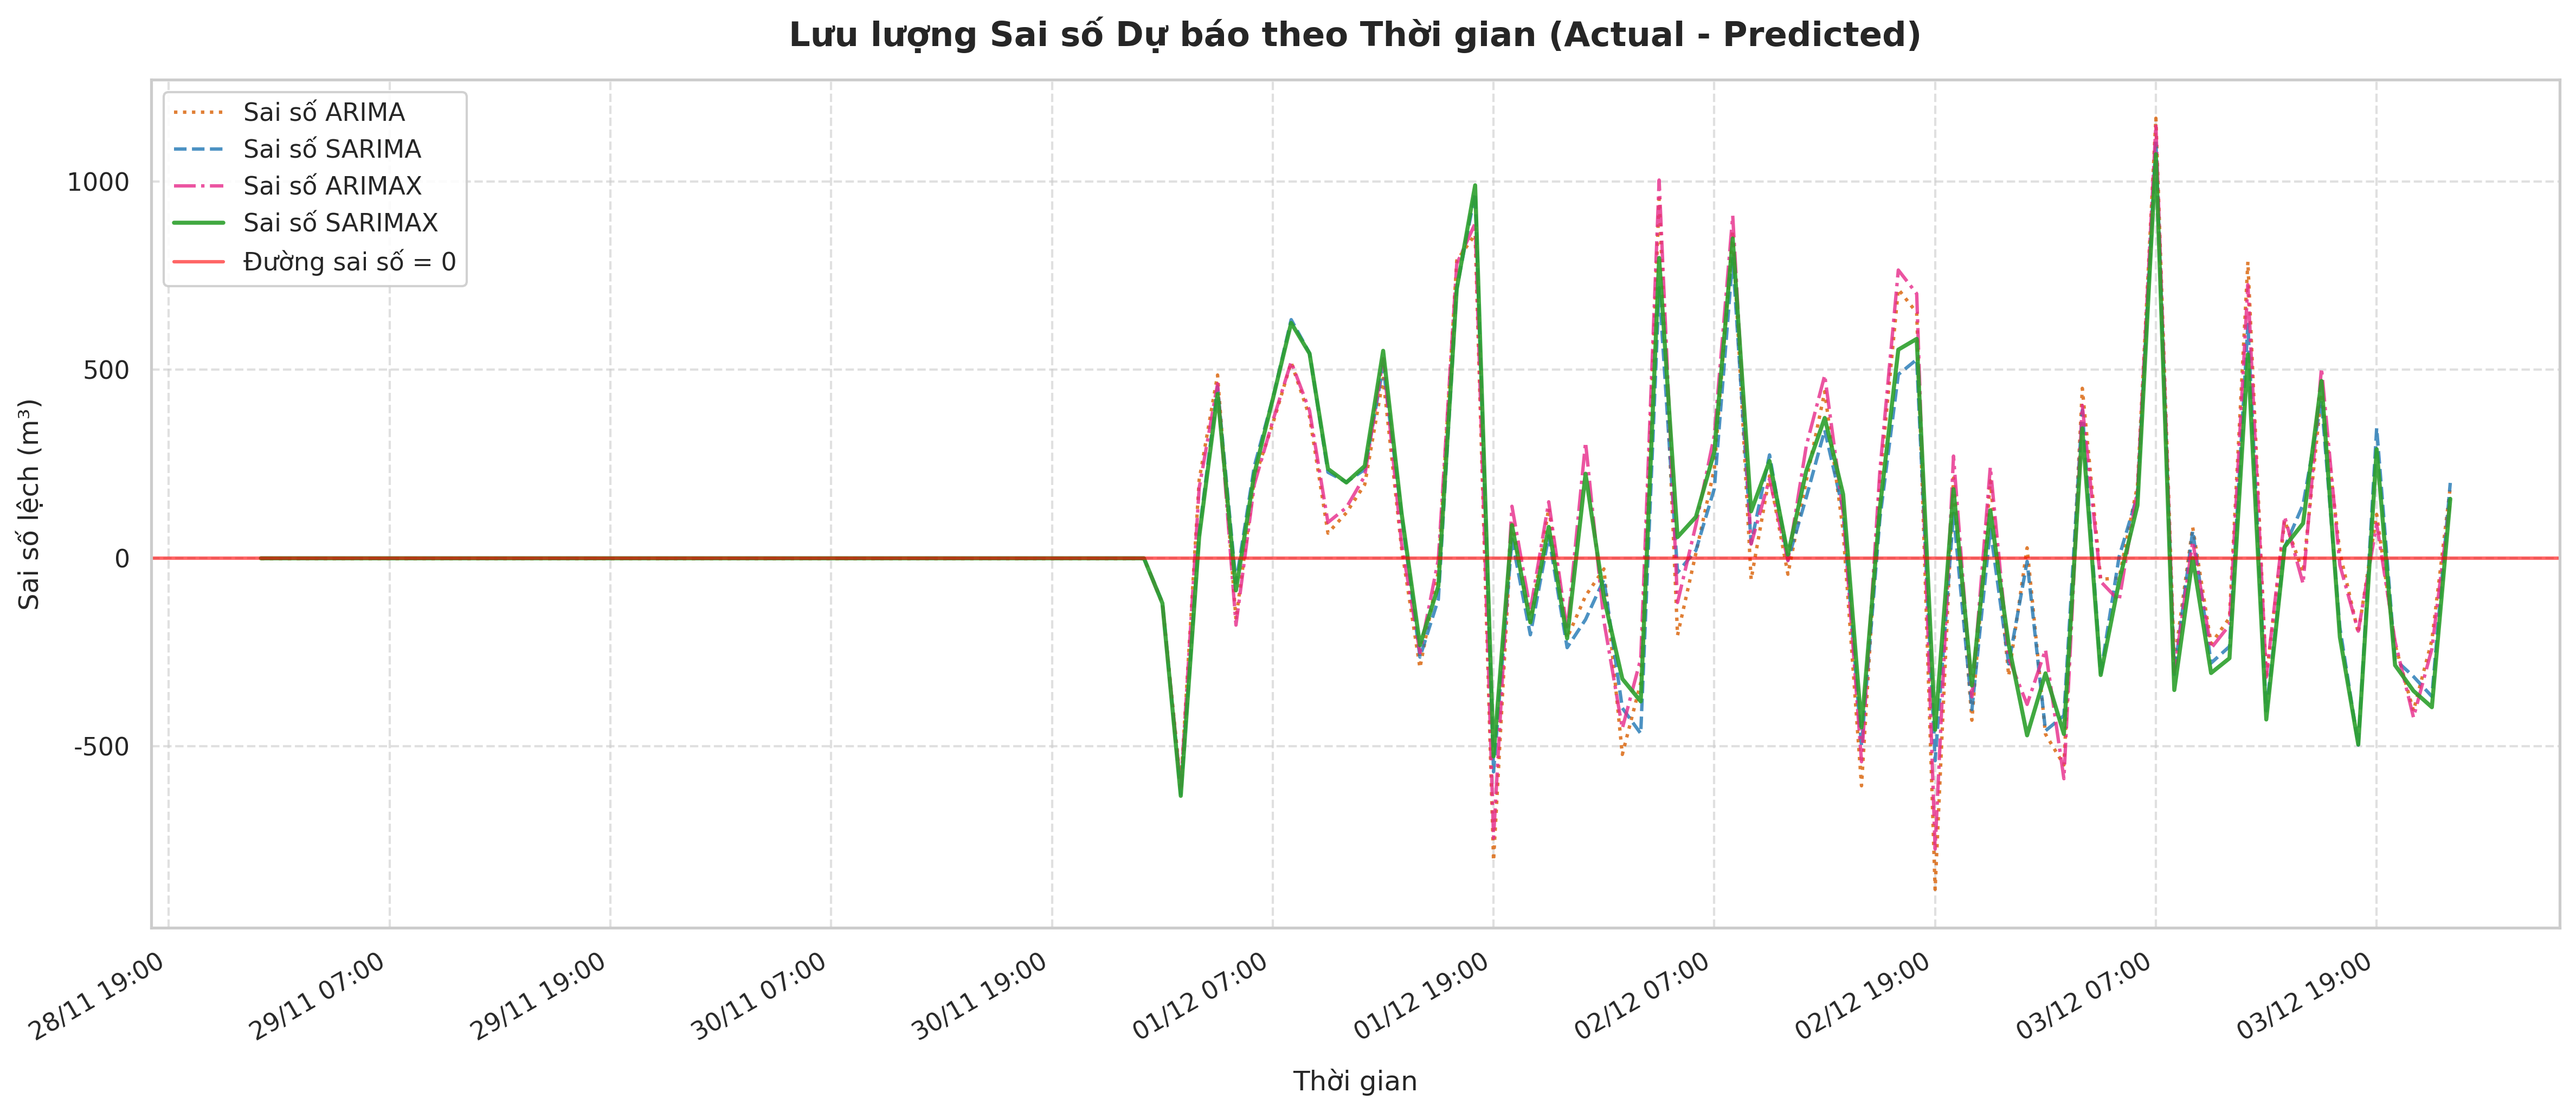

In [50]:
# =========================================================================
# 3. BIỂU ĐỒ SAI SỐ DỰ BÁO (FORECAST ERROR OVER TIME)
# =========================================================================
fig3, ax3 = plt.subplots(figsize=(16, 7), dpi=300)

# Tính toán sai số (Actual - Predicted)
error_arima = actual_val - arima_val
error_sarima = actual_val - sarima_val
error_arimax = actual_val - arimax_val
error_sarimax = actual_val - sarimax_val

# Vẽ sai số
ax3.plot(error_arima, label='Sai số ARIMA', color=colors['ARIMA'], linestyle=':', alpha=0.8, linewidth=1.5)
ax3.plot(error_sarima, label='Sai số SARIMA', color=colors['SARIMA'], linestyle='--', alpha=0.8, linewidth=1.5)
ax3.plot(error_arimax, label='Sai số ARIMAX', color=colors['ARIMAX'], linestyle='-.', alpha=0.8, linewidth=1.5)
ax3.plot(error_sarimax, label='Sai số SARIMAX', color=colors['SARIMAX'], linestyle='-', alpha=0.9, linewidth=1.8)

# Đường tham chiếu sai số bằng 0
ax3.axhline(0, color='red', linestyle='-', linewidth=1.5, alpha=0.6, label='Đường sai số = 0')

ax3.set_title("Lưu lượng Sai số Dự báo theo Thời gian (Actual - Predicted)", fontsize=15, fontweight='bold', pad=15)
ax3.set_xlabel("Thời gian", fontsize=12, labelpad=10)
ax3.set_ylabel("Sai số lệch (m³)", fontsize=12, labelpad=10)

ax3.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:00'))
ax3.xaxis.set_major_locator(mdates.HourLocator(interval=12))
plt.xticks(rotation=30, ha='right')

ax3.grid(True, linestyle='--', alpha=0.6)
ax3.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9, fontsize=11)

plt.tight_layout()
fig3.savefig(f"{vis_dir}/03_forecast_error.png", dpi=300, bbox_inches='tight')
plt.show()

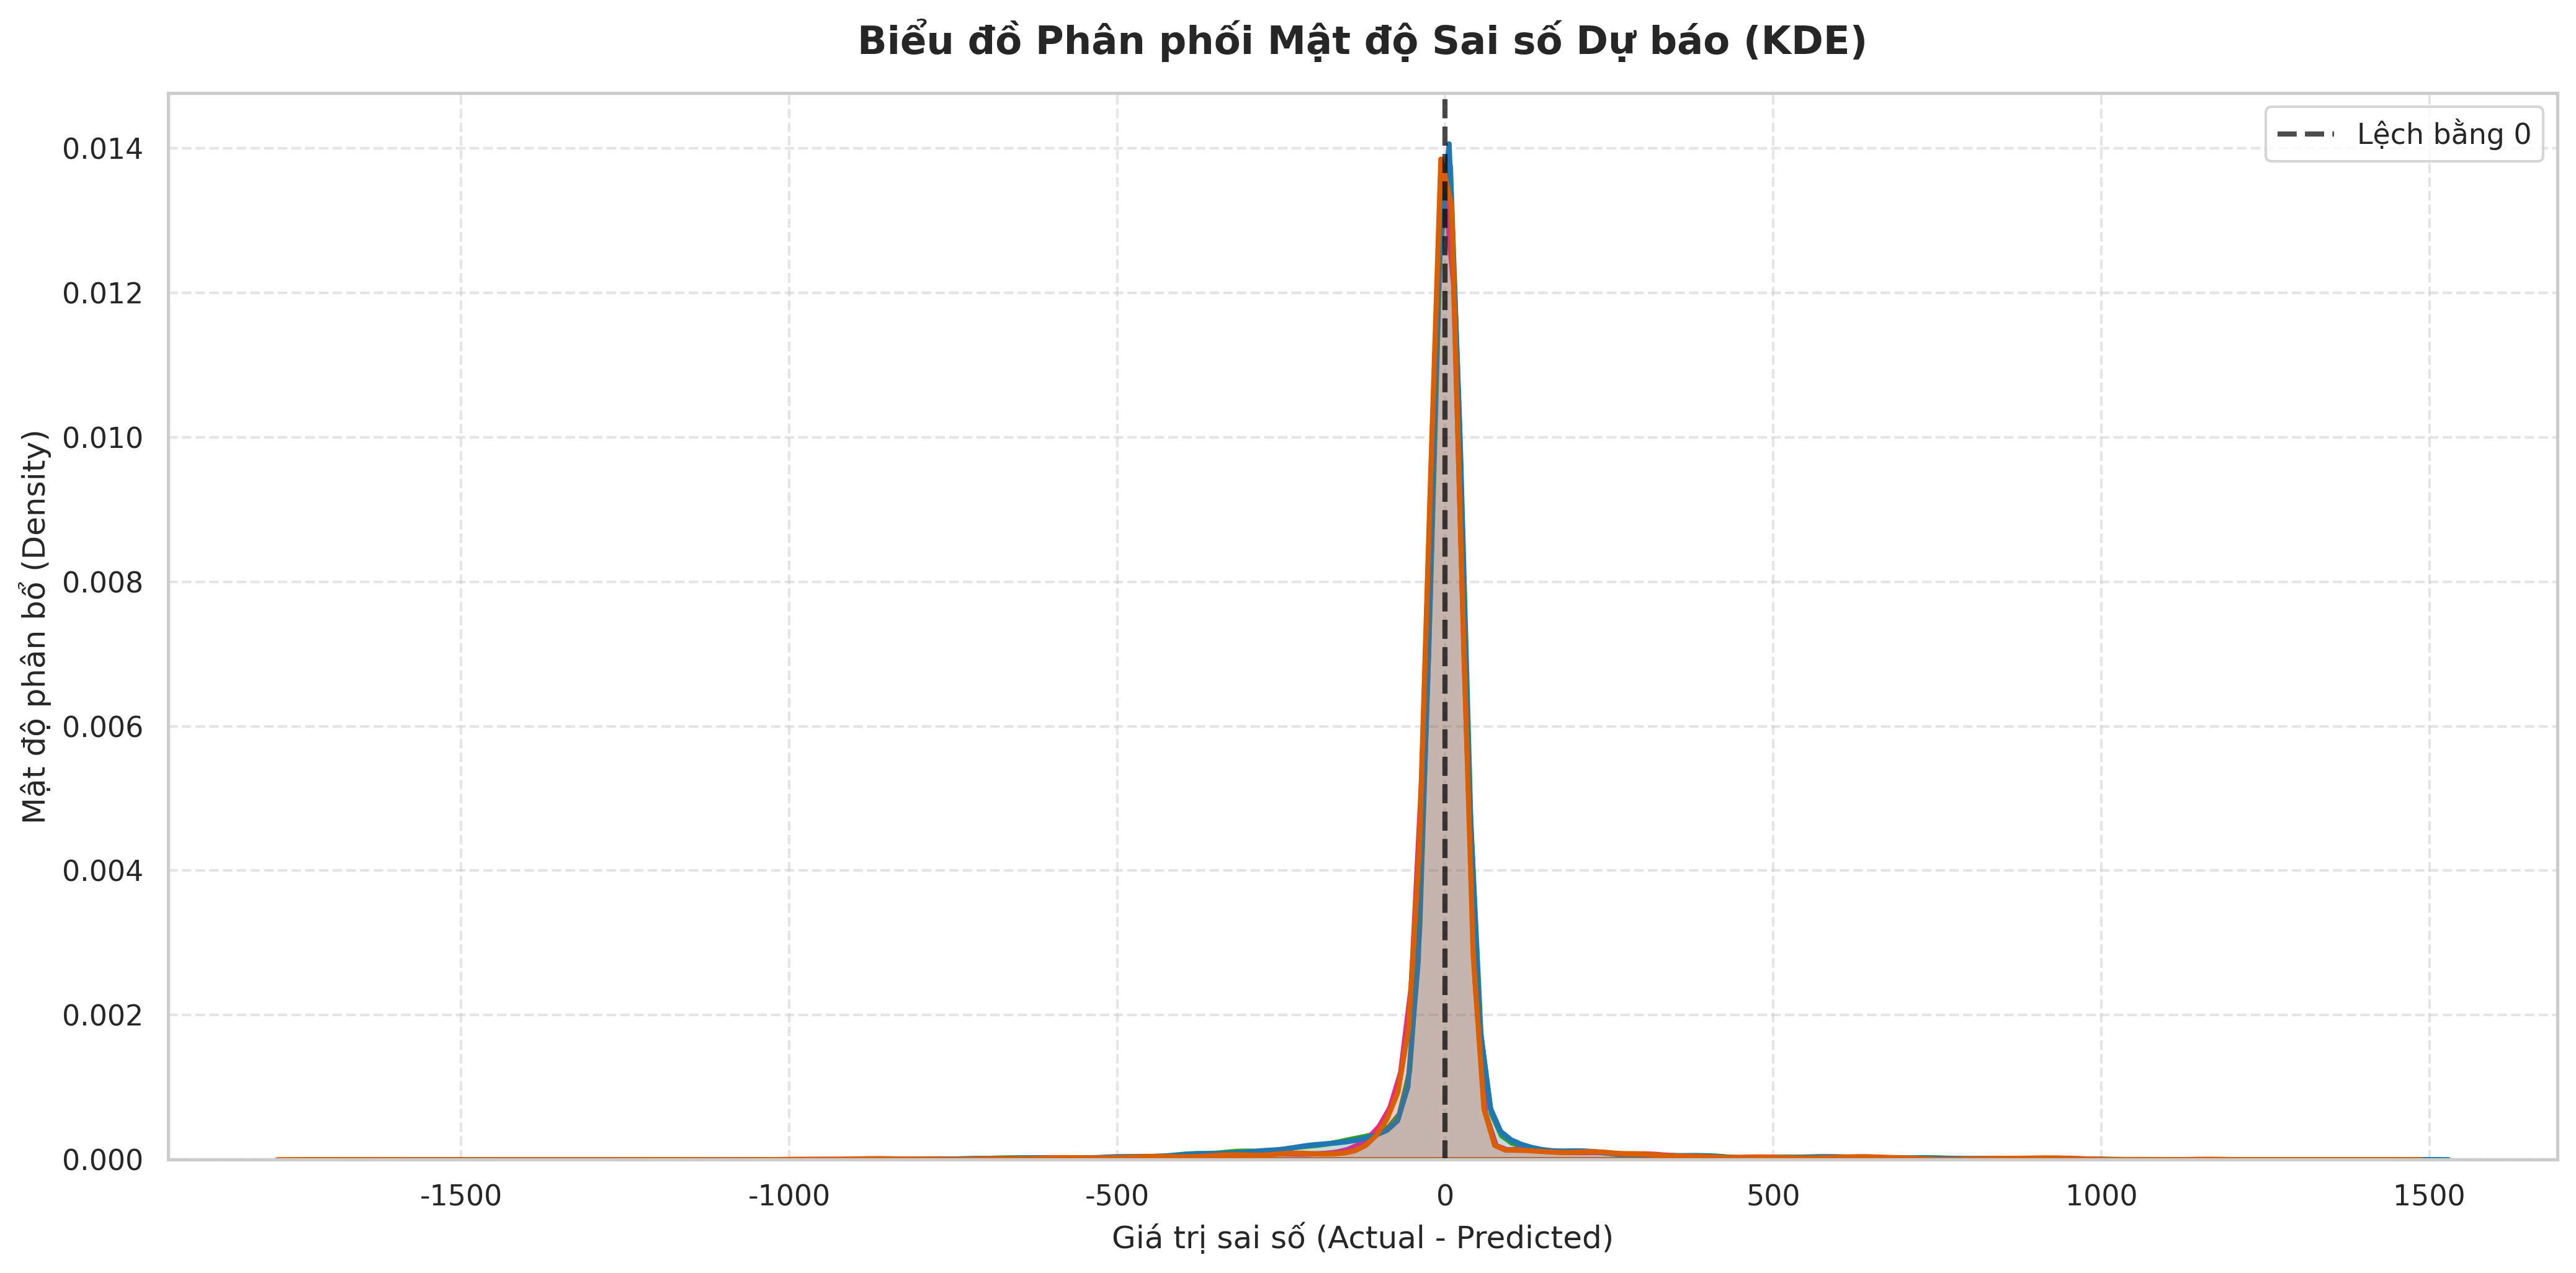

In [51]:
# =========================================================================
# 4. BIỂU ĐỒ PHÂN PHỐI SAI SỐ (ERROR DISTRIBUTION)
# =========================================================================
fig4, ax4 = plt.subplots(figsize=(14, 7), dpi=300)

# Tạo DataFrame sai số cho toàn bộ tập Test để biểu diễn chính xác phân phối tổng thể
test_errors = pd.DataFrame({
    'ARIMA': test_data - predictions_series,
    'SARIMA': test_data - sarima_predictions_series,
    'ARIMAX': test_data - arimax_predictions_series,
    'SARIMAX': test_data - sarimax_predictions_series
})

# Vẽ KDE biểu diễn phân phối
sns.kdeplot(data=test_errors, palette=[colors['ARIMA'], colors['SARIMA'], colors['ARIMAX'], colors['SARIMAX']],
            fill=True, common_norm=False, alpha=0.15, linewidth=2, ax=ax4)

# Đường tham chiếu sai số bằng 0
ax4.axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.7, label='Lệch bằng 0')

ax4.set_title("Biểu đồ Phân phối Mật độ Sai số Dự báo (KDE)", fontsize=15, fontweight='bold', pad=15)
ax4.set_xlabel("Giá trị sai số (Actual - Predicted)", fontsize=12)
ax4.set_ylabel("Mật độ phân bổ (Density)", fontsize=12)
ax4.grid(True, linestyle='--', alpha=0.5)
ax4.legend(loc='upper right', frameon=True, fontsize=11)

plt.tight_layout()
fig4.savefig(f"{vis_dir}/04_error_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

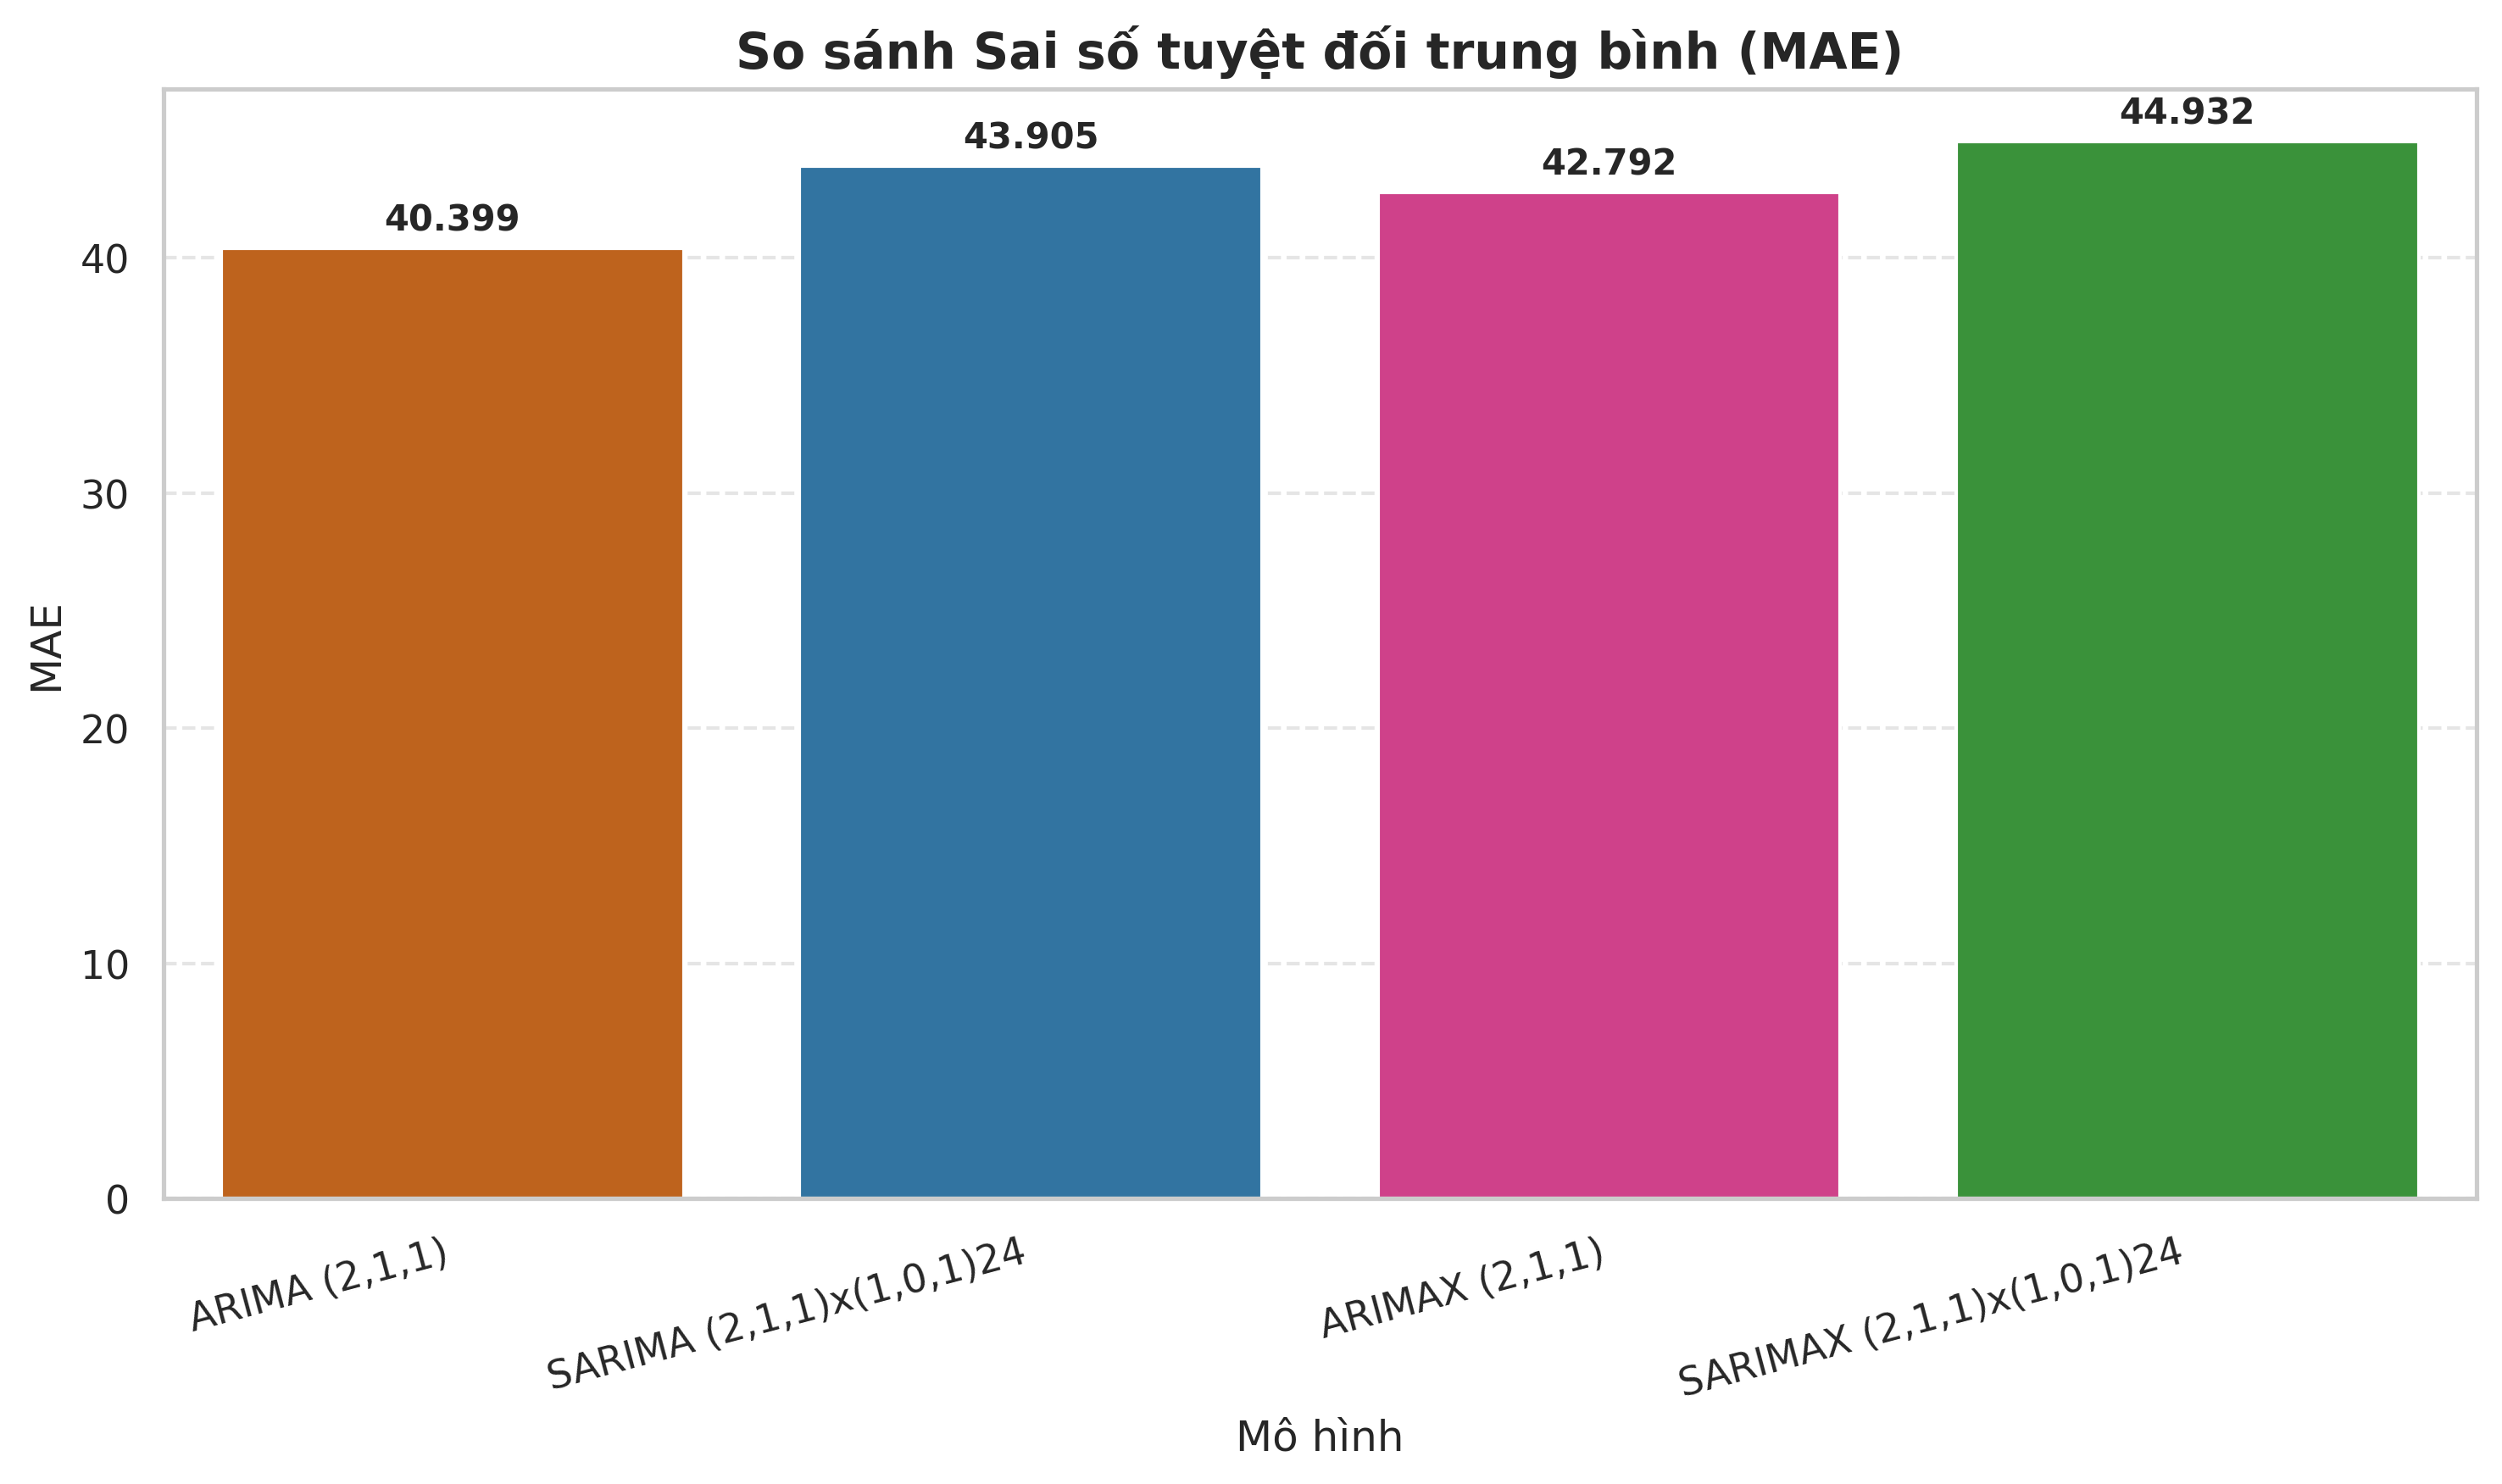

In [52]:
metrics_df = df_comparison_updated.copy()

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

bars = sns.barplot(
    x='Model', y='MAE',
    data=metrics_df,
    palette=model_palette if 'model_palette' in globals() else [
        colors['ARIMA'], colors['SARIMA'],
        colors['ARIMAX'], colors['SARIMAX']
    ],
    hue='Model', legend=False, ax=ax
)

for bar in bars.patches:
    height = bar.get_height()
    ax.annotate(
        f'{height:.3f}',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha='center', va='bottom',
        fontsize=10, fontweight='bold'
    )

ax.set_title("So sánh Sai số tuyệt đối trung bình (MAE)", fontsize=14, fontweight='bold')
ax.set_ylabel("MAE", fontsize=12)
ax.set_xlabel("Mô hình", fontsize=12)
ax.grid(True, axis='y', linestyle='--', alpha=0.5)
ax.set_xticks(range(len(metrics_df['Model'])))
ax.set_xticklabels(metrics_df['Model'], rotation=15, ha='right')

plt.tight_layout()
fig.savefig(f"{vis_dir}/05_MAE_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

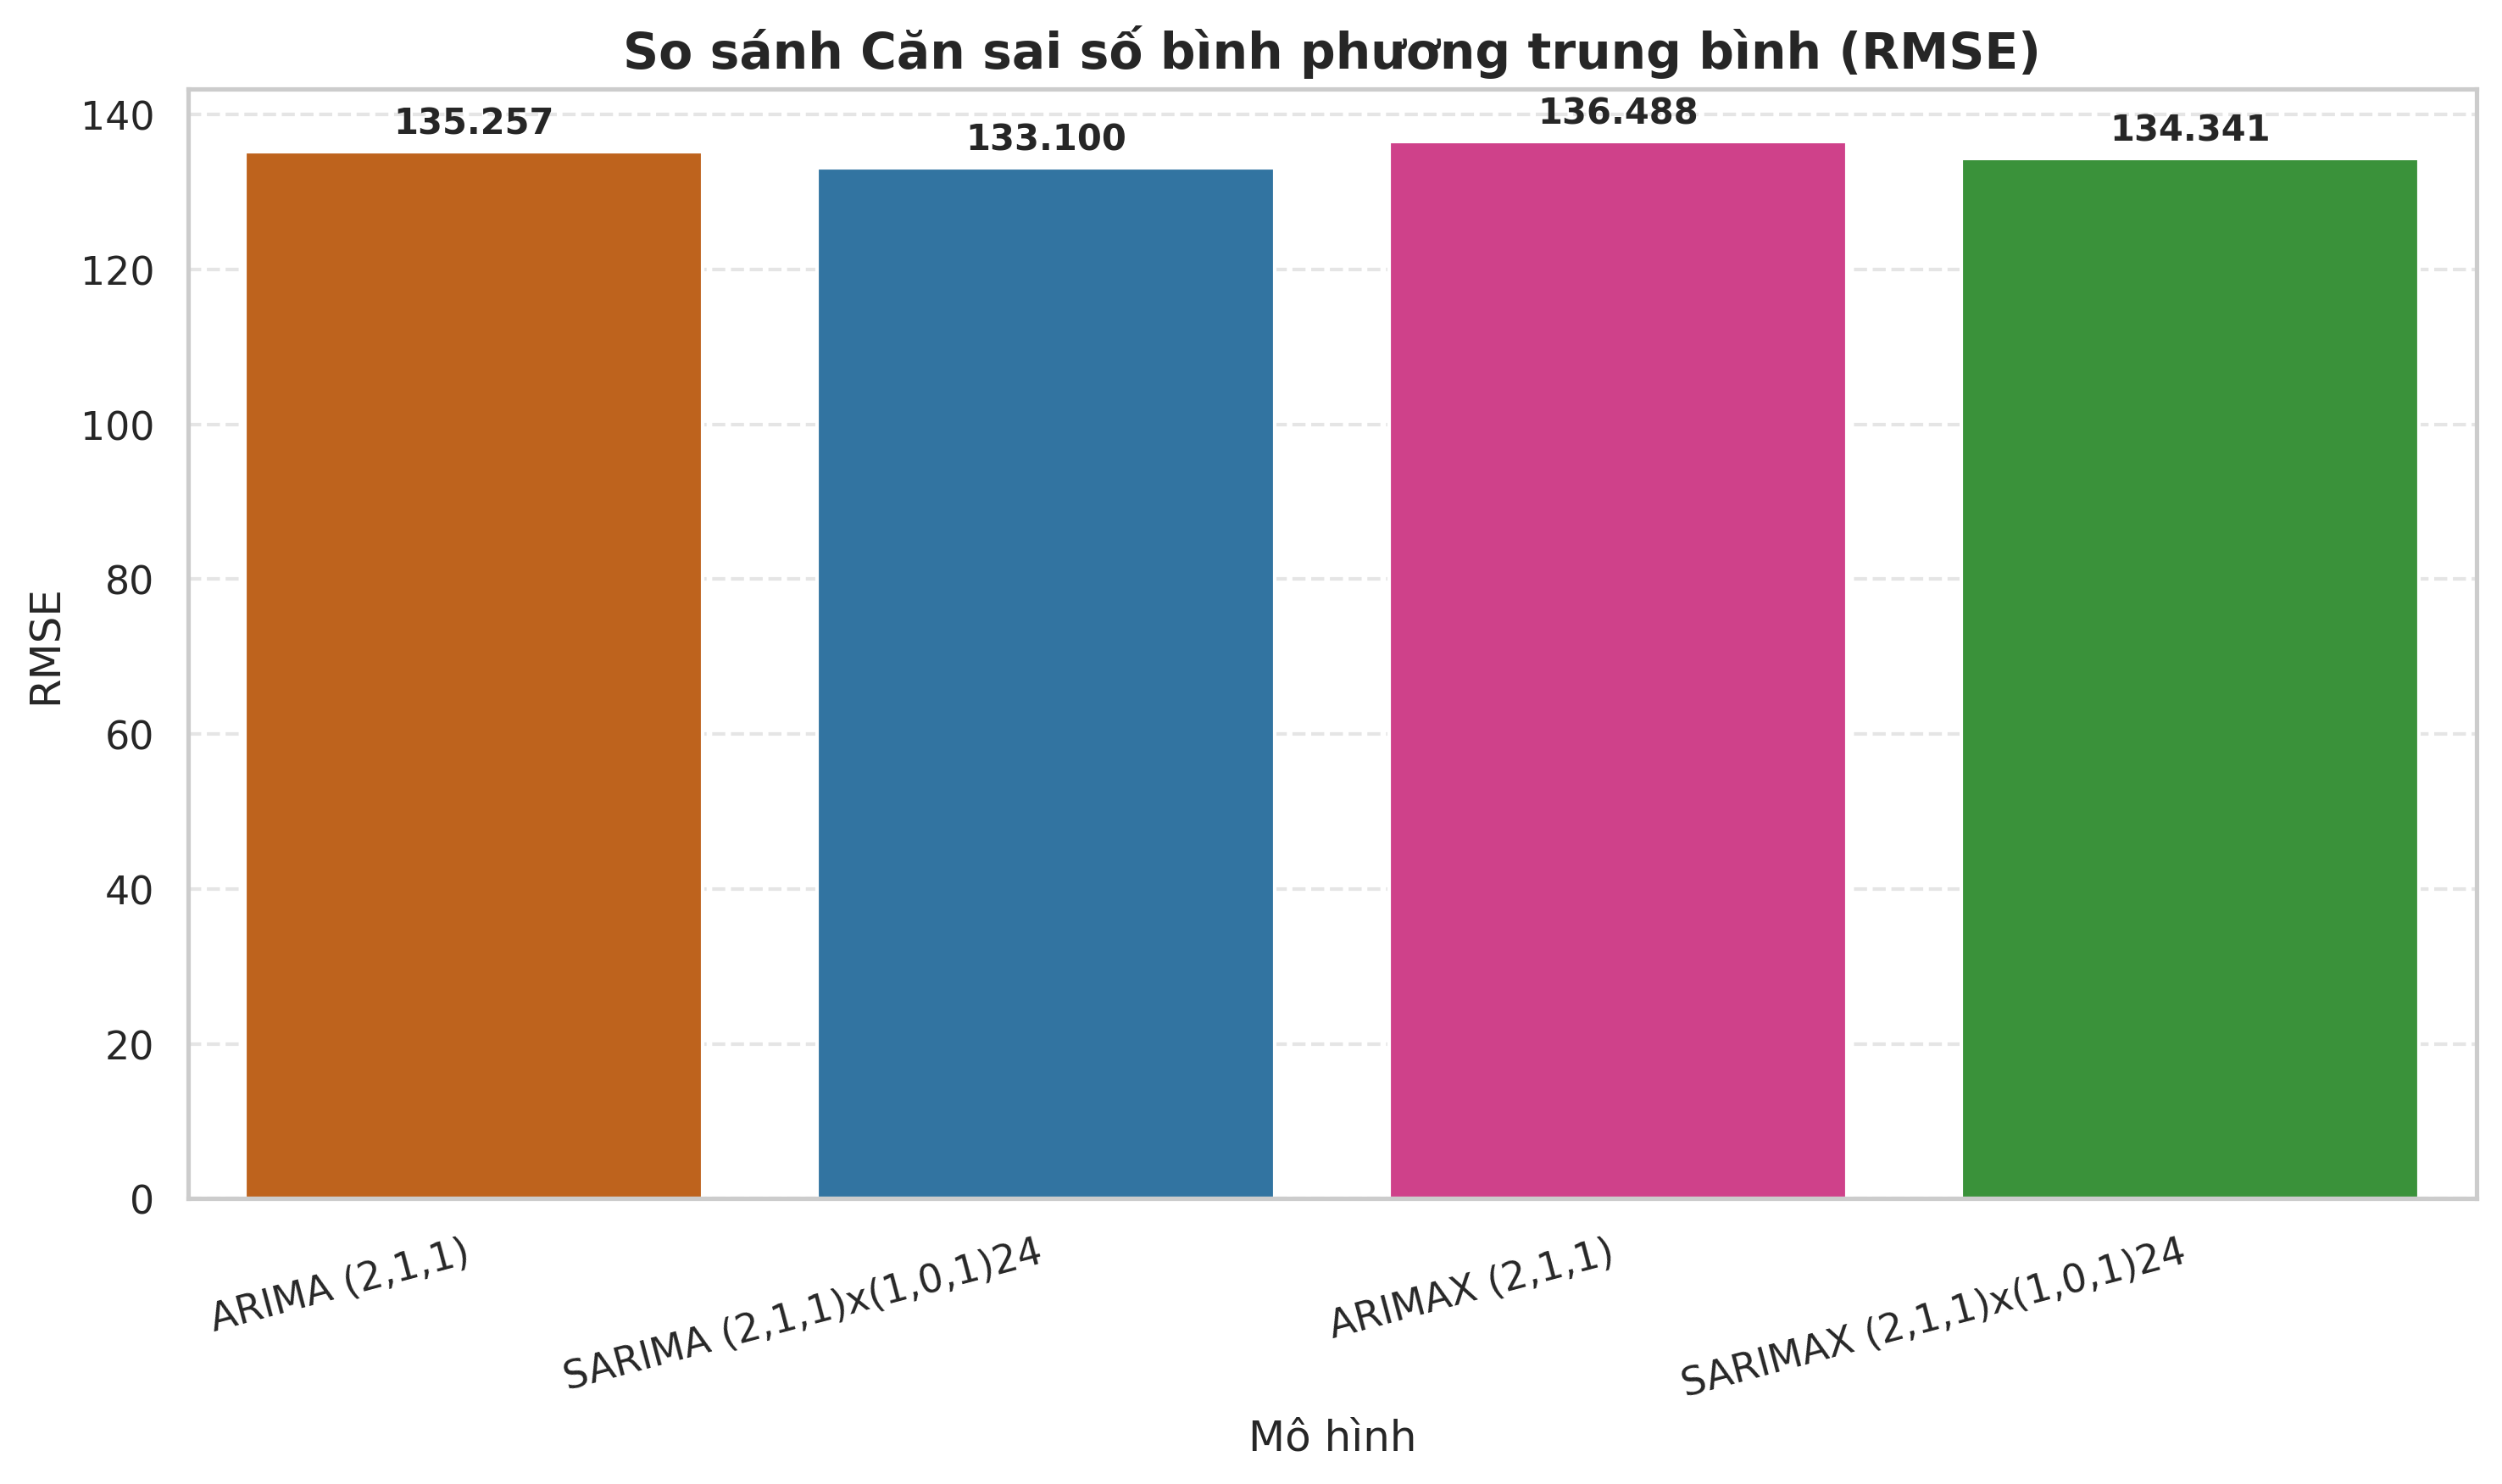

In [53]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

bars = sns.barplot(
    x='Model', y='RMSE',
    data=metrics_df,
    palette=[
        colors['ARIMA'], colors['SARIMA'],
        colors['ARIMAX'], colors['SARIMAX']
    ],
    hue='Model', legend=False, ax=ax
)

for bar in bars.patches:
    height = bar.get_height()
    ax.annotate(
        f'{height:.3f}',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha='center', va='bottom',
        fontsize=10, fontweight='bold'
    )

ax.set_title("So sánh Căn sai số bình phương trung bình (RMSE)", fontsize=14, fontweight='bold')
ax.set_ylabel("RMSE", fontsize=12)
ax.set_xlabel("Mô hình", fontsize=12)
ax.grid(True, axis='y', linestyle='--', alpha=0.5)
ax.set_xticks(range(len(metrics_df['Model'])))
ax.set_xticklabels(metrics_df['Model'], rotation=15, ha='right')

plt.tight_layout()
fig.savefig(f"{vis_dir}/06_RMSE_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

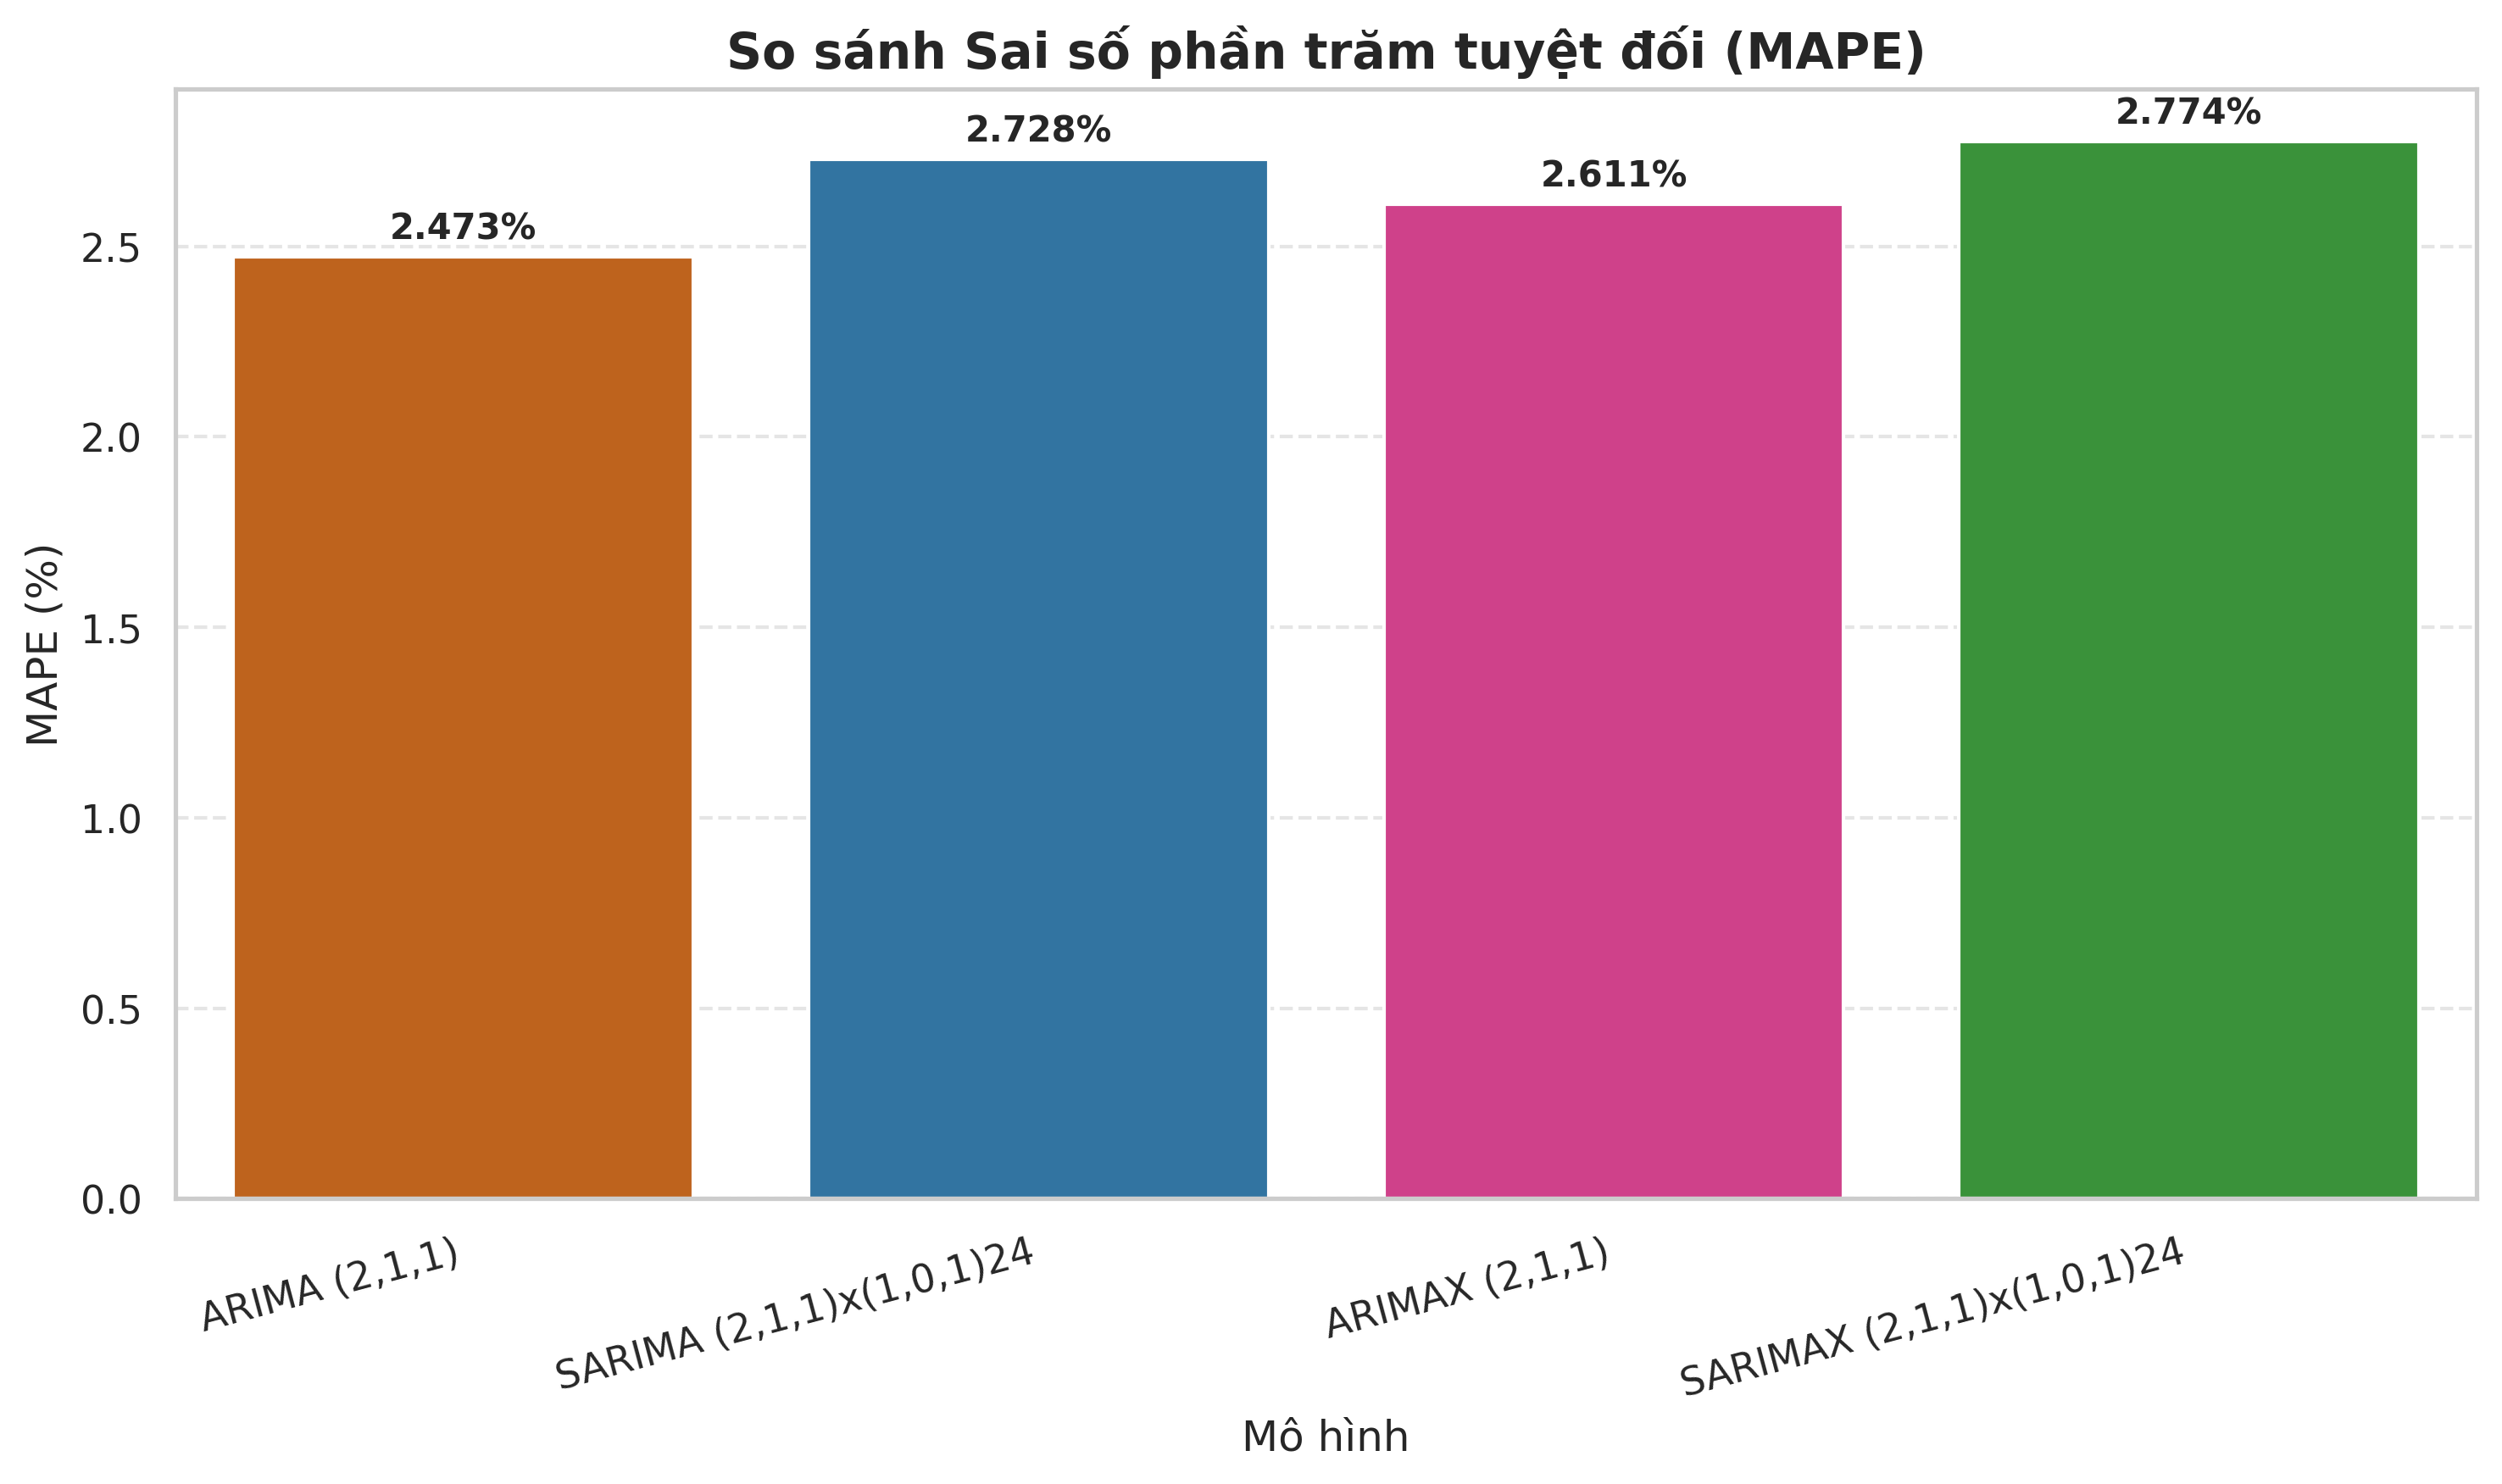

In [54]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

bars = sns.barplot(
    x='Model', y='MAPE (%)',
    data=metrics_df,
    palette=[
        colors['ARIMA'], colors['SARIMA'],
        colors['ARIMAX'], colors['SARIMAX']
    ],
    hue='Model', legend=False, ax=ax
)

for bar in bars.patches:
    height = bar.get_height()
    ax.annotate(
        f'{height:.3f}%',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha='center', va='bottom',
        fontsize=10, fontweight='bold'
    )

ax.set_title("So sánh Sai số phần trăm tuyệt đối (MAPE)", fontsize=14, fontweight='bold')
ax.set_ylabel("MAPE (%)", fontsize=12)
ax.set_xlabel("Mô hình", fontsize=12)
ax.grid(True, axis='y', linestyle='--', alpha=0.5)
ax.set_xticks(range(len(metrics_df['Model'])))
ax.set_xticklabels(metrics_df['Model'], rotation=15, ha='right')

plt.tight_layout()
fig.savefig(f"{vis_dir}/07_MAPE_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

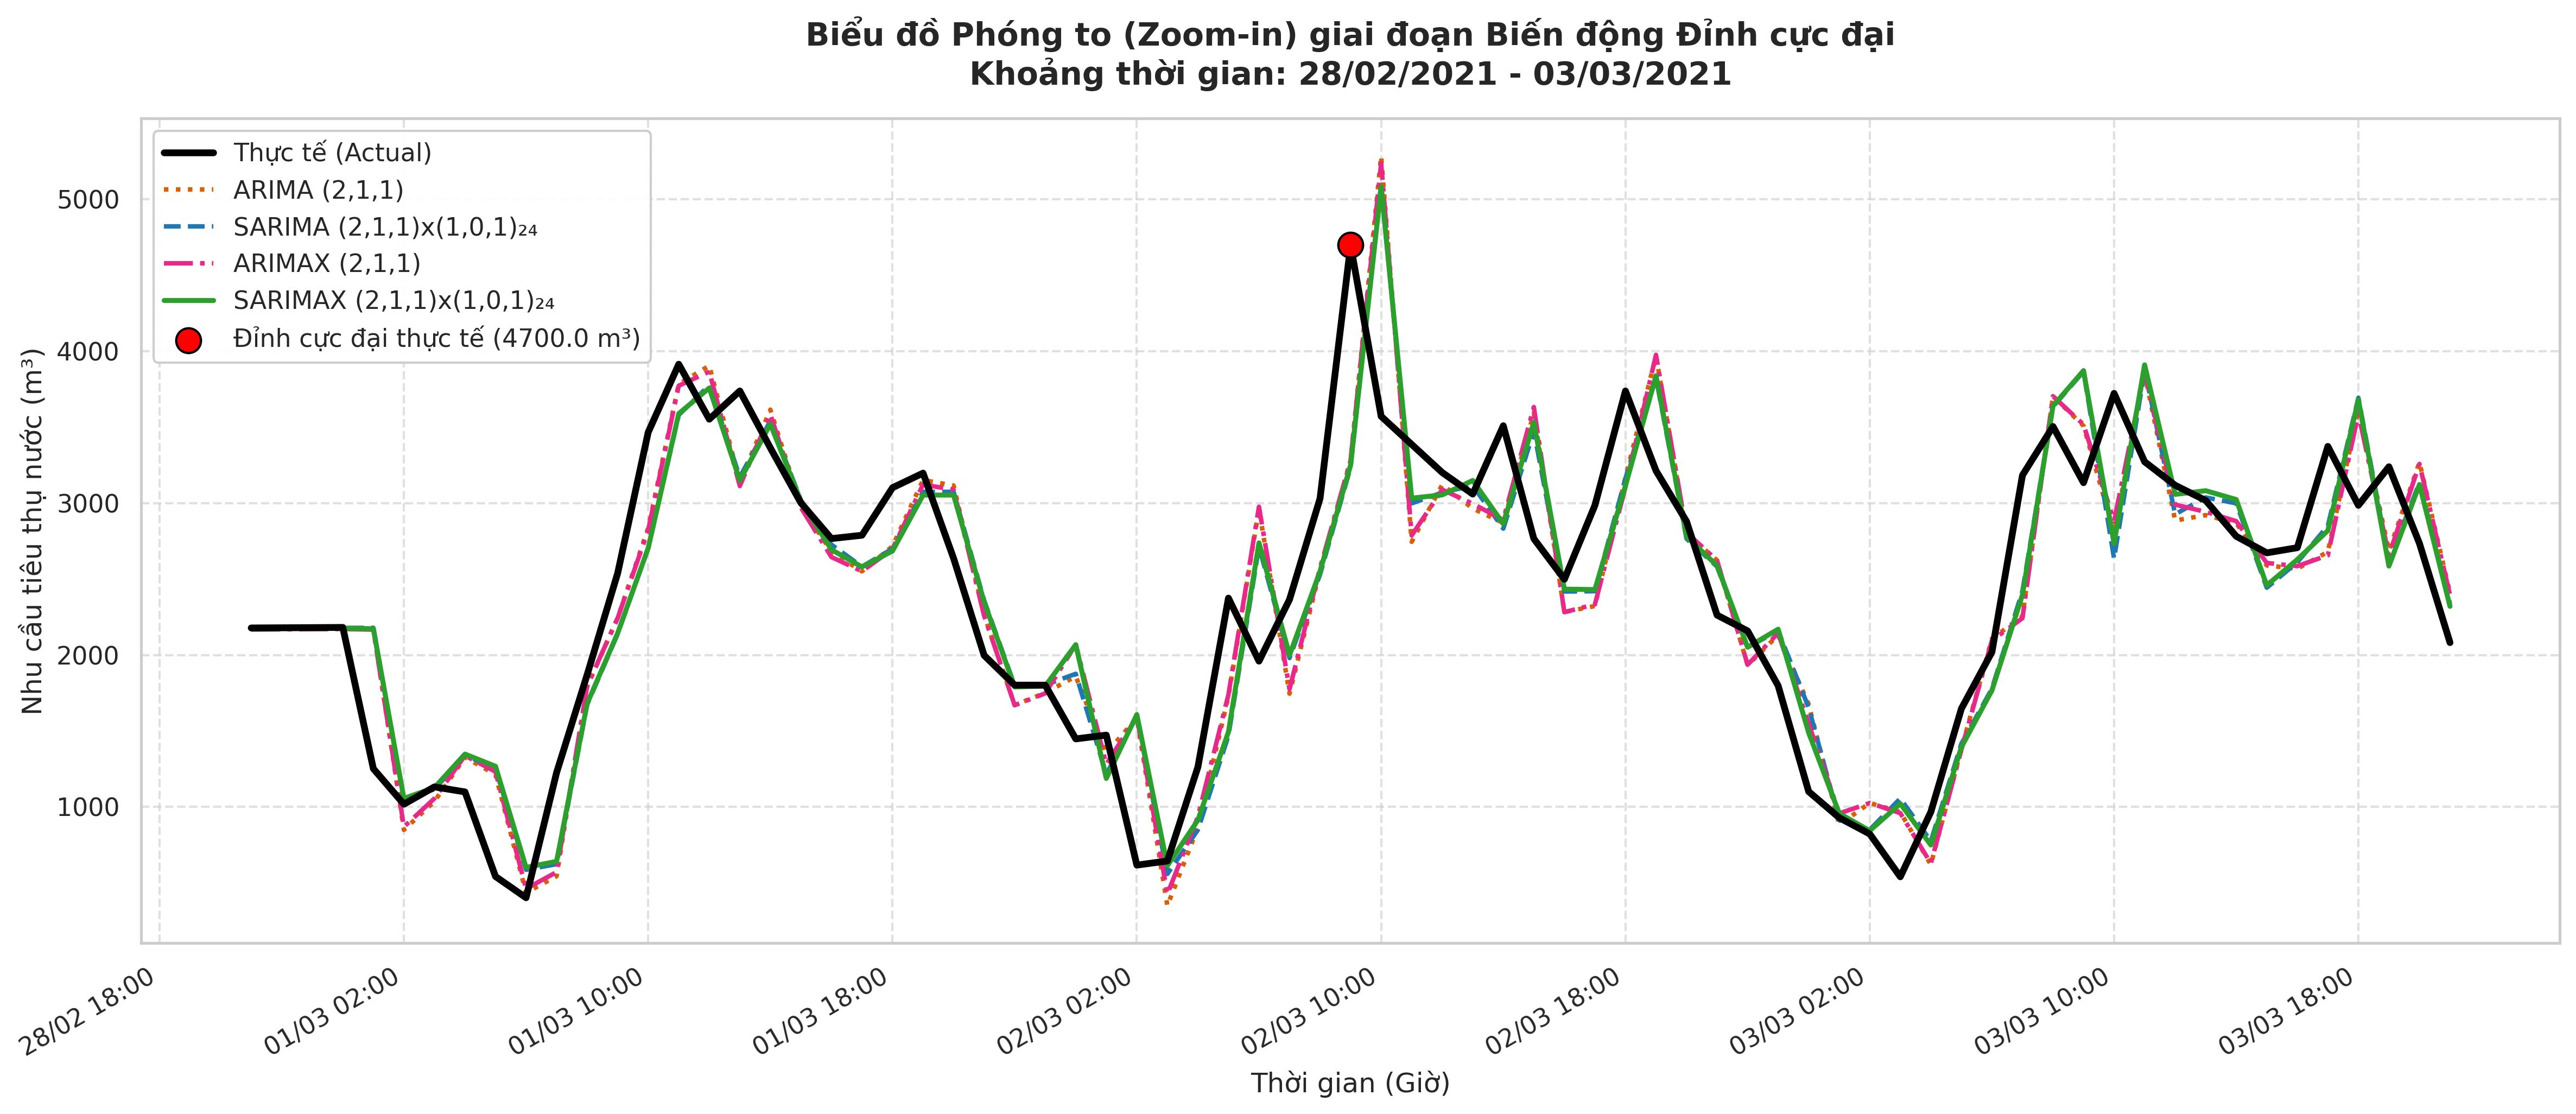

In [55]:
# =========================================================================
# 6. BIỂU ĐỒ PHÓNG TO KHOẢNG THỜI GIAN CÓ BIẾN ĐỘNG CỰC ĐẠI
# =========================================================================
# Xác định tự động mốc thời gian có nhu cầu tiêu thụ nước thực tế cao nhất trong tập Test
peak_timestamp = test_data.idxmax()

# Cắt khoảng zoom-in xung quanh đỉnh cực đại (trước và sau 36 giờ, tổng cộng 72 giờ)
zoom_start = peak_timestamp - pd.Timedelta(hours=36)
zoom_end = peak_timestamp + pd.Timedelta(hours=36)

zoom_actual = test_data.loc[zoom_start:zoom_end]
zoom_arima = predictions_series.loc[zoom_start:zoom_end]
zoom_sarima = sarima_predictions_series.loc[zoom_start:zoom_end]
zoom_arimax = arimax_predictions_series.loc[zoom_start:zoom_end]
zoom_sarimax = sarimax_predictions_series.loc[zoom_start:zoom_end]

fig6, ax6 = plt.subplots(figsize=(16, 7), dpi=300)

# Vẽ dữ liệu phóng to
ax6.plot(zoom_actual, label='Thực tế (Actual)', color=colors['Actual'], linewidth=3.0, zorder=10)
ax6.plot(zoom_arima, label='ARIMA (2,1,1)', color=colors['ARIMA'], linestyle=':', linewidth=2.0)
ax6.plot(zoom_sarima, label='SARIMA (2,1,1)x(1,0,1)₂₄', color=colors['SARIMA'], linestyle='--', linewidth=2.0)
ax6.plot(zoom_arimax, label='ARIMAX (2,1,1)', color=colors['ARIMAX'], linestyle='-.', linewidth=2.0)
ax6.plot(zoom_sarimax, label='SARIMAX (2,1,1)x(1,0,1)₂₄', color=colors['SARIMAX'], linestyle='-', linewidth=2.2)

# Đánh dấu điểm đỉnh tiêu thụ thực tế lớn nhất
ax6.scatter(peak_timestamp, test_data.max(), color='red', s=120, edgecolors='black', zorder=12,
            label=f'Đỉnh cực đại thực tế ({test_data.max():.1f} m³)')

ax6.set_title(f"Biểu đồ Phóng to (Zoom-in) giai đoạn Biến động Đỉnh cực đại\nKhoảng thời gian: {zoom_start.strftime('%d/%m/%Y')} - {zoom_end.strftime('%d/%m/%Y')}",
              fontsize=14, fontweight='bold', pad=15)
ax6.set_xlabel("Thời gian (Giờ)", fontsize=12)
ax6.set_ylabel("Nhu cầu tiêu thụ nước (m³)", fontsize=12)

ax6.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:00'))
ax6.xaxis.set_major_locator(mdates.HourLocator(interval=8))
plt.xticks(rotation=30, ha='right')

ax6.grid(True, linestyle='--', alpha=0.6)
ax6.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.95, fontsize=11)

plt.tight_layout()
fig6.savefig(f"{vis_dir}/06_zoomed_forecast.png", dpi=300, bbox_inches='tight')
plt.show()

## PHẦN 24. ĐÓNG GÓI VÀ LƯU TRỮ TOÀN BỘ KẾT QUẢ NGHIÊN CỨU MỞ RỘNG

Chúng ta lưu trữ toàn bộ các mô hình nâng cao, bảng so sánh đối chứng, biểu đồ so sánh chất lượng, và đóng gói vào tệp zip mới.

In [56]:
import os
import shutil
import pandas as pd
from google.colab import files
from statsmodels.tsa.statespace.sarimax import SARIMAX

advanced_output_dir = 'Advanced_Water_Forecasting_Results'
os.makedirs(advanced_output_dir, exist_ok=True)

# 1. Khôi phục df_comparison từ df_comparison_updated nếu tồn tại
df_comp_to_save = globals().get('df_comparison_updated', globals().get('df_comparison', None))
if df_comp_to_save is None:
    raise ValueError("Không tìm thấy bảng so sánh hiệu năng các mô hình (df_comparison_updated).")

# 2. Sao chép các biểu đồ đã được lưu trong thư mục 'visualization_results' vào thư mục đóng gói
vis_dir = 'visualization_results'
if os.path.exists(vis_dir):
    for file_name in os.listdir(vis_dir):
        shutil.copy(os.path.join(vis_dir, file_name), os.path.join(advanced_output_dir, file_name))
else:
    print("Cảnh báo: Thư mục visualization_results không tồn tại.")

# 3. Khôi phục hoặc huấn luyện nhanh lại mô hình SARIMAX để lấy thông tin tóm tắt (summary)
sarimax_fit_model = globals().get('sarimax_fit', None)
if sarimax_fit_model is None:
    print("Đang tái huấn luyện nhanh mô hình SARIMAX tối ưu để xuất thông tin cấu trúc...")
    # Khôi phục các biến cần thiết từ bộ nhớ hoặc file
    if 'train_data' not in globals() or 'X_train' not in globals():
        cleaned_df = pd.read_csv('ARIMA_Water_Forecasting/cleaned_data.csv', parse_dates=True, index_col='DateTime')
        y_temp = cleaned_df['Consumption']
        n_temp = len(y_temp)
        train_size_temp = int(n_temp * 0.70)
        train_data = y_temp.iloc[:train_size_temp]

        df_raw = pd.read_csv('waterconsumption_rawdata.csv')
        start_time_raw = df_raw['Time'].str.split('-').str[0].str.strip()
        df_raw['DateTime'] = pd.to_datetime(df_raw['Date'] + ' ' + start_time_raw, format='%d/%m/%Y %H:%M', errors='coerce')
        df_raw = df_raw.dropna(subset=['DateTime']).sort_values(by='DateTime').set_index('DateTime')
        exog_cols = ['Temperature', 'Rain', 'Sun']
        X_all = df_raw[exog_cols].copy().asfreq('h').interpolate(method='linear').ffill().bfill()
        X_train = X_all.loc[train_data.index]

    sarimax_model = SARIMAX(train_data,
                            order=(2, 1, 1),
                            seasonal_order=(1, 0, 1, 24),
                            exog=X_train,
                            enforce_stationarity=False,
                            enforce_invertibility=False)
    sarimax_fit_model = sarimax_model.fit(disp=False)
    globals()['sarimax_fit'] = sarimax_fit_model

# 4. Lưu kết quả dự báo chi tiết của toàn bộ các mô hình
all_forecast_results = pd.DataFrame({
    'Actual_Test': test_data,
    'ARIMA_Predicted': predictions_series,
    'SARIMA_Predicted': sarima_predictions_series,
    'ARIMAX_Predicted': arimax_predictions_series,
    'SARIMAX_Predicted': sarimax_predictions_series
})
all_forecast_results.to_csv(f"{advanced_output_dir}/comprehensive_forecast_results.csv")
df_comp_to_save.to_csv(f"{advanced_output_dir}/model_performance_comparison.csv", index=False)

# 5. Lưu thông tin tóm tắt cấu trúc mô hình SARIMAX tối ưu
with open(f"{advanced_output_dir}/sarimax_model_summary.txt", "w", encoding="utf-8") as f:
    f.write(sarimax_fit_model.summary().as_text())

# 6. Nén thư mục kết quả nâng cao thành ZIP
shutil.make_archive(advanced_output_dir, 'zip', advanced_output_dir)
print(f"Đã tạo thành công tệp nén lưu trữ kết quả nghiên cứu nâng cao: {advanced_output_dir}.zip")

# 7. Tải tệp ZIP về máy
files.download(f"{advanced_output_dir}.zip")

Đã tạo thành công tệp nén lưu trữ kết quả nghiên cứu nâng cao: Advanced_Water_Forecasting_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>